<a href="https://colab.research.google.com/github/theyuvrajtayal21-design/quantum-readout-drift-prediction/blob/main/Models_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np

# Load the dataset (change the path if necessary)
df = pd.read_csv("/content/quantum_readout_error_cleaned.csv")

# Basic structural inspection
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst five records:")
display(df.head())

print("\nDataset information:")
df.info()


/tmp/ipykernel_1011/2260984426.py:5: DtypeWarning: Columns (7,14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("/content/quantum_readout_error_cleaned.csv")


Dataset shape: (594198, 15)

Column names:
['backend', 'qubit_a', 'readout_error', 'calibrated_time', 'observed_time', 'calibration_age_seconds', 'calibration_age_seconds_recomputed', 'snapshot_update_time', 'property', 'property_family', 'unit', 'scope', 'is_new_measurement', 'is_failure_ceiling', 'chipwide_recal_event_id']

Data types:
backend                                object
qubit_a                                 int64
readout_error                         float64
calibrated_time                        object
observed_time                          object
calibration_age_seconds               float64
calibration_age_seconds_recomputed    float64
snapshot_update_time                   object
property                               object
property_family                        object
unit                                  float64
scope                                  object
is_new_measurement                       bool
is_failure_ceiling                       bool
chipwide_recal_e

,backend,qubit_a,readout_error,calibrated_time,observed_time,calibration_age_seconds,calibration_age_seconds_recomputed,snapshot_update_time,property,property_family,unit,scope,is_new_measurement,is_failure_ceiling,chipwide_recal_event_id
0,ibm_fez,0,0.046387,2026-01-31T13:19:17Z,2026-01-31T17:05:03.496046Z,13546.496046,13546.496046,2026-01-31T15:17:50Z,readout_error,readout_error,NaN,qubit,True,False,NaN
1,ibm_fez,0,0.077148,2026-01-31T22:41:04Z,2026-01-31T23:37:03.790182Z,3359.790182,3359.790182,2026-01-31T23:19:51Z,readout_error,readout_error,NaN,qubit,True,False,NaN
2,ibm_fez,0,0.058960,2026-02-01T02:21:12Z,2026-02-01T03:32:29.550201Z,4277.550201,4277.550201,2026-02-01T02:57:41Z,readout_error,readout_error,NaN,qubit,True,False,NaN
3,ibm_fez,0,0.067139,2026-02-01T05:43:33Z,2026-02-01T06:45:31.923044Z,3718.923044,3718.923044,2026-02-01T05:49:44Z,readout_error,readout_error,NaN,qubit,True,False,NaN
4,ibm_fez,0,0.052002,2026-02-01T22:16:07Z,2026-02-01T22:40:18.462087Z,1451.462087,1451.462087,2026-02-01T22:17:04Z,readout_error,readout_error,NaN,qubit,True,False,NaN



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 594198 entries, 0 to 594197
Data columns (total 15 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   backend                             594198 non-null  object 
 1   qubit_a                             594198 non-null  int64  
 2   readout_error                       594198 non-null  float64
 3   calibrated_time                     594198 non-null  object 
 4   observed_time                       594198 non-null  object 
 5   calibration_age_seconds             594198 non-null  float64
 6   calibration_age_seconds_recomputed  594198 non-null  float64
 7   snapshot_update_time                562747 non-null  object 
 8   property                            594198 non-null  object 
 9   property_family                     594198 non-null  object 
 10  unit                                0 non-null       float64
 11  scop

In [ ]:
# Check missing values
print("Missing values:")
display(df.isnull().sum())

# Check duplicate records
print("\nExact duplicate rows:", df.duplicated().sum())

# Check target variable
print("\nReadout error statistics:")
display(df["readout_error"].describe())

# Check invalid target values
print("\nValues outside [0, 1]:",
      ((df["readout_error"] < 0) |
       (df["readout_error"] > 1)).sum())

# Check backend distribution
print("\nRecords per backend:")
display(df["backend"].value_counts())

# Check unique qubits per backend
print("\nUnique qubits per backend:")
display(df.groupby("backend")["qubit_a"].nunique())

Missing values:


,0
backend,0
qubit_a,0
readout_error,0
calibrated_time,0
observed_time,0
calibration_age_seconds,0
calibration_age_seconds_recomputed,0
snapshot_update_time,31451
property,0
property_family,0



Exact duplicate rows: 0

Readout error statistics:


,readout_error
count,594198.000000
mean,0.029311
std,0.062010
min,0.000488
25%,0.007202
50%,0.011719
75%,0.023926
max,0.653564



Values outside [0, 1]: 0

Records per backend:


,count
backend,
ibm_fez,207170
ibm_marrakesh,206110
ibm_kingston,149467
ibm_torino,31451



Unique qubits per backend:


,qubit_a
backend,
ibm_fez,156
ibm_kingston,156
ibm_marrakesh,156
ibm_torino,133


In [ ]:
# Display actual records in a readable text format
print(df.head(20).to_string(index=False))

backend  qubit_a  readout_error      calibrated_time               observed_time  calibration_age_seconds  calibration_age_seconds_recomputed snapshot_update_time      property property_family  unit scope  is_new_measurement  is_failure_ceiling chipwide_recal_event_id
ibm_fez        0       0.046387 2026-01-31T13:19:17Z 2026-01-31T17:05:03.496046Z             13546.496046                        13546.496046 2026-01-31T15:17:50Z readout_error   readout_error   NaN qubit                True               False                     NaN
ibm_fez        0       0.077148 2026-01-31T22:41:04Z 2026-01-31T23:37:03.790182Z              3359.790182                         3359.790182 2026-01-31T23:19:51Z readout_error   readout_error   NaN qubit                True               False                     NaN
ibm_fez        0       0.058960 2026-02-01T02:21:12Z 2026-02-01T03:32:29.550201Z              4277.550201                         4277.550201 2026-02-01T02:57:41Z readout_error   readout_error 

In [ ]:
print(df.iloc[100].to_dict())

{'backend': 'ibm_fez', 'qubit_a': 0, 'readout_error': 0.02294921875, 'calibrated_time': '2026-02-22T19:28:11Z', 'observed_time': '2026-02-22T20:42:19.531332Z', 'calibration_age_seconds': 4448.531332, 'calibration_age_seconds_recomputed': 4448.531332, 'snapshot_update_time': '2026-02-22T20:15:08Z', 'property': 'readout_error', 'property_family': 'readout_error', 'unit': nan, 'scope': 'qubit', 'is_new_measurement': True, 'is_failure_ceiling': False, 'chipwide_recal_event_id': nan}


In [ ]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

Rows: 594,198
Columns: 15


In [ ]:

# Step 4: Understand the dataset's backend and time structure

# Convert timestamps into datetime format
for col in ["calibrated_time", "observed_time", "snapshot_update_time"]:
    df[col] = pd.to_datetime(df[col], errors="coerce", utc=True)

# 1. Distribution of observations across quantum processors
print("RECORDS PER BACKEND")
display(df["backend"].value_counts().to_frame("record_count"))

# 2. Number of distinct qubits on each processor
print("\nUNIQUE QUBITS PER BACKEND")
display(df.groupby("backend")["qubit_a"].nunique().to_frame("unique_qubits"))

# 3. Number of observations per backend-qubit combination
print("\nOBSERVATIONS PER BACKEND-QUBIT")
series_counts = (
    df.groupby(["backend", "qubit_a"])
      .size()
      .reset_index(name="observations")
)

display(series_counts.sort_values("observations", ascending=False).head(20))

# 4. Overall observation period
print("\nOBSERVATION PERIOD")
print("Start:", df["observed_time"].min())
print("End:", df["observed_time"].max())

# 5. Compare original and recomputed calibration age
age_diff = (
    df["calibration_age_seconds"] -
    df["calibration_age_seconds_recomputed"]
).abs()

print("\nCALIBRATION AGE DIFFERENCE")
display(age_diff.describe())

print("Differences greater than 1 second:", (age_diff > 1).sum())


RECORDS PER BACKEND


,record_count
backend,
ibm_fez,207170
ibm_marrakesh,206110
ibm_kingston,149467
ibm_torino,31451



UNIQUE QUBITS PER BACKEND


,unique_qubits
backend,
ibm_fez,156
ibm_kingston,156
ibm_marrakesh,156
ibm_torino,133



OBSERVATIONS PER BACKEND-QUBIT


,backend,qubit_a,observations
72,ibm_fez,72,1346
4,ibm_fez,4,1346
0,ibm_fez,0,1345
99,ibm_fez,99,1343
83,ibm_fez,83,1343
51,ibm_fez,51,1343
65,ibm_fez,65,1343
11,ibm_fez,11,1343
53,ibm_fez,53,1342
93,ibm_fez,93,1342



OBSERVATION PERIOD
Start: 2026-01-31 17:05:03.496046+00:00
End: 2026-05-20 11:08:08.651246+00:00

CALIBRATION AGE DIFFERENCE


,0
count,594198.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


Differences greater than 1 second: 0


In [ ]:

# Step 5: Examine time intervals between observations

# Sort each backend-qubit series chronologically
df = df.sort_values(
    ["backend", "qubit_a", "observed_time"]
).copy()

# Calculate the time difference between consecutive observations
df["time_gap_hours"] = (
    df.groupby(["backend", "qubit_a"])["observed_time"]
      .diff()
      .dt.total_seconds() / 3600
)

print("TIME GAP DISTRIBUTION (HOURS)")
display(df["time_gap_hours"].describe())

# Inspect the distribution of time intervals
print("\nCOMMON TIME INTERVALS (ROUNDED TO MINUTES)")
display(
    (df["time_gap_hours"] * 60)
    .round()
    .value_counts()
    .head(15)
)

# Check the number of observations in each backend-qubit series
print("\nSERIES LENGTH SUMMARY")
display(
    df.groupby(["backend", "qubit_a"])
      .size()
      .describe()
)

# Inspect one example series
example = df[
    (df["backend"] == "ibm_fez") &
    (df["qubit_a"] == 0)
].sort_values("observed_time")

display(
    example[[
        "backend",
        "qubit_a",
        "observed_time",
        "readout_error",
        "calibration_age_seconds"
    ]].head(15)
)


TIME GAP DISTRIBUTION (HOURS)


,time_gap_hours
count,253440.000000
mean,4.924508
std,9.372565
min,0.000000
25%,2.994515
50%,3.817165
75%,4.782819
max,318.485262



COMMON TIME INTERVALS (ROUNDED TO MINUTES)


,count
time_gap_hours,
237.0,3453
239.0,2786
208.0,2730
238.0,2673
230.0,2595
240.0,2574
241.0,2560
207.0,2483
206.0,2481



SERIES LENGTH SUMMARY


,0
count,601.000000
mean,988.682196
std,429.426909
min,225.000000
25%,949.000000
50%,1308.000000
75%,1325.000000
max,1346.000000


,backend,qubit_a,observed_time,readout_error,calibration_age_seconds
0,ibm_fez,0,2026-01-31 17:05:03.496046+00:00,0.046387,13546.496046
1,ibm_fez,0,2026-01-31 23:37:03.790182+00:00,0.077148,3359.790182
2,ibm_fez,0,2026-02-01 03:32:29.550201+00:00,0.058960,4277.550201
3,ibm_fez,0,2026-02-01 06:45:31.923044+00:00,0.067139,3718.923044
4,ibm_fez,0,2026-02-01 22:40:18.462087+00:00,0.052002,1451.462087
5,ibm_fez,0,2026-02-02 02:59:02.163736+00:00,0.050293,7274.163736
6,ibm_fez,0,2026-02-02 07:21:00.621079+00:00,0.059937,5896.621079
7,ibm_fez,0,2026-02-02 10:45:07.465189+00:00,0.067383,5186.465189
8,ibm_fez,0,2026-02-02 14:14:32.118692+00:00,0.065186,4382.118692
9,ibm_fez,0,2026-02-02 18:45:16.910492+00:00,0.074951,8051.910492


In [ ]:

# Step 6: Verify timestamp parsing completeness

print("TOTAL ROWS:", len(df))

print("\nMISSING OBSERVATION TIMESTAMPS:")
print(df["observed_time"].isna().sum())

print("\nVALID OBSERVATION TIMESTAMPS:")
print(df["observed_time"].notna().sum())

# Inspect original timestamp strings if available
print("\nSAMPLE TIMESTAMP VALUES:")
display(df["observed_time"].head(15))

# Inspect the number of valid calculated gaps
print("\nVALID TIME GAPS:")
print(df["time_gap_hours"].notna().sum())

# Check missing timestamps by backend
print("\nMISSING TIMESTAMPS BY BACKEND:")
display(df.groupby("backend")["observed_time"].apply(
    lambda x: x.isna().sum()
))


TOTAL ROWS: 594198

MISSING OBSERVATION TIMESTAMPS:
340157

VALID OBSERVATION TIMESTAMPS:
254041

SAMPLE TIMESTAMP VALUES:


,observed_time
0,2026-01-31 17:05:03.496046+00:00
1,2026-01-31 23:37:03.790182+00:00
2,2026-02-01 03:32:29.550201+00:00
3,2026-02-01 06:45:31.923044+00:00
4,2026-02-01 22:40:18.462087+00:00
5,2026-02-02 02:59:02.163736+00:00
6,2026-02-02 07:21:00.621079+00:00
7,2026-02-02 10:45:07.465189+00:00
8,2026-02-02 14:14:32.118692+00:00
9,2026-02-02 18:45:16.910492+00:00



VALID TIME GAPS:
253440

MISSING TIMESTAMPS BY BACKEND:


,observed_time
backend,
ibm_fez,119775
ibm_kingston,100436
ibm_marrakesh,119946
ibm_torino,0


In [ ]:
df["observed_time"] = pd.to_datetime(
    df["observed_time"],
    format="mixed",
    errors="coerce",
    utc=True
)

In [ ]:
# Reload the original CSV without converting timestamp strings

CSV_PATH = "/content/quantum_readout_error_cleaned.csv"  # Fixed the filename here

raw_df = pd.read_csv(
    CSV_PATH,
    dtype={"observed_time": "string"}
)

# Try mixed-format timestamp parsing
parsed_time = pd.to_datetime(
    raw_df["observed_time"],
    format="mixed",
    errors="coerce",
    utc=True
)

print("TOTAL ROWS:", len(raw_df))
print("Original timestamp strings missing:",
      raw_df["observed_time"].isna().sum())

print("Successfully parsed:", parsed_time.notna().sum())
print("Still unparsed:", parsed_time.isna().sum())

# Inspect examples that failed to parse
failed = raw_df.loc[
    parsed_time.isna() & raw_df["observed_time"].notna(),
    ["backend", "observed_time"]
]

print("\nFAILED TIMESTAMP EXAMPLES:")
display(failed.head(20))

# Check parsing success by backend
check = raw_df[["backend"]].copy()
check["parsed"] = parsed_time.notna()

print("\nPARSING SUCCESS BY BACKEND:")
display(check.groupby("backend")["parsed"].agg(["count", "sum", "mean"]))

/tmp/ipykernel_1011/178583273.py:5: DtypeWarning: Columns (7,14) have mixed types. Specify dtype option on import or set low_memory=False.
  raw_df = pd.read_csv(


TOTAL ROWS: 594198
Original timestamp strings missing: 0
Successfully parsed: 594198
Still unparsed: 0

FAILED TIMESTAMP EXAMPLES:


,backend,observed_time



PARSING SUCCESS BY BACKEND:


,count,sum,mean
backend,,,
ibm_fez,207170,207170,1.0
ibm_kingston,149467,149467,1.0
ibm_marrakesh,206110,206110,1.0
ibm_torino,31451,31451,1.0


In [ ]:

# Restore timestamps using the verified mixed-format parsing

df["observed_time"] = parsed_time

# Parse the other timestamp columns consistently
df["calibrated_time"] = pd.to_datetime(
    raw_df["calibrated_time"],
    format="mixed",
    errors="coerce",
    utc=True
)

df["snapshot_update_time"] = pd.to_datetime(
    raw_df["snapshot_update_time"],
    format="mixed",
    errors="coerce",
    utc=True
)

# Sort observations within each backend-qubit series
df = df.sort_values(
    ["backend", "qubit_a", "observed_time"]
).copy()

# Recalculate elapsed time between consecutive observations
df["time_gap_hours"] = (
    df.groupby(["backend", "qubit_a"])["observed_time"]
      .diff()
      .dt.total_seconds() / 3600
)

print("TOTAL ROWS:", len(df))
print("Missing observation timestamps:",
      df["observed_time"].isna().sum())

print("\nRECALCULATED TIME GAP STATISTICS:")
display(df["time_gap_hours"].describe())

print("\nVALID TIME GAPS:", df["time_gap_hours"].notna().sum())


TOTAL ROWS: 594198
Missing observation timestamps: 0

RECALCULATED TIME GAP STATISTICS:


,time_gap_hours
count,593597.000000
mean,5.479258
std,8.470655
min,0.000000
25%,2.893056
50%,3.953056
75%,5.740784
max,318.485262



VALID TIME GAPS: 593597


In [ ]:

# Step 7: Investigate zero-length and unusually long time gaps

gaps = df["time_gap_hours"].dropna()

# Count observations with identical consecutive timestamps
print("ZERO-HOUR GAPS:", (gaps == 0).sum())

# Count gaps exceeding selected thresholds
for hours in [12, 24, 48, 72, 168]:
    print(f"Gaps exceeding {hours} hours: {(gaps > hours).sum():,}")

# Inspect the largest time gaps
print("\nLARGEST TIME GAPS:")

display(
    df.loc[
        df["time_gap_hours"].nlargest(15).index,
        ["backend", "qubit_a", "observed_time",
         "readout_error", "time_gap_hours"]
    ]
)

# Inspect observations with zero-hour gaps
print("\nZERO-HOUR GAP EXAMPLES:")

zero_gap_rows = df[df["time_gap_hours"] == 0]

display(
    zero_gap_rows[
        ["backend", "qubit_a", "observed_time",
         "readout_error", "calibrated_time"]
    ].head(15)
)


ZERO-HOUR GAPS: 149
Gaps exceeding 12 hours: 34,690
Gaps exceeding 24 hours: 10,916
Gaps exceeding 48 hours: 3,865
Gaps exceeding 72 hours: 1,992
Gaps exceeding 168 hours: 130

LARGEST TIME GAPS:


,backend,qubit_a,observed_time,readout_error,time_gap_hours
577306,ibm_torino,61,2026-03-04 19:17:33.248250+00:00,0.021118,318.485262
590299,ibm_torino,116,2026-03-04 19:17:33.248250+00:00,0.065796,318.485262
563113,ibm_torino,1,2026-03-04 19:17:33.248250+00:00,0.059937,317.782955
563600,ibm_torino,3,2026-03-04 19:17:33.248250+00:00,0.019775,317.782955
564087,ibm_torino,5,2026-03-04 19:17:33.248250+00:00,0.029053,317.782955
564321,ibm_torino,6,2026-03-04 19:17:33.248250+00:00,0.011597,317.782955
564551,ibm_torino,7,2026-03-04 19:17:33.248250+00:00,0.090942,317.782955
564788,ibm_torino,8,2026-03-04 19:17:33.248250+00:00,0.063965,317.782955
565026,ibm_torino,9,2026-03-04 19:17:33.248250+00:00,0.018188,317.782955
565263,ibm_torino,10,2026-03-04 19:17:33.248250+00:00,0.035645,317.782955



ZERO-HOUR GAP EXAMPLES:


,backend,qubit_a,observed_time,readout_error,calibrated_time
268,ibm_fez,0,2026-03-24 09:20:15.970181+00:00,0.012939,2026-03-24 09:12:43+00:00
1614,ibm_fez,1,2026-03-24 09:20:15.970181+00:00,0.027832,2026-03-24 09:12:43+00:00
2949,ibm_fez,2,2026-03-24 09:20:15.970181+00:00,0.010742,2026-03-24 09:12:43+00:00
4289,ibm_fez,3,2026-03-24 09:20:15.970181+00:00,0.042969,2026-03-24 09:12:43+00:00
5626,ibm_fez,4,2026-03-24 09:20:15.970181+00:00,0.009033,2026-03-24 09:12:43+00:00
6973,ibm_fez,5,2026-03-24 09:20:15.970181+00:00,0.086426,2026-03-24 09:12:43+00:00
8305,ibm_fez,6,2026-03-24 09:20:15.970181+00:00,0.022705,2026-03-24 09:12:43+00:00
9619,ibm_fez,7,2026-03-24 09:20:15.970181+00:00,0.039307,2026-03-24 09:12:43+00:00
10947,ibm_fez,8,2026-03-24 09:20:15.970181+00:00,0.004883,2026-03-24 09:12:43+00:00
12277,ibm_fez,9,2026-03-24 09:20:15.970181+00:00,0.010498,2026-03-24 09:12:43+00:00


In [ ]:

# Step 8: Investigate simultaneous observations and calibration events

# Examine zero-gap observations alongside their calibration metadata
zero_gap_rows = df[df["time_gap_hours"] == 0].copy()

print("ZERO-GAP RECORDS:", len(zero_gap_rows))

print("\nCALIBRATION TIMESTAMP DISTRIBUTION:")
display(zero_gap_rows["calibrated_time"].value_counts().head(10))

print("\nUNIQUE CALIBRATION EVENTS:")
print(zero_gap_rows["chipwide_recal_event_id"].nunique(dropna=True))

print("\nZERO-GAP RECORDS BY BACKEND:")
display(zero_gap_rows["backend"].value_counts())

# Inspect whether repeated timestamps have different readout errors
print("\nREPEATED TIMESTAMP GROUPS WITH DIFFERENT TARGET VALUES:")

repeated_groups = (
    df.groupby(["backend", "qubit_a", "observed_time"])
      .agg(
          records=("readout_error", "size"),
          unique_errors=("readout_error", "nunique"),
          unique_calibrations=("calibrated_time", "nunique")
      )
      .query("records > 1")
)

display(repeated_groups.head(20))
print("Total repeated groups:", len(repeated_groups))



ZERO-GAP RECORDS: 149

CALIBRATION TIMESTAMP DISTRIBUTION:


,count
calibrated_time,
2026-03-24 09:12:43+00:00,149



UNIQUE CALIBRATION EVENTS:
0

ZERO-GAP RECORDS BY BACKEND:


,count
backend,
ibm_fez,149



REPEATED TIMESTAMP GROUPS WITH DIFFERENT TARGET VALUES:


records  unique_errors  \
backend qubit_a observed_time                                              
ibm_fez 0       2026-03-24 09:20:15.970181+00:00        2              2   
        1       2026-03-24 09:20:15.970181+00:00        2              2   
        2       2026-03-24 09:20:15.970181+00:00        2              2   
        3       2026-03-24 09:20:15.970181+00:00        2              2   
        4       2026-03-24 09:20:15.970181+00:00        2              2   
        5       2026-03-24 09:20:15.970181+00:00        2              2   
        6       2026-03-24 09:20:15.970181+00:00        2              2   
        7       2026-03-24 09:20:15.970181+00:00        2              2   
        8       2026-03-24 09:20:15.970181+00:00        2              2   
        9       2026-03-24 09:20:15.970181+00:00        2              2   
        10      2026-03-24 09:20:15.970181+00:00        2              2   
        11      2026-03-24 09:20:15.970181+00:00        2              2   
        12      2026-03-24 09:20:15.970181+00:00        2              2   
        13      2026-03-24 09:20:15.970181+00:00        2              2   
        14      2026-03-24 09:20:15.970181+00:00        2              2   
        15      2026-03-24 09:20:15.970181+00:00        2              2   
        16      2026-03-24 09:20:15.970181+00:00        2              2   
        17      2026-03-24 09:20:15.970181+00:00        2              2   
        18      2026-03-24 09:20:15.970181+00:00        2              2   
        19      2026-03-24 09:20:15.970181+00:00        2              2   

                                                  unique_calibrations  
backend qubit_a observed_time                                          
ibm_fez 0       2026-03-24 09:20:15.970181+00:00                    2  
        1       2026-03-24 09:20:15.970181+00:00                    2  
        2       2026-03-24 09:20:15.970181+00:00                    2  
        3       2026-03-24 09:20:15.970181+00:00                    2  
        4       2026-03-24 09:20:15.970181+00:00                    2  
        5       2026-03-24 09:20:15.970181+00:00                    2  
        6       2026-03-24 09:20:15.970181+00:00                    2  
        7       2026-03-24 09:20:15.970181+00:00                    2  
        8       2026-03-24 09:20:15.970181+00:00                    2  
        9       2026-03-24 09:20:15.970181+00:00                    2  
        10      2026-03-24 09:20:15.970181+00:00                    2  
        11      2026-03-24 09:20:15.970181+00:00                    2  
        12      2026-03-24 09:20:15.970181+00:00                    2  
        13      2026-03-24 09:20:15.970181+00:00                    2  
        14      2026-03-24 09:20:15.970181+00:00                    2  
        15      2026-03-24 09:20:15.970181+00:00                    2  
        16      2026-03-24 09:20:15.970181+00:00                    2  
        17      2026-03-24 09:20:15.970181+00:00                    2  
        18      2026-03-24 09:20:15.970181+00:00                    2  
        19      2026-03-24 09:20:15.970181+00:00                    2

Total repeated groups: 149


In [ ]:
# Inspect both records for one affected qubit
sample = df[
    (df["backend"] == "ibm_fez") &
    (df["qubit_a"] == 0) &
    (df["observed_time"] == pd.Timestamp("2026-03-24 09:20:15.970181+00:00"))
]

# Show every original column so we can compare the records
display(sample.T)

# Summarise which fields differ across the 149 repeated groups
duplicate_mask = df.duplicated(
    subset=["backend", "qubit_a", "observed_time"],
    keep=False
)

duplicate_rows = df[duplicate_mask].copy()

comparison = duplicate_rows.groupby(
    ["backend", "qubit_a", "observed_time"]
).agg(
    records=("readout_error", "size"),
    unique_errors=("readout_error", "nunique"),
    unique_calibrations=("calibrated_time", "nunique"),
    unique_snapshot_times=("snapshot_update_time", "nunique"),
    unique_new_measurement_flags=("is_new_measurement", "nunique"),
    unique_failure_flags=("is_failure_ceiling", "nunique")
)

display(comparison.head(10))

# Check whether the affected qubits all share the same observation timestamp
print("Unique affected qubits:", duplicate_rows["qubit_a"].nunique())
print("Unique observation timestamps:", duplicate_rows["observed_time"].nunique())

,267,268
backend,ibm_fez,ibm_fez
qubit_a,0,0
readout_error,0.016968,0.012939
calibrated_time,2026-03-24 07:56:33+00:00,2026-03-24 09:12:43+00:00
observed_time,2026-03-24 09:20:15.970181+00:00,2026-03-24 09:20:15.970181+00:00
calibration_age_seconds,5022.970181,452.970181
calibration_age_seconds_recomputed,5022.970181,452.970181
snapshot_update_time,2026-03-24 09:20:13+00:00,2026-03-24 09:20:13+00:00
property,readout_error,readout_error
property_family,readout_error,readout_error


records  unique_errors  \
backend qubit_a observed_time                                              
ibm_fez 0       2026-03-24 09:20:15.970181+00:00        2              2   
        1       2026-03-24 09:20:15.970181+00:00        2              2   
        2       2026-03-24 09:20:15.970181+00:00        2              2   
        3       2026-03-24 09:20:15.970181+00:00        2              2   
        4       2026-03-24 09:20:15.970181+00:00        2              2   
        5       2026-03-24 09:20:15.970181+00:00        2              2   
        6       2026-03-24 09:20:15.970181+00:00        2              2   
        7       2026-03-24 09:20:15.970181+00:00        2              2   
        8       2026-03-24 09:20:15.970181+00:00        2              2   
        9       2026-03-24 09:20:15.970181+00:00        2              2   

                                                  unique_calibrations  \
backend qubit_a observed_time                                           
ibm_fez 0       2026-03-24 09:20:15.970181+00:00                    2   
        1       2026-03-24 09:20:15.970181+00:00                    2   
        2       2026-03-24 09:20:15.970181+00:00                    2   
        3       2026-03-24 09:20:15.970181+00:00                    2   
        4       2026-03-24 09:20:15.970181+00:00                    2   
        5       2026-03-24 09:20:15.970181+00:00                    2   
        6       2026-03-24 09:20:15.970181+00:00                    2   
        7       2026-03-24 09:20:15.970181+00:00                    2   
        8       2026-03-24 09:20:15.970181+00:00                    2   
        9       2026-03-24 09:20:15.970181+00:00                    2   

                                                  unique_snapshot_times  \
backend qubit_a observed_time                                             
ibm_fez 0       2026-03-24 09:20:15.970181+00:00                      1   
        1       2026-03-24 09:20:15.970181+00:00                      1   
        2       2026-03-24 09:20:15.970181+00:00                      1   
        3       2026-03-24 09:20:15.970181+00:00                      1   
        4       2026-03-24 09:20:15.970181+00:00                      1   
        5       2026-03-24 09:20:15.970181+00:00                      1   
        6       2026-03-24 09:20:15.970181+00:00                      1   
        7       2026-03-24 09:20:15.970181+00:00                      1   
        8       2026-03-24 09:20:15.970181+00:00                      1   
        9       2026-03-24 09:20:15.970181+00:00                      1   

                                                  unique_new_measurement_flags  \
backend qubit_a observed_time                                                    
ibm_fez 0       2026-03-24 09:20:15.970181+00:00                             1   
        1       2026-03-24 09:20:15.970181+00:00                             1   
        2       2026-03-24 09:20:15.970181+00:00                             1   
        3       2026-03-24 09:20:15.970181+00:00                             1   
        4       2026-03-24 09:20:15.970181+00:00                             1   
        5       2026-03-24 09:20:15.970181+00:00                             1   
        6       2026-03-24 09:20:15.970181+00:00                             1   
        7       2026-03-24 09:20:15.970181+00:00                             1   
        8       2026-03-24 09:20:15.970181+00:00                             1   
        9       2026-03-24 09:20:15.970181+00:00                             1   

                                                  unique_failure_flags  
backend qubit_a observed_time                                           
ibm_fez 0       2026-03-24 09:20:15.970181+00:00                     1  
        1       2026-03-24 09:20:15.970181+00:00                     1  
        2       2026-03-24 09:20:15.970181+00:00                     1  
        3

Unique affected qubits: 149
Unique observation timestamps: 1


In [ ]:
# Collect every pair sharing the same backend, qubit and observation time
pairs = (
    df[df.duplicated(
        subset=["backend", "qubit_a", "observed_time"],
        keep=False
    )]
    .sort_values(["backend", "qubit_a", "observed_time", "calibrated_time"])
    .copy()
)

# Calculate the differences between the two records in each pair
pair_summary = pairs.groupby(
    ["backend", "qubit_a", "observed_time"]
).agg(
    error_min=("readout_error", "min"),
    error_max=("readout_error", "max"),
    calibration_min=("calibrated_time", "min"),
    calibration_max=("calibrated_time", "max"),
    age_min=("calibration_age_seconds", "min"),
    age_max=("calibration_age_seconds", "max")
)

pair_summary["error_difference"] = (
    pair_summary["error_max"] - pair_summary["error_min"]
)

pair_summary["calibration_difference_minutes"] = (
    pair_summary["calibration_max"] -
    pair_summary["calibration_min"]
).dt.total_seconds() / 60

display(pair_summary.head(15))

# Count how many pairs have different calibration timestamps
print(
    "Pairs with different calibration times:",
    (pair_summary["calibration_difference_minutes"] != 0).sum()
)

print(
    "Pairs with different readout errors:",
    (pair_summary["error_difference"] != 0).sum()
)

print(
    "Calibration-time difference distribution (minutes):"
)
display(pair_summary["calibration_difference_minutes"].value_counts().head(10))

error_min  error_max  \
backend qubit_a observed_time                                            
ibm_fez 0       2026-03-24 09:20:15.970181+00:00   0.012939   0.016968   
        1       2026-03-24 09:20:15.970181+00:00   0.027832   0.028687   
        2       2026-03-24 09:20:15.970181+00:00   0.006470   0.010742   
        3       2026-03-24 09:20:15.970181+00:00   0.042969   0.048218   
        4       2026-03-24 09:20:15.970181+00:00   0.009033   0.009888   
        5       2026-03-24 09:20:15.970181+00:00   0.057373   0.086426   
        6       2026-03-24 09:20:15.970181+00:00   0.013672   0.022705   
        7       2026-03-24 09:20:15.970181+00:00   0.030762   0.039307   
        8       2026-03-24 09:20:15.970181+00:00   0.004883   0.007324   
        9       2026-03-24 09:20:15.970181+00:00   0.010498   0.013550   
        10      2026-03-24 09:20:15.970181+00:00   0.007080   0.009766   
        11      2026-03-24 09:20:15.970181+00:00   0.032715   0.087402   
        12      2026-03-24 09:20:15.970181+00:00   0.022705   0.032104   
        13      2026-03-24 09:20:15.970181+00:00   0.015137   0.016113   
        14      2026-03-24 09:20:15.970181+00:00   0.006836   0.008179   

                                                           calibration_min  \
backend qubit_a observed_time                                                
ibm_fez 0       2026-03-24 09:20:15.970181+00:00 2026-03-24 07:56:33+00:00   
        1       2026-03-24 09:20:15.970181+00:00 2026-03-24 07:56:33+00:00   
        2       2026-03-24 09:20:15.970181+00:00 2026-03-24 07:56:33+00:00   
        3       2026-03-24 09:20:15.970181+00:00 2026-03-24 07:56:33+00:00   
        4       2026-03-24 09:20:15.970181+00:00 2026-03-24 07:56:33+00:00   
        5       2026-03-24 09:20:15.970181+00:00 2026-03-24 07:56:33+00:00   
        6       2026-03-24 09:20:15.970181+00:00 2026-03-24 07:56:33+00:00   
        7       2026-03-24 09:20:15.970181+00:00 2026-03-24 07:56:33+00:00   
        8       2026-03-24 09:20:15.970181+00:00 2026-03-24 07:56:33+00:00   
        9       2026-03-24 09:20:15.970181+00:00 2026-03-24 07:56:33+00:00   
        10      2026-03-24 09:20:15.970181+00:00 2026-03-24 07:56:33+00:00   
        11      2026-03-24 09:20:15.970181+00:00 2026-03-24 07:56:33+00:00   
        12      2026-03-24 09:20:15.970181+00:00 2026-03-24 07:56:33+00:00   
        13      2026-03-24 09:20:15.970181+00:00 2026-03-24 07:56:33+00:00   
        14      2026-03-24 09:20:15.970181+00:00 2026-03-24 07:56:33+00:00   

                                                           calibration_max  \
backend qubit_a observed_time                                                
ibm_fez 0       2026-03-24 09:20:15.970181+00:00 2026-03-24 09:12:43+00:00   
        1       2026-03-24 09:20:15.970181+00:00 2026-03-24 09:12:43+00:00   
        2       2026-03-24 09:20:15.970181+00:00 2026-03-24 09:12:43+00:00   
        3       2026-03-24 09:20:15.970181+00:00 2026-03-24 09:12:43+00:00   
        4       2026-03-24 09:20:15.970181+00:00 2026-03-24 09:12:43+00:00   
        5       2026-03-24 09:20:15.970181+00:00 2026-03-24 09:12:43+00:00   
        6       2026-03-24 09:20:15.970181+00:00 2026-03-24 09:12:43+00:00   
        7       2026-03-24 09:20:15.970181+00:00 2026-03-24 09:12:43+00:00   
        8       2026-03-24 09:20:15.970181+00:00 2026-03-24 09:12:43+00:00   
        9       2026-03-24 09:20:15.970181+00:00 2026-03-24 09:12:43+00:00   
        10      2026-03-24 09:20:15.970181+00:00 2026-03-24 09:12:43+00:00   
        11      2026-03-24 09:20:15.970181+00:00 2026-03-24 09:12:43+00:00   
        12      2026-03-24 09:20:15.970181+00:00 2026-03-24 09:12:43+00:00   
        13      2026-03-24 09:20:15.970181+00:00 2026-03-24 09:12:43+00:00   
        14      2026-03-24 09:20:15.970181+00:00 2026-03-24 09:12:43+00:00   

                                                     age_min      age_max  \
backend qubit_a observed_time                               

Pairs with different calibration times: 149
Pairs with different readout errors: 149
Calibration-time difference distribution (minutes):


,count
calibration_difference_minutes,
76.166667,149


In [ ]:
# Count every repeated backend-qubit-observation timestamp
all_repeated = (
    df.groupby(["backend", "qubit_a", "observed_time"])
      .size()
      .reset_index(name="record_count")
)

repeated_groups = all_repeated[
    all_repeated["record_count"] > 1
]

print("Total repeated timestamp groups:", len(repeated_groups))

print("\nRecords involved in repeated groups:")
print(repeated_groups["record_count"].sum())

print("\nDistribution of records per group:")
display(repeated_groups["record_count"].value_counts().sort_index())

print("\nRepeated groups by backend:")
display(repeated_groups.groupby("backend").size())

# Check whether any group contains more than two records
print(
    "\nGroups with more than two records:",
    (repeated_groups["record_count"] > 2).sum()
)

Total repeated timestamp groups: 149

Records involved in repeated groups:
298

Distribution of records per group:


,count
record_count,
2,149



Repeated groups by backend:


,0
backend,
ibm_fez,149



Groups with more than two records: 0


In [ ]:
# Identify every row belonging to a repeated timestamp group
ambiguous_mask = df.duplicated(
    subset=["backend", "qubit_a", "observed_time"],
    keep=False
)

# Keep the original dataset untouched; exclude ambiguous rows only from this copy
model_df = df.loc[~ambiguous_mask].copy()

# Re-sort each qubit's observations chronologically
model_df = model_df.sort_values(
    ["backend", "qubit_a", "observed_time"]
).reset_index(drop=True)

# Recalculate time gaps after exclusion
model_df["time_gap_hours"] = (
    model_df.groupby(["backend", "qubit_a"])["observed_time"]
    .diff()
    .dt.total_seconds() / 3600
)

print("Original rows:", len(df))
print("Excluded ambiguous rows:", ambiguous_mask.sum())
print("Modelling rows:", len(model_df))
print(
    "Remaining repeated timestamp groups:",
    model_df.duplicated(
        subset=["backend", "qubit_a", "observed_time"],
        keep=False
    ).sum()
)
print("Missing target values:", model_df["readout_error"].isna().sum())
print("Missing observation timestamps:", model_df["observed_time"].isna().sum())

Original rows: 594198
Excluded ambiguous rows: 298
Modelling rows: 593900
Remaining repeated timestamp groups: 0
Missing target values: 0
Missing observation timestamps: 0


,readout_error
0.500,0.011719
0.750,0.023926
0.900,0.056396
0.950,0.100830
0.990,0.420289
0.995,0.492676
0.999,0.505493


> 0.05: 67,757 observations (11.409%)
> 0.10: 29,948 observations (5.043%)
> 0.15: 18,238 observations (3.071%)
> 0.20: 14,125 observations (2.378%)
> 0.30: 9,962 observations (1.677%)


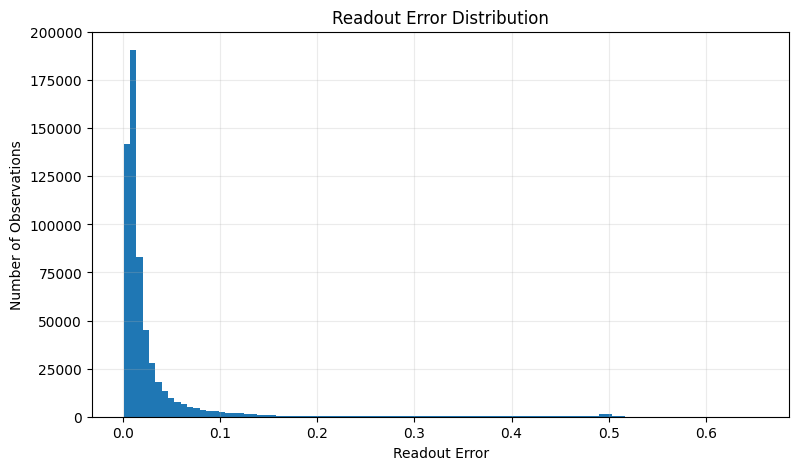

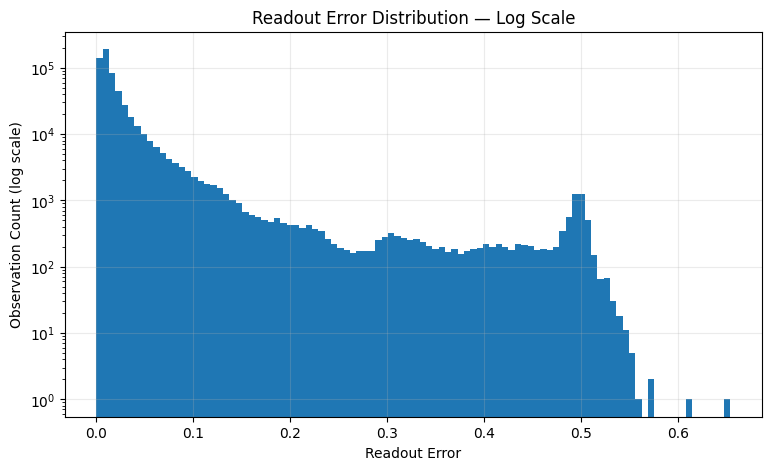

In [ ]:
import matplotlib.pyplot as plt

# Calculate upper-tail percentiles
percentiles = model_df["readout_error"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999]
)

display(percentiles.to_frame("readout_error"))

# Count observations above selected error thresholds
for threshold in [0.05, 0.10, 0.15, 0.20, 0.30]:
    count = (model_df["readout_error"] > threshold).sum()
    percentage = count / len(model_df) * 100

    print(f"> {threshold:.2f}: {count:,} observations ({percentage:.3f}%)")

# Visualise the target distribution
plt.figure(figsize=(9, 5))
plt.hist(model_df["readout_error"], bins=100)
plt.xlabel("Readout Error")
plt.ylabel("Number of Observations")
plt.title("Readout Error Distribution")
plt.grid(alpha=0.25)
plt.show()

# Log scale makes the less frequent high-error observations easier to inspect
plt.figure(figsize=(9, 5))
plt.hist(model_df["readout_error"], bins=100, log=True)
plt.xlabel("Readout Error")
plt.ylabel("Observation Count (log scale)")
plt.title("Readout Error Distribution — Log Scale")
plt.grid(alpha=0.25)
plt.show()

In [ ]:
# Print upper-tail percentiles
print("READOUT ERROR PERCENTILES")
for q in [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999]:
    print(f"{q*100:.1f}%: {model_df['readout_error'].quantile(q):.6f}")

# Print high-error observation counts
print("\nHIGH-ERROR OBSERVATIONS")
for threshold in [0.05, 0.10, 0.15, 0.20, 0.30]:
    count = (model_df["readout_error"] > threshold).sum()
    print(f">{threshold:.2f}: {count:,} ({count/len(model_df)*100:.3f}%)")

# Compare the distribution across backends
print("\nBACKEND-WISE TARGET SUMMARY")
print(
    model_df.groupby("backend")["readout_error"]
    .agg(["count", "mean", "median", "std", "max"])
    .to_string()
)

READOUT ERROR PERCENTILES
50.0%: 0.011719
75.0%: 0.023926
90.0%: 0.056396
95.0%: 0.100830
99.0%: 0.420289
99.5%: 0.492676
99.9%: 0.505493

HIGH-ERROR OBSERVATIONS
>0.05: 67,757 (11.409%)
>0.10: 29,948 (5.043%)
>0.15: 18,238 (3.071%)
>0.20: 14,125 (2.378%)
>0.30: 9,962 (1.677%)

BACKEND-WISE TARGET SUMMARY
                count      mean    median       std       max
backend                                                      
ibm_fez        206872  0.028290  0.012207  0.055415  0.553589
ibm_kingston   149467  0.023527  0.009277  0.059400  0.571167
ibm_marrakesh  206110  0.032169  0.011963  0.070291  0.653564
ibm_torino      31451  0.044797  0.029541  0.053162  0.534790


In [ ]:
# Check whether extreme readout errors are associated with failure-ceiling flags
print("FAILURE-CEILING FLAG COUNTS")
print(model_df["is_failure_ceiling"].value_counts(dropna=False))

print("\nREADOUT ERROR SUMMARY BY FAILURE-CEILING FLAG")
print(
    model_df.groupby("is_failure_ceiling", dropna=False)["readout_error"]
    .agg(["count", "mean", "median", "max"])
    .to_string()
)

# Inspect the highest-error observations
print("\nTOP 15 READOUT ERRORS")
columns_to_show = [
    "backend",
    "qubit_a",
    "readout_error",
    "observed_time",
    "calibrated_time",
    "calibration_age_seconds",
    "is_failure_ceiling"
]

display(
    model_df.nlargest(15, "readout_error")[columns_to_show]
)

# Compare high-error rates across backends
backend_tail = model_df.groupby("backend").agg(
    observations=("readout_error", "size"),
    high_error_count=("readout_error", lambda x: (x > 0.30).sum()),
    mean_error=("readout_error", "mean"),
    median_error=("readout_error", "median")
)

backend_tail["high_error_percentage"] = (
    backend_tail["high_error_count"] /
    backend_tail["observations"] * 100
)

print("\nBACKEND-WISE HIGH-ERROR RATES (> 0.30)")
display(backend_tail)

FAILURE-CEILING FLAG COUNTS
is_failure_ceiling
False    593900
Name: count, dtype: int64

READOUT ERROR SUMMARY BY FAILURE-CEILING FLAG
                     count      mean    median       max
is_failure_ceiling                                      
False               593900  0.029312  0.011719  0.653564

TOP 15 READOUT ERRORS


,backend,qubit_a,readout_error,observed_time,calibrated_time,calibration_age_seconds,is_failure_ceiling
434175,ibm_marrakesh,58,0.653564,2026-10-09 00:44:24+00:00,2026-10-09 00:01:54+00:00,2550.000000,False
434174,ibm_marrakesh,58,0.612793,2026-10-08 23:13:56+00:00,2026-10-08 22:41:46+00:00,1930.000000,False
285605,ibm_kingston,82,0.571167,2026-04-18 04:22:21.390426+00:00,2026-04-18 03:02:13+00:00,4808.390426,False
285611,ibm_kingston,82,0.568726,2026-04-19 00:47:57.977720+00:00,2026-04-18 23:44:10+00:00,3827.977720,False
285635,ibm_kingston,82,0.559204,2026-04-23 01:40:57.672099+00:00,2026-04-23 00:30:32+00:00,4225.672099,False
458127,ibm_marrakesh,76,0.554077,2026-10-22 16:00:00+00:00,2026-10-22 14:44:01+00:00,4559.000000,False
152603,ibm_fez,114,0.553589,2026-10-15 10:41:26+00:00,2026-10-15 10:18:49+00:00,1357.000000,False
152597,ibm_fez,114,0.549805,2026-10-15 07:19:12+00:00,2026-10-15 06:50:06+00:00,1746.000000,False
152598,ibm_fez,114,0.549561,2026-10-15 08:20:17+00:00,2026-10-15 07:07:20+00:00,4377.000000,False
152604,ibm_fez,114,0.549316,2026-10-15 12:00:00+00:00,2026-10-15 11:39:38+00:00,1222.000000,False



BACKEND-WISE HIGH-ERROR RATES (> 0.30)


,observations,high_error_count,mean_error,median_error,high_error_percentage
backend,,,,,
ibm_fez,206872,2700,0.028290,0.012207,1.305155
ibm_kingston,149467,2073,0.023527,0.009277,1.386928
ibm_marrakesh,206110,4936,0.032169,0.011963,2.394838
ibm_torino,31451,253,0.044797,0.029541,0.804426


In [ ]:
# Count high-error observations for each backend-qubit series
qubit_high_errors = (
    model_df.assign(high_error=model_df["readout_error"] > 0.30)
    .groupby(["backend", "qubit_a"])
    .agg(
        total_observations=("readout_error", "size"),
        high_error_count=("high_error", "sum"),
        mean_error=("readout_error", "mean"),
        maximum_error=("readout_error", "max")
    )
    .reset_index()
)

# Calculate the percentage of high-error observations per qubit
qubit_high_errors["high_error_percentage"] = (
    qubit_high_errors["high_error_count"] /
    qubit_high_errors["total_observations"] * 100
)

# Display the 15 qubits with the most high-error observations
display(
    qubit_high_errors
    .sort_values("high_error_count", ascending=False)
    .head(15)
)

# Display the 15 qubits with the highest high-error percentage,
# considering only qubits with at least 30 observations
display(
    qubit_high_errors[
        qubit_high_errors["total_observations"] >= 30
    ]
    .sort_values("high_error_percentage", ascending=False)
    .head(15)
)

,backend,qubit_a,total_observations,high_error_count,mean_error,maximum_error,high_error_percentage
442,ibm_marrakesh,130,1330,1330,0.490837,0.540649,100.000000
72,ibm_fez,72,1344,1254,0.400790,0.526611,93.303571
394,ibm_marrakesh,82,1332,1175,0.403980,0.541504,88.213213
425,ibm_marrakesh,113,1329,1065,0.345835,0.500244,80.135440
302,ibm_kingston,146,967,967,0.498329,0.521729,100.000000
406,ibm_marrakesh,94,1320,397,0.131534,0.502930,30.075758
252,ibm_kingston,96,955,306,0.169638,0.499756,32.041885
17,ibm_fez,17,1329,275,0.122593,0.529785,20.692250
521,ibm_torino,53,235,235,0.457037,0.534790,100.000000
238,ibm_kingston,82,965,187,0.092341,0.571167,19.378238


,backend,qubit_a,total_observations,high_error_count,mean_error,maximum_error,high_error_percentage
442,ibm_marrakesh,130,1330,1330,0.490837,0.540649,100.000000
521,ibm_torino,53,235,235,0.457037,0.534790,100.000000
302,ibm_kingston,146,967,967,0.498329,0.521729,100.000000
72,ibm_fez,72,1344,1254,0.400790,0.526611,93.303571
394,ibm_marrakesh,82,1332,1175,0.403980,0.541504,88.213213
425,ibm_marrakesh,113,1329,1065,0.345835,0.500244,80.135440
252,ibm_kingston,96,955,306,0.169638,0.499756,32.041885
406,ibm_marrakesh,94,1320,397,0.131534,0.502930,30.075758
17,ibm_fez,17,1329,275,0.122593,0.529785,20.692250
238,ibm_kingston,82,965,187,0.092341,0.571167,19.378238


In [ ]:
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prepare features
X_train = train_df[ALL_FEATURES].copy()
y_train = train_df[TARGET].copy()
X_val = val_df[ALL_FEATURES].copy()
y_val = val_df[TARGET].copy()

# Convert categorical features to category dtype for LightGBM's native handling
for col in CATEGORICAL_FEATURES:
    X_train[col] = X_train[col].astype("category")
    X_val[col] = X_val[col].astype("category")

print("Training optimized LightGBM Regressor (takes seconds)...")
lgb_model = lgb.LGBMRegressor(
    n_estimators=150,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    n_jobs=-1
)

lgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(stopping_rounds=15, verbose=False)]
)
print("Training completed successfully!")

# Evaluate training and validation performance
def calculate_metrics(model, X, y, dataset_name):
    predictions = model.predict(X)
    return {
        "dataset": dataset_name,
        "observations": len(y),
        "MAE": mean_absolute_error(y, predictions),
        "RMSE": np.sqrt(mean_squared_error(y, predictions)),
        "R2": r2_score(y, predictions)
    }

lgb_results = pd.DataFrame([
    calculate_metrics(lgb_model, X_train, y_train, "Train"),
    calculate_metrics(lgb_model, X_val, y_val, "Validation")
])

print("\n" + "=" * 65)
print("LIGHTGBM — TRAINING AND VALIDATION PERFORMANCE")
print("=" * 65)
print(lgb_results.to_string(index=False))

Training optimized LightGBM Regressor (takes seconds)...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.084234 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3986
[LightGBM] [Info] Number of data points in the train set: 411204, number of used features: 17
[LightGBM] [Info] Start training from score 0.028759
Training completed successfully!

LIGHTGBM — TRAINING AND VALIDATION PERFORMANCE
   dataset  observations      MAE    RMSE       R2
     Train        411204 0.008093 0.02288 0.852611
Validation         88208 0.009633 0.02785 0.787712


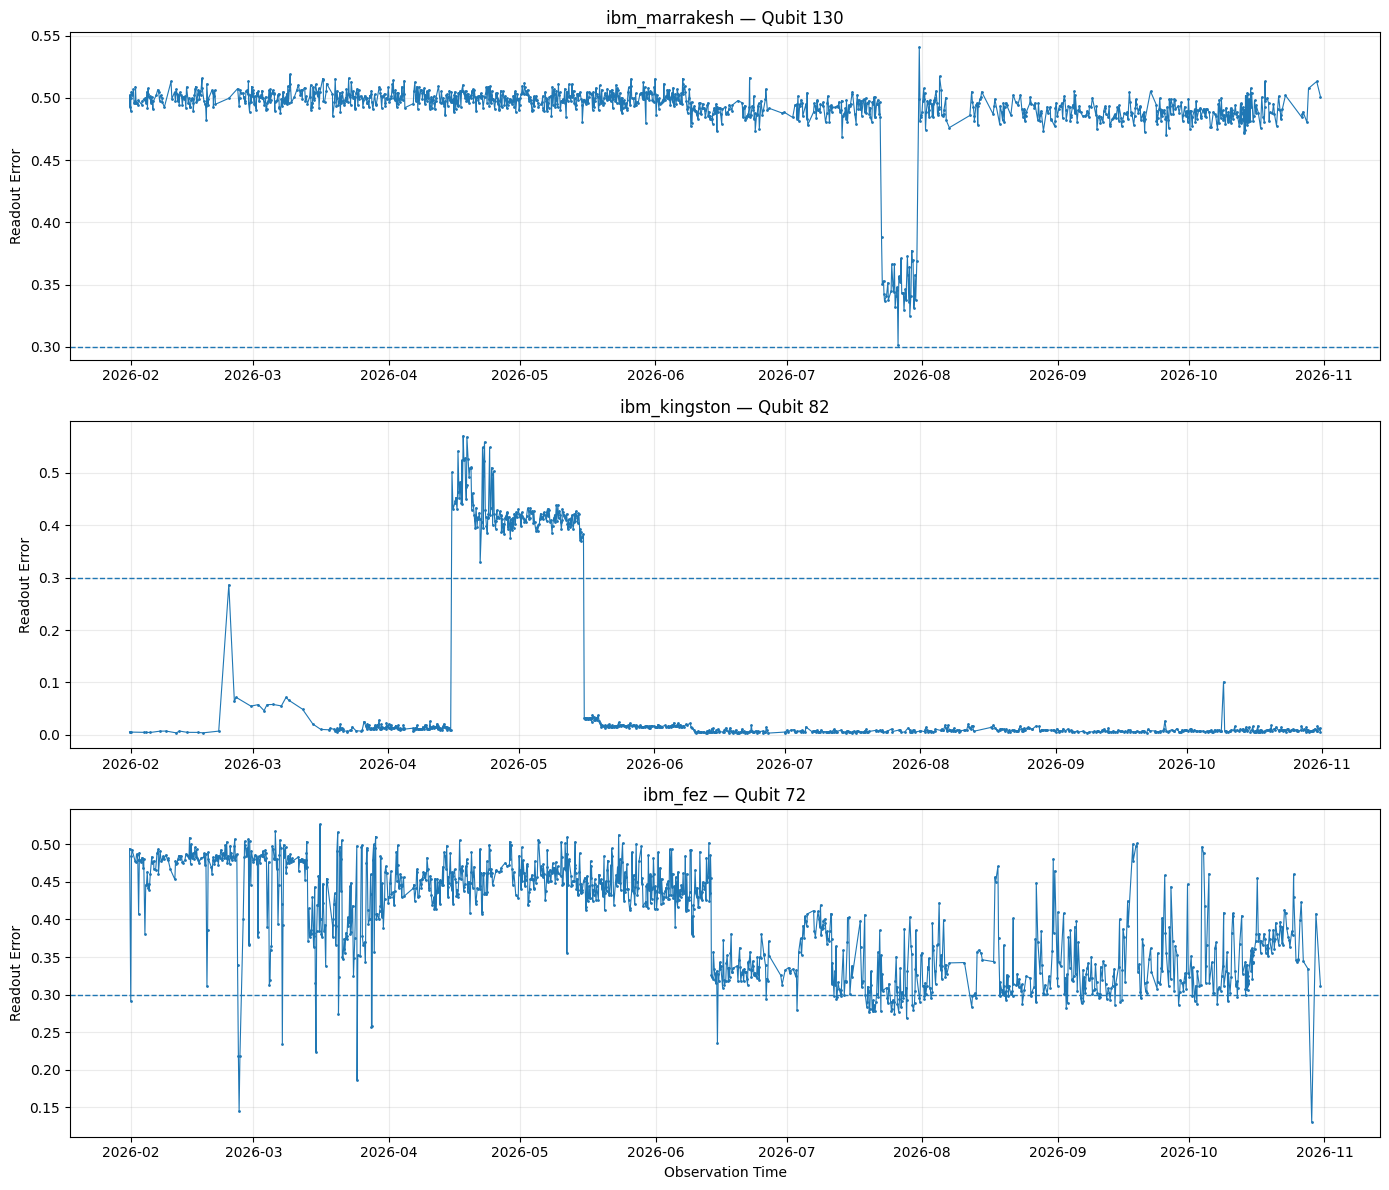

In [ ]:
import matplotlib.pyplot as plt

# Select representative qubits for temporal investigation
selected_qubits = [
    ("ibm_marrakesh", 130),
    ("ibm_kingston", 82),
    ("ibm_fez", 72)
]

fig, axes = plt.subplots(3, 1, figsize=(14, 12))

for ax, (backend, qubit) in zip(axes, selected_qubits):

    # Extract one backend-qubit time series
    series = model_df[
        (model_df["backend"] == backend) &
        (model_df["qubit_a"] == qubit)
    ].sort_values("observed_time")

    # Plot individual observations in chronological order
    ax.plot(
        series["observed_time"],
        series["readout_error"],
        linewidth=0.8,
        marker=".",
        markersize=2
    )

    # Mark the high-error threshold
    ax.axhline(0.30, linestyle="--", linewidth=1)

    ax.set_title(f"{backend} — Qubit {qubit}")
    ax.set_ylabel("Readout Error")
    ax.grid(alpha=0.25)

axes[-1].set_xlabel("Observation Time")
plt.tight_layout()
plt.show()

In [ ]:
# Summarise chronological behaviour for the selected qubits
for backend, qubit in selected_qubits:

    series = model_df[
        (model_df["backend"] == backend) &
        (model_df["qubit_a"] == qubit)
    ].sort_values("observed_time")

    first = series.iloc[0]
    last = series.iloc[-1]

    print(f"\n{backend} | Qubit {qubit}")
    print("Observations:", len(series))
    print("First observation:", first["observed_time"])
    print("Last observation:", last["observed_time"])
    print("First readout error:", round(first["readout_error"], 6))
    print("Last readout error:", round(last["readout_error"], 6))
    print("Minimum:", round(series["readout_error"].min(), 6))
    print("Median:", round(series["readout_error"].median(), 6))
    print("Maximum:", round(series["readout_error"].max(), 6))
    print("Above 0.30:", (series["readout_error"] > 0.30).sum())


ibm_marrakesh | Qubit 130
Observations: 1330
First observation: 2026-01-31 17:05:03.496046+00:00
Last observation: 2026-10-31 02:36:07+00:00
First readout error: 0.492798
Last readout error: 0.500977
Minimum: 0.301636
Median: 0.495728
Maximum: 0.540649
Above 0.30: 1330

ibm_kingston | Qubit 82
Observations: 965
First observation: 2026-01-31 17:00:00+00:00
Last observation: 2026-10-31 16:36:11+00:00
First readout error: 0.005371
Last readout error: 0.006104
Minimum: 0.002686
Median: 0.01123
Maximum: 0.571167
Above 0.30: 187

ibm_fez | Qubit 72
Observations: 1344
First observation: 2026-01-31 17:05:03.496046+00:00
Last observation: 2026-10-31 02:00:00+00:00
First readout error: 0.494141
Last readout error: 0.312012
Minimum: 0.130859
Median: 0.419189
Maximum: 0.526611
Above 0.30: 1254


In [ ]:
# Select the three qubits we are investigating
selected_qubits = [
    ("ibm_marrakesh", 130),
    ("ibm_kingston", 82),
    ("ibm_fez", 72)
]

for backend, qubit in selected_qubits:

    series = model_df[
        (model_df["backend"] == backend) &
        (model_df["qubit_a"] == qubit)
    ].copy()

    # Assign observations to calendar quarters
    series["quarter"] = series["observed_time"].dt.to_period("Q")

    # Summarise error behaviour within each quarter
    quarterly = series.groupby("quarter").agg(
        observations=("readout_error", "count"),
        mean_error=("readout_error", "mean"),
        median_error=("readout_error", "median"),
        high_error_count=("readout_error", lambda x: (x > 0.30).sum())
    )

    quarterly["high_error_percentage"] = (
        quarterly["high_error_count"] /
        quarterly["observations"] * 100
    )

    print(f"\n{backend} | Qubit {qubit}")
    print(quarterly.round(4))

/tmp/ipykernel_1011/2042352122.py:16: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  series["quarter"] = series["observed_time"].dt.to_period("Q")
/tmp/ipykernel_1011/2042352122.py:16: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  series["quarter"] = series["observed_time"].dt.to_period("Q")
/tmp/ipykernel_1011/2042352122.py:16: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  series["quarter"] = series["observed_time"].dt.to_period("Q")



ibm_marrakesh | Qubit 130
         observations  mean_error  median_error  high_error_count  \
quarter                                                             
2026Q1            282      0.5003        0.5002               282   
2026Q2            516      0.4980        0.4983               516   
2026Q3            368      0.4744        0.4888               368   
2026Q4            164      0.4887        0.4885               164   

         high_error_percentage  
quarter                         
2026Q1                   100.0  
2026Q2                   100.0  
2026Q3                   100.0  
2026Q4                   100.0  

ibm_kingston | Qubit 82
         observations  mean_error  median_error  high_error_count  \
quarter                                                             
2026Q1             83      0.0213        0.0120                 0   
2026Q2            480      0.1749        0.0184               187   
2026Q3            275      0.0081        0.0074            

In [ ]:
# Isolate Kingston qubit 82
series = model_df[
    (model_df["backend"] == "ibm_kingston") &
    (model_df["qubit_a"] == 82)
].copy()

series = series.sort_values("observed_time").reset_index(drop=True)

# Identify high-error observations using our exploratory threshold
series["high_error"] = series["readout_error"] > 0.30

# Identify transitions between low and high error
series["event_group"] = (
    series["high_error"] != series["high_error"].shift()
).cumsum()

# Summarise consecutive high-error episodes
episodes = (
    series[series["high_error"]]
    .groupby("event_group")
    .agg(
        start_time=("observed_time", "min"),
        end_time=("observed_time", "max"),
        observations=("readout_error", "count"),
        mean_error=("readout_error", "mean"),
        maximum_error=("readout_error", "max")
    )
)

print("Number of separate high-error episodes:", len(episodes))
print("\nLargest high-error episodes:")
print(
    episodes.sort_values("observations", ascending=False)
    .head(15)
    .round(4)
    .to_string()
)

Number of separate high-error episodes: 1

Largest high-error episodes:
                                  start_time                         end_time  observations  mean_error  maximum_error
event_group                                                                                                           
2           2026-04-15 14:40:31.288651+00:00 2026-05-15 18:04:56.872710+00:00           187      0.4267         0.5712


In [ ]:
# Extract the complete history of Kingston qubit 82
series = model_df[
    (model_df["backend"] == "ibm_kingston") &
    (model_df["qubit_a"] == 82)
].copy()

series = series.sort_values("observed_time").reset_index(drop=True)

# Locate the first and last high-error observations
high_mask = series["readout_error"] > 0.30

first_high_idx = series.index[high_mask][0]
last_high_idx = series.index[high_mask][-1]

# Display observations around the episode boundaries
print("BEFORE THE EPISODE")
print(series.iloc[max(0, first_high_idx-5):first_high_idx][
    ["observed_time", "readout_error"]
].to_string(index=False))

print("\nFIRST HIGH-ERROR OBSERVATIONS")
print(series.iloc[first_high_idx:first_high_idx+5][
    ["observed_time", "readout_error"]
].to_string(index=False))

print("\nLAST HIGH-ERROR OBSERVATIONS")
print(series.iloc[last_high_idx-4:last_high_idx+1][
    ["observed_time", "readout_error"]
].to_string(index=False))

print("\nAFTER THE EPISODE")
print(series.iloc[last_high_idx+1:last_high_idx+6][
    ["observed_time", "readout_error"]
].to_string(index=False))

BEFORE THE EPISODE
                   observed_time  readout_error
2026-04-14 12:57:50.841056+00:00       0.009644
2026-04-14 17:31:36.017315+00:00       0.013062
2026-04-14 19:35:27.748789+00:00       0.013184
2026-04-15 04:32:53.388797+00:00       0.009888
2026-04-15 07:39:48.344693+00:00       0.009399

FIRST HIGH-ERROR OBSERVATIONS
                   observed_time  readout_error
2026-04-15 14:40:31.288651+00:00       0.501221
2026-04-15 20:23:57.391415+00:00       0.430908
2026-04-16 05:49:02.494363+00:00       0.441772
2026-04-16 08:42:47.882506+00:00       0.446167
2026-04-16 12:32:46.617904+00:00       0.453125

LAST HIGH-ERROR OBSERVATIONS
                   observed_time  readout_error
2026-05-15 00:54:07.337217+00:00       0.392578
2026-05-15 04:49:28.549641+00:00       0.386475
2026-05-15 06:17:51.341299+00:00       0.370117
2026-05-15 12:12:00.344666+00:00       0.378296
2026-05-15 18:04:56.872710+00:00       0.382935

AFTER THE EPISODE
                   observed_time  rea

In [ ]:
# Focus on the Kingston backend and the episode period
kingston = model_df[
    (model_df["backend"] == "ibm_kingston") &
    (model_df["observed_time"] >= "2026-04-10") &
    (model_df["observed_time"] <= "2026-05-20")
].copy()

# Convert each observation into a calendar date
kingston["date"] = kingston["observed_time"].dt.date

# Calculate daily statistics across all available qubits
daily_backend = kingston.groupby("date").agg(
    total_observations=("readout_error", "count"),
    high_error_count=("readout_error", lambda x: (x > 0.30).sum()),
    median_error=("readout_error", "median")
)

# Calculate the percentage of observations above the threshold
daily_backend["high_error_percentage"] = (
    daily_backend["high_error_count"] /
    daily_backend["total_observations"] * 100
)

print(daily_backend.round(3).to_string())

            total_observations  high_error_count  median_error  high_error_percentage
date                                                                                 
2026-04-10                1069                14         0.009                  1.310
2026-04-11                1074                14         0.009                  1.304
2026-04-12                 915                12         0.009                  1.311
2026-04-13                1074                15         0.010                  1.397
2026-04-14                 923                13         0.009                  1.408
2026-04-15                 763                15         0.010                  1.966
2026-04-16                 914                18         0.010                  1.969
2026-04-17                 912                18         0.010                  1.974
2026-04-18                 926                19         0.010                  2.052
2026-04-19                 916                19      

In [ ]:
# Examine Kingston during qubit 82's high-error episode
episode_start = "2026-04-15"
episode_end = "2026-05-16"

episode_data = model_df[
    (model_df["backend"] == "ibm_kingston") &
    (model_df["observed_time"] >= episode_start) &
    (model_df["observed_time"] < episode_end)
].copy()

# Summarise high-error behaviour for every qubit
qubit_impact = episode_data.groupby("qubit_a").agg(
    observations=("readout_error", "count"),
    high_error_count=("readout_error", lambda x: (x > 0.30).sum()),
    median_error=("readout_error", "median"),
    maximum_error=("readout_error", "max")
)

qubit_impact["high_error_percentage"] = (
    qubit_impact["high_error_count"] /
    qubit_impact["observations"] * 100
)

# Count qubits with at least one high-error observation
affected = qubit_impact[qubit_impact["high_error_count"] > 0]

print("Total qubits examined:", len(qubit_impact))
print("Qubits with at least one high-error observation:", len(affected))
print("Qubits with more than 50% high-error observations:",
      (qubit_impact["high_error_percentage"] > 50).sum())

print("\nTop 15 qubits by high-error percentage:")
print(
    qubit_impact.sort_values(
        "high_error_percentage", ascending=False
    ).head(15).round(4).to_string()
)

Total qubits examined: 156
Qubits with at least one high-error observation: 9
Qubits with more than 50% high-error observations: 3

Top 15 qubits by high-error percentage:
         observations  high_error_count  median_error  maximum_error  high_error_percentage
qubit_a                                                                                    
146               190               190        0.4995         0.5217               100.0000
96                188               187        0.4933         0.4979                99.4681
82                190               187        0.4163         0.5712                98.4211
121               190                 4        0.1964         0.3536                 2.1053
113               191                 4        0.1495         0.3380                 2.0942
132               184                 3        0.0059         0.4681                 1.6304
31                191                 2        0.0533         0.3241                 1.0471


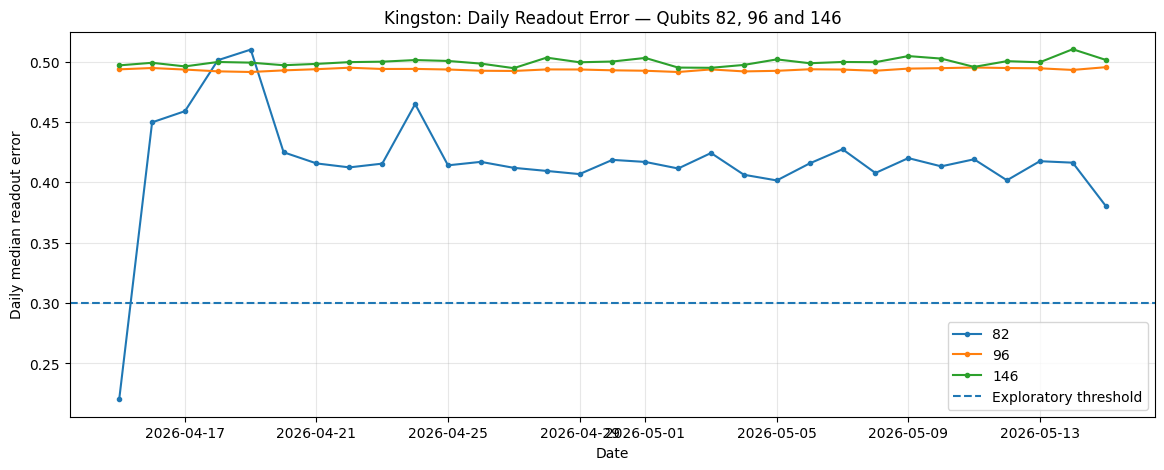

In [ ]:
# Examine the three qubits with persistent high errors
selected_qubits = [82, 96, 146]

comparison = model_df[
    (model_df["backend"] == "ibm_kingston") &
    (model_df["qubit_a"].isin(selected_qubits)) &
    (model_df["observed_time"] >= "2026-04-15") &
    (model_df["observed_time"] < "2026-05-16")
].copy()

# Summarize each qubit's behaviour over time
comparison["date"] = comparison["observed_time"].dt.date

daily_comparison = comparison.groupby(
    ["date", "qubit_a"]
)["readout_error"].median().unstack()

# Plot the daily median error for each qubit
import matplotlib.pyplot as plt

daily_comparison.plot(figsize=(14, 5), marker=".")
plt.axhline(0.30, linestyle="--", label="Exploratory threshold")
plt.title("Kingston: Daily Readout Error — Qubits 82, 96 and 146")
plt.xlabel("Date")
plt.ylabel("Daily median readout error")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# Extract Qubit 82 during the identified episode
q82 = comparison[comparison["qubit_a"] == 82].copy()

# Calculate daily statistics rather than relying only on the graph
q82_daily = q82.groupby("date")["readout_error"].agg(
    observations="count",
    median="median",
    minimum="min",
    maximum="max"
)

print(q82_daily.tail(10).round(4).to_string())

            observations  median  minimum  maximum
date                                              
2026-05-06             6  0.4156   0.4121   0.4246
2026-05-07             6  0.4274   0.4081   0.4319
2026-05-08             6  0.4077   0.3859   0.4138
2026-05-09             5  0.4200   0.4060   0.4390
2026-05-10             7  0.4132   0.3936   0.4309
2026-05-11             6  0.4191   0.4106   0.4252
2026-05-12             8  0.4017   0.3934   0.4146
2026-05-13             7  0.4175   0.3934   0.4268
2026-05-14             6  0.4163   0.3727   0.4227
2026-05-15             6  0.3806   0.0319   0.3926


In [ ]:

import pandas as pd
import numpy as np

# ============================================================
# STAGE 1: SERIES-WISE TEMPORAL FEATURE ENGINEERING
# ============================================================

# Preserve the original audited dataset
feature_df = model_df.copy()

# Each backend-qubit combination is an independent time series
GROUPS = ["backend", "qubit_a"]

# Sort chronologically within each independent series
feature_df = feature_df.sort_values(
    GROUPS + ["observed_time"]
).reset_index(drop=True)

# ------------------------------------------------------------
# 1. HISTORICAL FEATURES
# ------------------------------------------------------------

grouped_error = feature_df.groupby(GROUPS)["readout_error"]

# Previous observations within the same qubit series
for lag in [1, 2, 3, 5]:
    feature_df[f"lag_{lag}"] = grouped_error.shift(lag)

# Current observation available at prediction time
feature_df["current_error"] = feature_df["readout_error"]

# ------------------------------------------------------------
# 2. ROLLING STATISTICS
# ------------------------------------------------------------

# Recent average and variability
# Windows include current observation and preceding observations
for window in [3, 5, 10]:
    feature_df[f"rolling_mean_{window}"] = grouped_error.transform(
        lambda s: s.rolling(window=window, min_periods=window).mean()
    )

    feature_df[f"rolling_std_{window}"] = grouped_error.transform(
        lambda s: s.rolling(window=window, min_periods=window).std()
    )

# ------------------------------------------------------------
# 3. TEMPORAL FEATURES
# ------------------------------------------------------------

feature_df["time_gap_hours"] = (
    feature_df.groupby(GROUPS)["observed_time"]
    .diff()
    .dt.total_seconds() / 3600
)

# ------------------------------------------------------------
# 4. ERROR CHANGE FEATURES
# ------------------------------------------------------------

# Absolute change between current and previous measurement
feature_df["error_change"] = (
    feature_df["current_error"] - feature_df["lag_1"]
)

# Rate of change, excluding zero time gaps
feature_df["error_change_rate"] = (
    feature_df["error_change"]
    / feature_df["time_gap_hours"].replace(0, np.nan)
)

# ------------------------------------------------------------
# 5. CALIBRATION INFORMATION
# ------------------------------------------------------------

# Calibration age is retained as a candidate predictor
# No transformation is applied at this stage

# ------------------------------------------------------------
# 6. NEXT-OBSERVATION TARGET
# ------------------------------------------------------------

# Predict the next observation in the same backend-qubit series
feature_df["target_next_error"] = grouped_error.shift(-1)

# Also record the elapsed time until the target observation.
# This is metadata for evaluation, NOT a prediction input.
feature_df["target_gap_hours"] = (
    feature_df.groupby(GROUPS)["observed_time"]
    .shift(-1) - feature_df["observed_time"]
).dt.total_seconds() / 3600

# ------------------------------------------------------------
# 7. SELECT INPUT FEATURES
# ------------------------------------------------------------

features = [
    "current_error",
    "lag_1", "lag_2", "lag_3", "lag_5",
    "rolling_mean_3", "rolling_std_3",
    "rolling_mean_5", "rolling_std_5",
    "rolling_mean_10", "rolling_std_10",
    "time_gap_hours",
    "error_change",
    "error_change_rate",
    "calibration_age_seconds"
]

target = "target_next_error"

# ------------------------------------------------------------
# 8. REMOVE INCOMPLETE ROWS
# ------------------------------------------------------------

# Require all selected input features and the next-observation target
feature_df = feature_df.replace([np.inf, -np.inf], np.nan)

feature_df = feature_df.dropna(
    subset=features + [target, "target_gap_hours"]
).copy()

# ------------------------------------------------------------
# 9. SERIES-WISE VALIDATION
# ------------------------------------------------------------

series_summary = feature_df.groupby(GROUPS).agg(
    usable_rows=("target_next_error", "count"),
    first_time=("observed_time", "min"),
    last_time=("observed_time", "max"),
    mean_error=("readout_error", "mean"),
    maximum_error=("readout_error", "max")
)

# ------------------------------------------------------------
# 10. FINAL REPORT
# ------------------------------------------------------------

print("=" * 65)
print("SERIES-WISE FEATURE ENGINEERING REPORT")
print("=" * 65)

print("Original observations:", len(model_df))
print("Usable feature observations:", len(feature_df))
print("Excluded rows:", len(model_df) - len(feature_df))
print("Independent backend-qubit series:", len(series_summary))

print("\nFeature columns:")
print(features)

print("\nMissing values:")
print(feature_df[features + [target]].isna().sum())

print("\nFeature dataset sample:")
print(
    feature_df[
        GROUPS + ["observed_time"] + features + [target]
    ].head(10).to_string(index=False)
)

print("\nSeries summary:")
print(series_summary.describe().round(4))

print("\nSeries-wise feature engineering completed.")


SERIES-WISE FEATURE ENGINEERING REPORT
Original observations: 593900
Usable feature observations: 587890
Excluded rows: 6010
Independent backend-qubit series: 601

Feature columns:
['current_error', 'lag_1', 'lag_2', 'lag_3', 'lag_5', 'rolling_mean_3', 'rolling_std_3', 'rolling_mean_5', 'rolling_std_5', 'rolling_mean_10', 'rolling_std_10', 'time_gap_hours', 'error_change', 'error_change_rate', 'calibration_age_seconds']

Missing values:
current_error              0
lag_1                      0
lag_2                      0
lag_3                      0
lag_5                      0
rolling_mean_3             0
rolling_std_3              0
rolling_mean_5             0
rolling_std_5              0
rolling_mean_10            0
rolling_std_10             0
time_gap_hours             0
error_change               0
error_change_rate          0
calibration_age_seconds    0
target_next_error          0
dtype: int64

Feature dataset sample:
backend  qubit_a                    observed_time  curren

In [ ]:

# ============================================================
# SERIES 2: CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT
# ============================================================

import numpy as np
import pandas as pd

GROUPS = ["backend", "qubit_a"]

# Work on a separate copy; retain feature_df unchanged.
split_df = feature_df.copy()

# Ensure every backend-qubit series is ordered by time.
split_df = split_df.sort_values(
    GROUPS + ["observed_time"]
).reset_index(drop=True)

# Calculate each observation's position and total size within its series.
grouped = split_df.groupby(GROUPS, sort=False)

split_df["series_position"] = grouped.cumcount()
split_df["series_size"] = grouped["series_position"].transform("size")

# Determine chronological boundaries independently for each series.
split_df["train_boundary"] = np.floor(
    split_df["series_size"] * 0.70
).astype(int)

split_df["validation_boundary"] = np.floor(
    split_df["series_size"] * 0.85
).astype(int)

# Assign observations without shuffling or mixing time periods.
split_df["dataset_split"] = np.select(
    [
        split_df["series_position"] < split_df["train_boundary"],
        split_df["series_position"] < split_df["validation_boundary"]
    ],
    [
        "train",
        "validation"
    ],
    default="test"
)

# Remove temporary boundary columns after assignment.
split_df = split_df.drop(
    columns=["train_boundary", "validation_boundary"]
)

# ------------------------------------------------------------
# 1. Overall split report
# ------------------------------------------------------------

print("=" * 65)
print("CHRONOLOGICAL SPLIT REPORT")
print("=" * 65)

print("\nObservation counts:")
print(split_df["dataset_split"].value_counts())

print("\nObservation percentages:")
print(
    (split_df["dataset_split"].value_counts(normalize=True) * 100)
    .round(2)
)

# ------------------------------------------------------------
# 2. Verify every series has all three splits
# ------------------------------------------------------------

series_split_counts = (
    split_df.groupby(GROUPS + ["dataset_split"])
    .size()
    .unstack(fill_value=0)
)

print("\nSeries coverage:")
print(series_split_counts.head(10))

print("\nNumber of series represented in each split:")
for split in ["train", "validation", "test"]:
    print(
        f"{split}: "
        f"{(series_split_counts[split] > 0).sum()} series"
    )

# ------------------------------------------------------------
# 3. Verify chronological ordering within every series
# ------------------------------------------------------------

series_dates = (
    split_df.groupby(GROUPS + ["dataset_split"])["observed_time"]
    .agg(["min", "max"])
    .reset_index()
)

print("\nChronological boundary check (first 10 series):")

for (backend, qubit), group in series_dates.groupby(GROUPS):
    train_end = group.loc[
        group["dataset_split"] == "train", "max"
    ].iloc[0]

    validation_start = group.loc[
        group["dataset_split"] == "validation", "min"
    ].iloc[0]

    validation_end = group.loc[
        group["dataset_split"] == "validation", "max"
    ].iloc[0]

    test_start = group.loc[
        group["dataset_split"] == "test", "min"
    ].iloc[0]

    assert train_end < validation_start
    assert validation_end < test_start

print("PASS: No chronological overlap between splits.")

# ------------------------------------------------------------
# 4. Separate the three datasets for model development
# ------------------------------------------------------------

train_df = split_df[split_df["dataset_split"] == "train"].copy()
val_df = split_df[split_df["dataset_split"] == "validation"].copy()
test_df = split_df[split_df["dataset_split"] == "test"].copy()

print("\nFinal dataset shapes:")
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

print("\nChronological splitting completed successfully.")


CHRONOLOGICAL SPLIT REPORT

Observation counts:
dataset_split
train         411204
test           88478
validation     88208
Name: count, dtype: int64

Observation percentages:
dataset_split
train         69.95
test          15.05
validation    15.00
Name: proportion, dtype: float64

Series coverage:
dataset_split    test  train  validation
backend qubit_a                         
ibm_fez 0         200    933         200
        1         199    926         198
        2         199    927         199
        3         200    928         199
        4         201    933         200
        5         200    930         199
        6         195    906         194
        7         199    926         199
        8         197    916         196
        9         199    927         199

Number of series represented in each split:
train: 601 series
validation: 601 series
test: 601 series

Chronological boundary check (first 10 series):
PASS: No chronological overlap between splits.

Final 

In [ ]:

# ============================================================
# SERIES 3: PERSISTENCE BASELINE
# Predict the next readout error using the current readout error.
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

TARGET = "target_next_error"
PREDICTION = "current_error"

def evaluate_model(data, split_name):
    # Actual next-observation values and persistence predictions.
    y_true = data[TARGET].to_numpy()
    y_pred = data[PREDICTION].to_numpy()

    return {
        "dataset": split_name,
        "observations": len(data),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

# Evaluate independently on all three chronological partitions.
baseline_results = pd.DataFrame([
    evaluate_model(train_df, "Train"),
    evaluate_model(val_df, "Validation"),
    evaluate_model(test_df, "Test")
])

print("=" * 65)
print("PERSISTENCE BASELINE — OVERALL PERFORMANCE")
print("=" * 65)
print(baseline_results.to_string(index=False))

# ------------------------------------------------------------
# Backend-wise performance on the held-out test set.
# This reveals whether performance differs across processors.
# ------------------------------------------------------------

backend_results = []

for backend, group in test_df.groupby("backend"):
    y_true = group[TARGET].to_numpy()
    y_pred = group[PREDICTION].to_numpy()

    backend_results.append({
        "backend": backend,
        "observations": len(group),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    })

backend_baseline = pd.DataFrame(backend_results)

print("\n" + "=" * 65)
print("PERSISTENCE BASELINE — TEST PERFORMANCE BY BACKEND")
print("=" * 65)
print(backend_baseline.to_string(index=False))

# ------------------------------------------------------------
# Save baseline predictions for later model comparisons.
# ------------------------------------------------------------

test_baseline_predictions = test_df[
    GROUPS + ["observed_time", "current_error", TARGET]
].copy()

test_baseline_predictions["baseline_prediction"] = (
    test_baseline_predictions["current_error"]
)

test_baseline_predictions["baseline_residual"] = (
    test_baseline_predictions[TARGET]
    - test_baseline_predictions["baseline_prediction"]
)

print("\nBaseline prediction sample:")
print(test_baseline_predictions.head(10).to_string(index=False))

print("\nPersistence baseline completed.")


PERSISTENCE BASELINE — OVERALL PERFORMANCE
   dataset  observations      MAE     RMSE       R2
     Train        411204 0.009151 0.030087 0.745139
Validation         88208 0.010366 0.033194 0.698426
      Test         88478 0.013211 0.043224 0.654377

PERSISTENCE BASELINE — TEST PERFORMANCE BY BACKEND
      backend  observations      MAE     RMSE       R2
      ibm_fez         30872 0.011440 0.046746 0.678791
 ibm_kingston         22255 0.006352 0.022130 0.803041
ibm_marrakesh         30756 0.020917 0.052944 0.559795
   ibm_torino          4595 0.006747 0.012611 0.936667

Baseline prediction sample:
backend  qubit_a             observed_time  current_error  target_next_error  baseline_prediction  baseline_residual
ibm_fez        0 2026-09-13 17:36:07+00:00       0.027100           0.019409             0.027100          -0.007690
ibm_fez        0 2026-09-13 22:36:21+00:00       0.019409           0.021240             0.019409           0.001831
ibm_fez        0 2026-09-14 01:56:10+00:00

In [ ]:

# ============================================================
# SERIES 4: LIGHTGBM REGRESSION
# Native categorical features + validation early stopping
# ============================================================

import lightgbm as lgb
import pandas as pd
import numpy as np
import time

# Use the same feature set and chronological partitions.
LIGHTGBM_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X_train_lgb = train_df[LIGHTGBM_FEATURES].copy()
X_val_lgb = val_df[LIGHTGBM_FEATURES].copy()

y_train_lgb = train_df[TARGET].copy()
y_val_lgb = val_df[TARGET].copy()

# Convert backend and qubit identity into pandas categorical types.
# Align category definitions across training and validation.
for col in CATEGORICAL_FEATURES:
    categories = pd.Index(
        pd.concat([X_train_lgb[col], X_val_lgb[col]]).unique()
    )

    X_train_lgb[col] = pd.Categorical(
        X_train_lgb[col], categories=categories
    )
    X_val_lgb[col] = pd.Categorical(
        X_val_lgb[col], categories=categories
    )

# Configure a controlled initial gradient boosting experiment.
lgb_model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=1500,       # Upper limit; early stopping selects rounds
    learning_rate=0.04,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=50,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=4,
    verbosity=-1
)

print("Starting LightGBM training...")
start_time = time.time()

# Validation data controls early stopping, not the final test set.
lgb_model.fit(
    X_train_lgb,
    y_train_lgb,
    eval_set=[(X_val_lgb, y_val_lgb)],
    eval_metric="l1",
    categorical_feature=CATEGORICAL_FEATURES,
    callbacks=[
        lgb.early_stopping(stopping_rounds=60),
        lgb.log_evaluation(period=50)
    ]
)

training_time = time.time() - start_time

print(f"\nTraining completed in {training_time:.2f} seconds.")
print("Best iteration:", lgb_model.best_iteration_)

# Evaluate using our established regression metrics.
train_predictions_lgb = lgb_model.predict(
    X_train_lgb, num_iteration=lgb_model.best_iteration_
)
val_predictions_lgb = lgb_model.predict(
    X_val_lgb, num_iteration=lgb_model.best_iteration_
)

def regression_report(y_true, y_pred, name):
    return {
        "dataset": name,
        "observations": len(y_true),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lgb_results = pd.DataFrame([
    regression_report(y_train_lgb, train_predictions_lgb, "Train"),
    regression_report(y_val_lgb, val_predictions_lgb, "Validation")
])

print("\nLIGHTGBM PERFORMANCE")
print(lgb_results.to_string(index=False))


Starting LightGBM training...
Training until validation scores don't improve for 60 rounds
[50]	valid_0's l1: 0.0105802	valid_0's l2: 0.000787146
[100]	valid_0's l1: 0.00923181	valid_0's l2: 0.000757061
Early stopping, best iteration is:
[76]	valid_0's l1: 0.00948299	valid_0's l2: 0.000749975

Training completed in 12.31 seconds.
Best iteration: 76

LIGHTGBM PERFORMANCE
   dataset  observations      MAE     RMSE       R2
     Train        411204 0.008056 0.022999 0.851078
Validation         88208 0.009483 0.027386 0.794729


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the same feature columns and categorical encoding as training.
X_test_lgb = test_df[LIGHTGBM_FEATURES].copy()
y_test_lgb = test_df[TARGET].copy()

for col in CATEGORICAL_FEATURES:
    X_test_lgb[col] = pd.Categorical(
        X_test_lgb[col],
        categories=X_train_lgb[col].cat.categories
    )

# Predict using the best validation iteration.
test_predictions_lgb = lgb_model.predict(
    X_test_lgb,
    num_iteration=lgb_model.best_iteration_
)

# Calculate final test metrics.
lgb_test_results = {
    "Model": "LightGBM",
    "Observations": len(y_test_lgb),
    "MAE": mean_absolute_error(y_test_lgb, test_predictions_lgb),
    "RMSE": np.sqrt(mean_squared_error(y_test_lgb, test_predictions_lgb)),
    "R2": r2_score(y_test_lgb, test_predictions_lgb)
}

# Persistence results were established in our earlier experiment.
baseline_test_results = {
    "Model": "Persistence",
    "Observations": len(y_test_lgb),
    "MAE": 0.013211,
    "RMSE": 0.043224,
    "R2": 0.654377
}

comparison_df = pd.DataFrame([
    baseline_test_results,
    lgb_test_results
])

print("FINAL TEST-SET COMPARISON")
display(comparison_df.round(6))

# Store predictions and residuals for diagnostic visualizations.
lgb_test_predictions_df = test_df[
    ["backend", "qubit_a", "observed_time", TARGET]
].copy()

lgb_test_predictions_df["prediction"] = test_predictions_lgb
lgb_test_predictions_df["residual"] = (
    lgb_test_predictions_df[TARGET]
    - lgb_test_predictions_df["prediction"]
)


FINAL TEST-SET COMPARISON


,Model,Observations,MAE,RMSE,R2
0,Persistence,88478,0.013211,0.043224,0.654377
1,LightGBM,88478,0.013682,0.039855,0.706154


BACKEND-WISE TEST PERFORMANCE


,backend,observations,LightGBM_MAE,Persistence_MAE,LightGBM_RMSE,Persistence_RMSE,LightGBM_R2
0,ibm_fez,30872,0.015366,0.011440,0.048477,0.046746,0.654555
1,ibm_kingston,22255,0.006159,0.006352,0.018493,0.022130,0.862461
2,ibm_marrakesh,30756,0.018589,0.020917,0.044115,0.052944,0.694374
3,ibm_torino,4595,0.005964,0.006747,0.010656,0.012611,0.954780



ABSOLUTE ERROR QUANTILES


,lgb_abs_error,persistence_abs_error
0.50,0.004214,0.003052
0.75,0.008814,0.008057
0.90,0.023962,0.023926
0.95,0.053617,0.051636
0.99,0.207393,0.222806


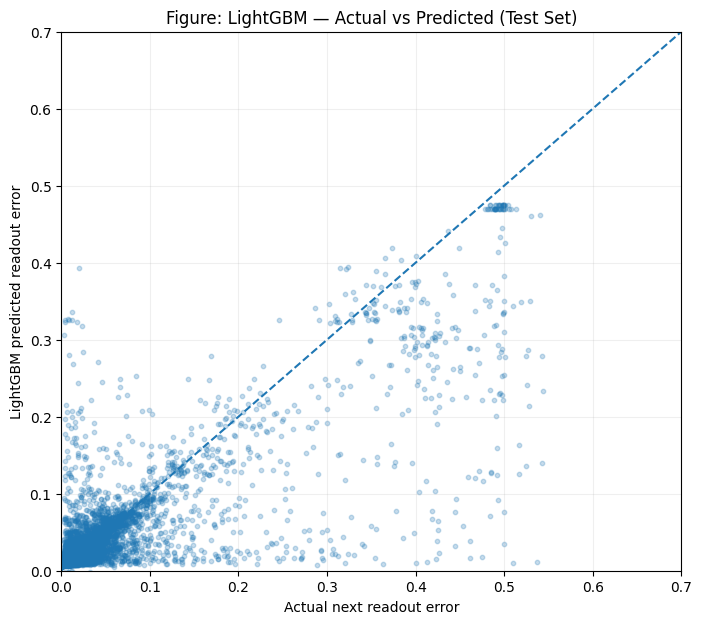

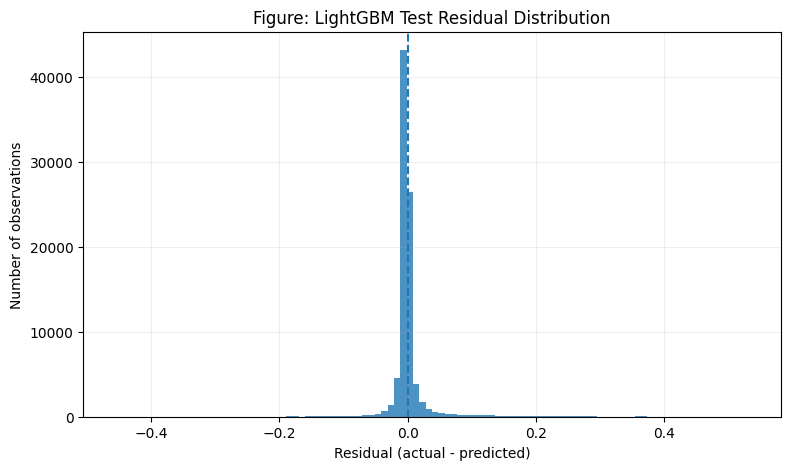

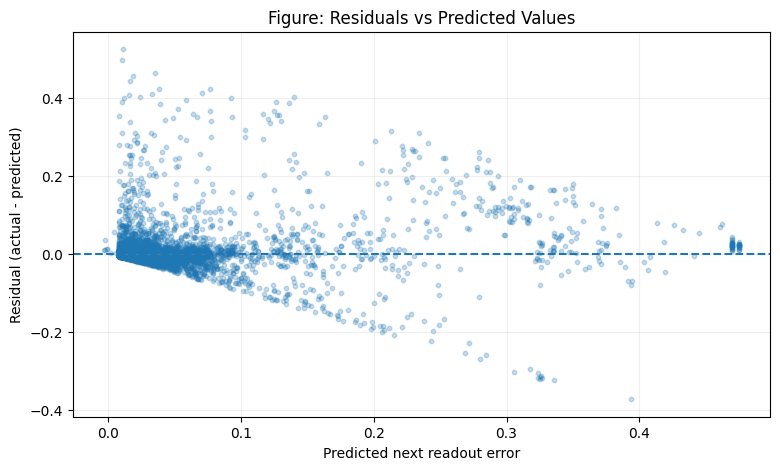

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Build a common diagnostic frame for both models.
diagnostics = lgb_test_predictions_df.copy()
diagnostics["persistence_prediction"] = test_df["current_error"].to_numpy()

diagnostics["lgb_abs_error"] = (
    diagnostics[TARGET] - diagnostics["prediction"]
).abs()

diagnostics["persistence_abs_error"] = (
    diagnostics[TARGET] - diagnostics["persistence_prediction"]
).abs()

diagnostics["lgb_squared_error"] = (
    diagnostics[TARGET] - diagnostics["prediction"]
) ** 2

diagnostics["persistence_squared_error"] = (
    diagnostics[TARGET] - diagnostics["persistence_prediction"]
) ** 2

# Compare both models separately for each backend.
backend_results = []

for backend, group in diagnostics.groupby("backend"):
    actual = group[TARGET]

    backend_results.append({
        "backend": backend,
        "observations": len(group),
        "LightGBM_MAE": mean_absolute_error(actual, group["prediction"]),
        "Persistence_MAE": mean_absolute_error(
            actual, group["persistence_prediction"]
        ),
        "LightGBM_RMSE": np.sqrt(
            mean_squared_error(actual, group["prediction"])
        ),
        "Persistence_RMSE": np.sqrt(
            mean_squared_error(actual, group["persistence_prediction"])
        ),
        "LightGBM_R2": r2_score(actual, group["prediction"])
    })

backend_comparison = pd.DataFrame(backend_results)

print("BACKEND-WISE TEST PERFORMANCE")
display(backend_comparison.round(6))

# Compare absolute-error distributions.
print("\nABSOLUTE ERROR QUANTILES")
error_quantiles = diagnostics[
    ["lgb_abs_error", "persistence_abs_error"]
].quantile([0.50, 0.75, 0.90, 0.95, 0.99])

display(error_quantiles.round(6))

# Plot 1: Actual versus predicted values.
# Sample points only for visual clarity; metrics above use all test rows.
plot_sample = diagnostics.sample(
    n=min(12000, len(diagnostics)),
    random_state=42
)

plt.figure(figsize=(8, 7))
plt.scatter(
    plot_sample[TARGET],
    plot_sample["prediction"],
    alpha=0.25,
    s=10
)
plt.plot([0, 0.7], [0, 0.7], linestyle="--")
plt.xlabel("Actual next readout error")
plt.ylabel("LightGBM predicted readout error")
plt.title("Figure: LightGBM — Actual vs Predicted (Test Set)")
plt.xlim(0, 0.7)
plt.ylim(0, 0.7)
plt.grid(alpha=0.2)
plt.show()

# Plot 2: Distribution of residuals.
plt.figure(figsize=(9, 5))
plt.hist(
    diagnostics["residual"],
    bins=100,
    alpha=0.8
)
plt.axvline(0, linestyle="--")
plt.xlabel("Residual (actual - predicted)")
plt.ylabel("Number of observations")
plt.title("Figure: LightGBM Test Residual Distribution")
plt.grid(alpha=0.2)
plt.show()

# Plot 3: Residuals against predicted values.
plt.figure(figsize=(9, 5))
plt.scatter(
    plot_sample["prediction"],
    plot_sample["residual"],
    alpha=0.25,
    s=10
)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted next readout error")
plt.ylabel("Residual (actual - predicted)")
plt.title("Figure: Residuals vs Predicted Values")
plt.grid(alpha=0.2)
plt.show()

In [ ]:

import numpy as np
import pandas as pd

# Group test observations by their actual next readout-error value.
diagnostics["error_range"] = pd.cut(
    diagnostics[TARGET],
    bins=[-np.inf, 0.05, 0.10, 0.30, np.inf],
    labels=["Below 0.05", "0.05–0.10", "0.10–0.30", "Above 0.30"],
    right=False
)

range_results = []

for error_range, group in diagnostics.groupby(
    "error_range", observed=False
):
    actual = group[TARGET]

    lgb_mae = group["lgb_abs_error"].mean()
    persistence_mae = group["persistence_abs_error"].mean()

    lgb_rmse = np.sqrt(group["lgb_squared_error"].mean())
    persistence_rmse = np.sqrt(
        group["persistence_squared_error"].mean()
    )

    range_results.append({
        "actual_error_range": str(error_range),
        "observations": len(group),
        "LightGBM_MAE": lgb_mae,
        "Persistence_MAE": persistence_mae,
        "MAE_improvement_pct": (
            (persistence_mae - lgb_mae) / persistence_mae * 100
        ) if persistence_mae else np.nan,
        "LightGBM_RMSE": lgb_rmse,
        "Persistence_RMSE": persistence_rmse,
        "RMSE_improvement_pct": (
            (persistence_rmse - lgb_rmse) / persistence_rmse * 100
        ) if persistence_rmse else np.nan
    })

range_comparison = pd.DataFrame(range_results)

print("MODEL PERFORMANCE BY ACTUAL NEXT READOUT-ERROR RANGE")
display(range_comparison.round(6))

# Calculate each range's contribution to the total squared-error difference.
diagnostics["squared_error_difference"] = (
    diagnostics["persistence_squared_error"]
    - diagnostics["lgb_squared_error"]
)

contribution = (
    diagnostics.groupby("error_range", observed=False)
    ["squared_error_difference"]
    .sum()
    .reset_index()
)

total_gain = diagnostics["squared_error_difference"].sum()

contribution["share_of_net_squared_error_gain_pct"] = (
    contribution["squared_error_difference"] / total_gain * 100
    if total_gain != 0 else np.nan
)

print("\nCONTRIBUTION TO NET SQUARED-ERROR IMPROVEMENT")
display(contribution.round(4))


MODEL PERFORMANCE BY ACTUAL NEXT READOUT-ERROR RANGE


,actual_error_range,observations,LightGBM_MAE,Persistence_MAE,MAE_improvement_pct,LightGBM_RMSE,Persistence_RMSE,RMSE_improvement_pct
0,Below 0.05,77230,0.006940,0.008146,14.807474,0.017276,0.029636,41.707858
1,0.05–0.10,5755,0.021593,0.026717,19.179927,0.032760,0.048435,32.362201
2,0.10–0.30,3199,0.069038,0.065320,-5.691865,0.092323,0.094842,2.656453
3,Above 0.30,2294,0.143627,0.077172,-86.113332,0.191409,0.155113,-23.399813



CONTRIBUTION TO NET SQUARED-ERROR IMPROVEMENT


,error_range,squared_error_difference,share_of_net_squared_error_gain_pct
0,Below 0.05,44.7830,180.8437
1,0.05–0.10,7.3244,29.5776
2,0.10–0.30,1.5085,6.0916
3,Above 0.30,-28.8526,-116.5129


In [ ]:

import time
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the same features as the LightGBM experiment.
NUMERIC_FEATURES = [
    col for col in LIGHTGBM_FEATURES
    if col not in CATEGORICAL_FEATURES
]

# Scale numerical features and encode backend/qubit identifiers.
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), NUMERIC_FEATURES),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES)
    ]
)

# Build a reproducible regression pipeline.
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Prepare training and validation data.
X_train_lr = train_df[LIGHTGBM_FEATURES].copy()
X_val_lr = val_df[LIGHTGBM_FEATURES].copy()

y_train_lr = train_df[TARGET]
y_val_lr = val_df[TARGET]

# Train and measure runtime.
start_time = time.time()

linear_model.fit(X_train_lr, y_train_lr)

training_time = time.time() - start_time

# Generate predictions.
train_predictions_lr = linear_model.predict(X_train_lr)
val_predictions_lr = linear_model.predict(X_val_lr)

# Calculate regression metrics.
def regression_metrics(actual, predicted):
    return {
        "Observations": len(actual),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

lr_results = pd.DataFrame([
    {"Dataset": "Train", **regression_metrics(y_train_lr, train_predictions_lr)},
    {"Dataset": "Validation", **regression_metrics(y_val_lr, val_predictions_lr)}
])

print(f"Linear Regression training completed in {training_time:.2f} seconds.")
print("\nLINEAR REGRESSION PERFORMANCE")
display(lr_results.round(6))


Linear Regression training completed in 4.92 seconds.

LINEAR REGRESSION PERFORMANCE


,Dataset,Observations,MAE,RMSE,R2
0,Train,411204,0.007986,0.02446,0.831563
1,Validation,88208,0.008715,0.02614,0.812975


In [ ]:
import os
import psutil
import multiprocessing

print("CPU cores:", multiprocessing.cpu_count())
print("CPU usage:", psutil.cpu_percent(interval=1), "%")

memory = psutil.virtual_memory()
print("Total RAM:", round(memory.total / (1024**3), 2), "GB")
print("Available RAM:", round(memory.available / (1024**3), 2), "GB")
print("RAM usage:", memory.percent, "%")

print("Training rows:", len(X_train_rf))
print("Training features:", X_train_rf.shape[1])

CPU cores: 2
CPU usage: 73.4 %
Total RAM: 12.67 GB
Available RAM: 8.25 GB
RAM usage: 34.9 %
Training rows: 411204
Training features: 17


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
import time

# Use the uppercase variable names defined in your feature engineering steps
preprocessor_rf = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), NUMERIC_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES)
])

rf_model = Pipeline([
    ("preprocessor", preprocessor_rf),
    ("model", RandomForestRegressor(
        n_estimators=40,       # Fewer trees for a controlled benchmark
        max_depth=12,           # Limit tree complexity
        min_samples_leaf=10,    # Reduce overfitting and computation
        max_features=0.5,       # Fewer features considered per split
        random_state=42,
        n_jobs=2
    ))
])

start = time.time()

rf_model.fit(X_train_rf, y_train_rf)

print("Training completed in", round(time.time() - start, 2), "seconds")

Training completed in 266.19 seconds


In [ ]:
import time
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Generate predictions on validation data only
start = time.time()
val_predictions_rf = rf_model.predict(X_val_rf)
prediction_time = time.time() - start

# Calculate regression metrics
rf_val_mae = mean_absolute_error(y_val_rf, val_predictions_rf)
rf_val_rmse = np.sqrt(mean_squared_error(y_val_rf, val_predictions_rf))
rf_val_r2 = r2_score(y_val_rf, val_predictions_rf)

print("RANDOM FOREST — VALIDATION RESULTS")
print("-" * 40)
print(f"MAE:              {rf_val_mae:.6f}")
print(f"RMSE:             {rf_val_rmse:.6f}")
print(f"R²:               {rf_val_r2:.6f}")
print(f"Prediction time:  {prediction_time:.2f} seconds")

# Compare against our existing validation results
leaderboard = pd.DataFrame([
    {"Model": "Persistence", "MAE": 0.010366, "RMSE": 0.033194, "R2": 0.698426},
    {"Model": "LightGBM", "MAE": 0.009483, "RMSE": 0.027386, "R2": 0.794729},
    {"Model": "Linear Regression", "MAE": 0.008715, "RMSE": 0.026140, "R2": 0.812975},
    {"Model": "Random Forest", "MAE": rf_val_mae, "RMSE": rf_val_rmse, "R2": rf_val_r2}
])

print("\nVALIDATION LEADERBOARD")
display(leaderboard.sort_values("MAE").reset_index(drop=True))





RANDOM FOREST — VALIDATION RESULTS
----------------------------------------
MAE:              0.008673
RMSE:             0.026114
R²:               0.813351
Prediction time:  0.47 seconds

VALIDATION LEADERBOARD


,Model,MAE,RMSE,R2
0,Random Forest,0.008673,0.026114,0.813351
1,Linear Regression,0.008715,0.026140,0.812975
2,LightGBM,0.009483,0.027386,0.794729
3,Persistence,0.010366,0.033194,0.698426


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import time

# Evaluate the Random Forest on training data
start = time.time()
train_predictions_rf = rf_model.predict(X_train_rf)
train_prediction_time = time.time() - start

# Calculate training and validation metrics
rf_generalization = pd.DataFrame([
    {
        "Dataset": "Training",
        "MAE": mean_absolute_error(y_train_rf, train_predictions_rf),
        "RMSE": np.sqrt(mean_squared_error(y_train_rf, train_predictions_rf)),
        "R2": r2_score(y_train_rf, train_predictions_rf)
    },
    {
        "Dataset": "Validation",
        "MAE": rf_val_mae,
        "RMSE": rf_val_rmse,
        "R2": rf_val_r2
    }
])

display(rf_generalization)

print("Training prediction time:", round(train_prediction_time, 2), "seconds")

,Dataset,MAE,RMSE,R2
0,Training,0.007343,0.021403,0.871031
1,Validation,0.008673,0.026114,0.813351


Training prediction time: 2.29 seconds


In [ ]:
# Import the libraries needed for LSTM development
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# Check whether GPU acceleration is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Selected device:", device)

# Verify our existing chronological data splits
print("\nDataset sizes:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

# Verify the feature columns and target
print("\nNumber of numerical features:", len(features))
print("Target:", target)

# Confirm that every split contains all expected backend-qubit series
for name, data in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(name, "unique series:", data.groupby(
        ["backend", "qubit_a"]
    ).ngroups)

PyTorch version: 2.11.0+cpu
Selected device: cpu

Dataset sizes:
Training: 411204
Validation: 88208
Testing: 88478

Number of numerical features: 15
Target: target_next_error
Training unique series: 601
Validation unique series: 601
Testing unique series: 601


In [ ]:
from sklearn.preprocessing import StandardScaler

# Combine the existing splits while retaining their chronological labels
lstm_data = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# Sort each backend-qubit series by observation time
lstm_data = lstm_data.sort_values(
    ["backend", "qubit_a", "observed_time"]
).reset_index(drop=True)

# Fit the scaler exclusively on training observations
lstm_scaler = StandardScaler()
lstm_scaler.fit(train_df[features])

# Transform all observations using the training-fitted scaler
lstm_data_scaled = lstm_data.copy()
lstm_data_scaled[features] = lstm_scaler.transform(
    lstm_data[features]
)

print("Scaling completed.")
print("Training feature means (first 5):")
print(lstm_data_scaled.loc[
    lstm_data_scaled["dataset_split"] == "train", features
].mean().head())

Scaling completed.
Training feature means (first 5):
current_error    2.930615e-17
lag_1            1.271776e-17
lag_2           -8.847139e-18
lag_3            1.050598e-17
lag_5           -1.161187e-17
dtype: float64


In [ ]:
# Set the number of historical observations given to the LSTM
SEQUENCE_LENGTH = 10

# Store generated sequences and their corresponding targets
X_sequences = {"train": [], "validation": [], "test": []}
y_sequences = {"train": [], "validation": [], "test": []}

# Keep track of the backend and qubit for later performance analysis
sequence_metadata = {"train": [], "validation": [], "test": []}

# Process each backend-qubit series independently
for (backend, qubit), group in lstm_data_scaled.groupby(
    ["backend", "qubit_a"], sort=False
):
    group = group.sort_values("observed_time").reset_index(drop=True)

    # Extract scaled inputs, next-observation targets, and split labels
    values = group[features].to_numpy(dtype=np.float32)
    targets = group[target].to_numpy(dtype=np.float32)
    splits = group["dataset_split"].to_numpy()

    # Each target receives the 10 observations ending at its feature row
    for i in range(SEQUENCE_LENGTH - 1, len(group)):
        window = values[i - SEQUENCE_LENGTH + 1:i + 1]

        # Assign the sequence according to its target row's split
        split_name = splits[i]

        if split_name in X_sequences:
            X_sequences[split_name].append(window)
            y_sequences[split_name].append(targets[i])
            sequence_metadata[split_name].append((backend, qubit))

# Convert lists into NumPy arrays for PyTorch
for split_name in X_sequences:
    X_sequences[split_name] = np.asarray(
        X_sequences[split_name], dtype=np.float32
    )
    y_sequences[split_name] = np.asarray(
        y_sequences[split_name], dtype=np.float32
    )
    sequence_metadata[split_name] = np.asarray(
        sequence_metadata[split_name]
    )

# Display the resulting shapes
for split_name in X_sequences:
    print(f"\n{split_name.upper()}")
    print("Input shape:", X_sequences[split_name].shape)
    print("Target shape:", y_sequences[split_name].shape)


TRAIN
Input shape: (405795, 10, 15)
Target shape: (405795,)

VALIDATION
Input shape: (88208, 10, 15)
Target shape: (88208,)

TEST
Input shape: (88478, 10, 15)
Target shape: (88478,)


In [ ]:
# Check that all sequences have the expected dimensions
for split_name in X_sequences:
    assert X_sequences[split_name].ndim == 3
    assert X_sequences[split_name].shape[1] == SEQUENCE_LENGTH
    assert X_sequences[split_name].shape[2] == len(features)
    assert len(X_sequences[split_name]) == len(y_sequences[split_name])

# Verify that every series remains represented
for split_name in X_sequences:
    unique_series = len(set(map(
        tuple, sequence_metadata[split_name]
    )))

    print(
        split_name,
        "| Sequences:", len(X_sequences[split_name]),
        "| Unique series:", unique_series
    )

print("\nAll sequence shape checks passed.")

train | Sequences: 405795 | Unique series: 601
validation | Sequences: 88208 | Unique series: 601
test | Sequences: 88478 | Unique series: 601

All sequence shape checks passed.


In [ ]:
from torch.utils.data import TensorDataset, DataLoader

# Limit CPU threads to match our available Colab resources
torch.set_num_threads(2)

# Set random seeds for reproducible experiments
torch.manual_seed(42)
np.random.seed(42)

# Convert NumPy arrays into PyTorch tensors
X_train_tensor = torch.tensor(X_sequences["train"], dtype=torch.float32)
y_train_tensor = torch.tensor(y_sequences["train"], dtype=torch.float32).unsqueeze(1)

X_val_tensor = torch.tensor(X_sequences["validation"], dtype=torch.float32)
y_val_tensor = torch.tensor(y_sequences["validation"], dtype=torch.float32).unsqueeze(1)

# Create datasets containing input sequences and their targets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

# Batch training data to manage memory and stabilize optimization
BATCH_SIZE = 512

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

# Keep validation order unchanged; no gradient updates happen here
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Batch size:", BATCH_SIZE)

Training batches: 793
Validation batches: 173
Batch size: 512


In [ ]:
class ReadoutErrorLSTM(nn.Module):
    def __init__(self, input_size=15, hidden_size=32, num_layers=1, dropout=0.2):
        super().__init__()

        # Recurrent layer learns temporal patterns from the input sequence
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        # Dropout regularizes the learned representation
        self.dropout = nn.Dropout(dropout)

        # Final layer converts the last hidden state into one prediction
        self.output_layer = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # Process the sequence in chronological order
        lstm_output, (hidden_state, cell_state) = self.lstm(x)

        # Select the output corresponding to the final time step
        last_output = lstm_output[:, -1, :]

        # Apply regularization and predict the next readout error
        prediction = self.output_layer(self.dropout(last_output))

        return prediction


# Initialize the model and move it to the selected device
lstm_model = ReadoutErrorLSTM().to(device)

# Configure optimization and regression loss
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.001)

print(lstm_model)
print("\nTotal trainable parameters:",
      sum(p.numel() for p in lstm_model.parameters() if p.requires_grad))

ReadoutErrorLSTM(
  (lstm): LSTM(15, 32, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
)

Total trainable parameters: 6305


In [ ]:
class ReadoutErrorLSTM(nn.Module):
    def __init__(self, input_size=15, hidden_size=32, num_layers=1, dropout=0.2):
        super().__init__()

        # Recurrent layer learns temporal patterns from the input sequence
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        # Dropout regularizes the learned representation
        self.dropout = nn.Dropout(dropout)

        # Final layer converts the last hidden state into one prediction
        self.output_layer = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # Process the sequence in chronological order
        lstm_output, (hidden_state, cell_state) = self.lstm(x)

        # Select the output corresponding to the final time step
        last_output = lstm_output[:, -1, :]

        # Apply regularization and predict the next readout error
        prediction = self.output_layer(self.dropout(last_output))

        return prediction


# Initialize the model and move it to the selected device
lstm_model = ReadoutErrorLSTM().to(device)

# Configure optimization and regression loss
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(lstm_model.parameters(), lr=0.001)

print(lstm_model)
print("\nTotal trainable parameters:",
      sum(p.numel() for p in lstm_model.parameters() if p.requires_grad))

ReadoutErrorLSTM(
  (lstm): LSTM(15, 32, batch_first=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (output_layer): Linear(in_features=32, out_features=1, bias=True)
)

Total trainable parameters: 6305


In [ ]:
import copy
import time

EPOCHS = 15
PATIENCE = 3

best_val_loss = float("inf")
best_model_weights = None
epochs_without_improvement = 0

training_history = []

for epoch in range(EPOCHS):
    # Training phase: update model weights using training batches
    lstm_model.train()
    train_loss_total = 0.0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = lstm_model(X_batch)
        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        train_loss_total += loss.item() * len(X_batch)

    train_loss = train_loss_total / len(train_dataset)

    # Validation phase: measure performance without updating weights
    lstm_model.eval()
    val_loss_total = 0.0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = lstm_model(X_batch)
            loss = criterion(predictions, y_batch)

            val_loss_total += loss.item() * len(X_batch)

    val_loss = val_loss_total / len(val_dataset)

    training_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Validation Loss: {val_loss:.6f}"
    )

    # Save the weights whenever validation loss improves
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_weights = copy.deepcopy(lstm_model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # Stop if validation performance has not improved for several epochs
    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

# Restore the best validation-performing model
lstm_model.load_state_dict(best_model_weights)

print("\nBest validation loss:", round(best_val_loss, 6))

Epoch 01/15 | Train Loss: 0.001277 | Validation Loss: 0.000692
Epoch 02/15 | Train Loss: 0.000632 | Validation Loss: 0.000698
Epoch 03/15 | Train Loss: 0.000602 | Validation Loss: 0.000692
Epoch 04/15 | Train Loss: 0.000594 | Validation Loss: 0.000695
Early stopping triggered.

Best validation loss: 0.000692


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import time

# Switch the network to evaluation mode (disables dropout)
lstm_model.eval()

# Generate predictions without calculating gradients
start = time.time()

with torch.no_grad():
    lstm_val_predictions = lstm_model(
        X_val_tensor.to(device)
    ).cpu().numpy().flatten()

lstm_prediction_time = time.time() - start

# Calculate regression metrics using the original, unscaled targets
lstm_val_mae = mean_absolute_error(
    y_sequences["validation"], lstm_val_predictions
)

lstm_val_rmse = np.sqrt(mean_squared_error(
    y_sequences["validation"], lstm_val_predictions
))

lstm_val_r2 = r2_score(
    y_sequences["validation"], lstm_val_predictions
)

print("LSTM — VALIDATION RESULTS")
print("-" * 40)
print(f"MAE:             {lstm_val_mae:.6f}")
print(f"RMSE:            {lstm_val_rmse:.6f}")
print(f"R²:              {lstm_val_r2:.6f}")
print(f"Prediction time: {lstm_prediction_time:.2f} seconds")

# Compare all five approaches on the validation set
leaderboard = pd.DataFrame([
    {"Model": "Persistence", "MAE": 0.010366, "RMSE": 0.033194, "R2": 0.698426},
    {"Model": "Linear Regression", "MAE": 0.008715, "RMSE": 0.026140, "R2": 0.812975},
    {"Model": "LightGBM", "MAE": 0.009483, "RMSE": 0.027386, "R2": 0.794729},
    {"Model": "Random Forest", "MAE": 0.008673, "RMSE": 0.026114, "R2": 0.813351},
    {"Model": "LSTM", "MAE": lstm_val_mae, "RMSE": lstm_val_rmse, "R2": lstm_val_r2}
])

display(leaderboard.sort_values("MAE").reset_index(drop=True))

LSTM — VALIDATION RESULTS
----------------------------------------
MAE:             0.008755
RMSE:            0.026302
R²:              0.810646
Prediction time: 3.02 seconds


,Model,MAE,RMSE,R2
0,Random Forest,0.008673,0.026114,0.813351
1,Linear Regression,0.008715,0.026140,0.812975
2,LSTM,0.008755,0.026302,0.810646
3,LightGBM,0.009483,0.027386,0.794729
4,Persistence,0.010366,0.033194,0.698426


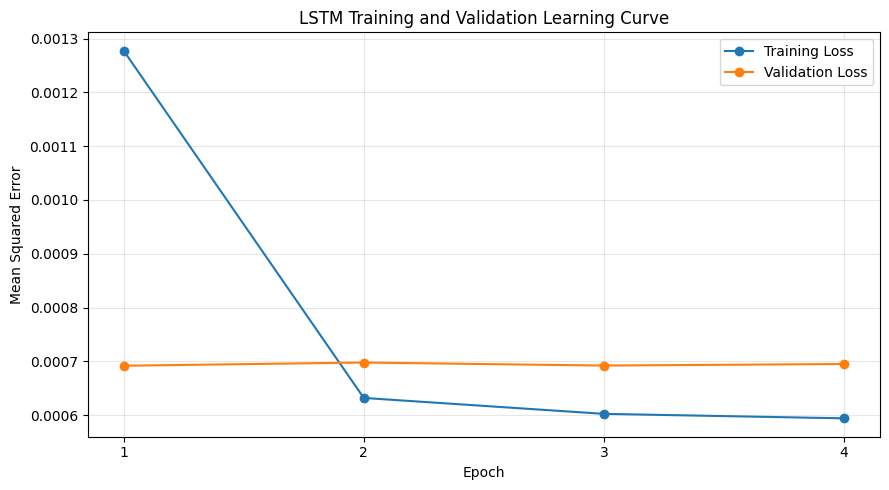

In [ ]:
import matplotlib.pyplot as plt

# Convert recorded training history into a DataFrame
history_df = pd.DataFrame(training_history)

plt.figure(figsize=(9, 5))

plt.plot(history_df["epoch"], history_df["train_loss"],
         marker="o", label="Training Loss")

plt.plot(history_df["epoch"], history_df["val_loss"],
         marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("LSTM Training and Validation Learning Curve")
plt.xticks(history_df["epoch"])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Audit next-observation target alignment and split boundaries.

audit_df = split_df.sort_values(
    ["backend", "qubit_a", "observed_time"]
).copy()

grouped = audit_df.groupby(
    ["backend", "qubit_a"], sort=False
)

# Recover the next observation's split and readout error.
audit_df["next_row_split"] = grouped["dataset_split"].shift(-1)
audit_df["next_row_error"] = grouped["current_error"].shift(-1)

# Verify that the target equals the next observation's error.
audit_df["target_matches_next_row"] = np.isclose(
    audit_df["target_next_error"],
    audit_df["next_row_error"],
    equal_nan=True
)

# Identify targets whose next observation belongs to another split.
audit_df["crosses_split_boundary"] = (
    audit_df["next_row_split"].notna()
    & (audit_df["dataset_split"] != audit_df["next_row_split"])
)

print("TARGET ALIGNMENT")
print(audit_df["target_matches_next_row"].value_counts(dropna=False))

print("\nSPLIT-BOUNDARY CROSSINGS")
print(audit_df["crosses_split_boundary"].value_counts())

print("\nCROSSINGS BY SPLIT")
print(
    audit_df.loc[audit_df["crosses_split_boundary"]]
    .groupby(["dataset_split", "next_row_split"])
    .size()
)

TARGET ALIGNMENT
target_matches_next_row
True     587289
False       601
Name: count, dtype: int64

SPLIT-BOUNDARY CROSSINGS
crosses_split_boundary
False    586688
True       1202
Name: count, dtype: int64

CROSSINGS BY SPLIT
dataset_split  next_row_split
train          validation        601
validation     test              601
dtype: int64


In [ ]:
# Inspect rows where the next-observation target does not match
# the next recorded observation in the same series.

mismatch_df = audit_df.loc[
    ~audit_df["target_matches_next_row"]
].copy()

print("MISMATCHED ROWS:", len(mismatch_df))

print("\nEXAMPLE MISMATCHES")
print(
    mismatch_df[
        [
            "backend",
            "qubit_a",
            "series_position",
            "series_size",
            "dataset_split",
            "target_next_error",
            "next_row_error"
        ]
    ].head(10).to_string(index=False)
)

print("\nMISMATCHES BY SPLIT")
print(mismatch_df["dataset_split"].value_counts())

print("\nSPLIT BOUNDARY POSITIONS — EXAMPLE SERIES")
for _, group in audit_df.groupby(["backend", "qubit_a"], sort=False):
    print(
        group[["series_position", "dataset_split"]]
        .tail(3)
        .to_string(index=False)
    )
    break

MISMATCHED ROWS: 601

EXAMPLE MISMATCHES
backend  qubit_a  series_position  series_size dataset_split  target_next_error  next_row_error
ibm_fez        0             1332         1333          test           0.020508             NaN
ibm_fez        1             1322         1323          test           0.059082             NaN
ibm_fez        2             1324         1325          test           0.000977             NaN
ibm_fez        3             1326         1327          test           0.032715             NaN
ibm_fez        4             1333         1334          test           0.005859             NaN
ibm_fez        5             1328         1329          test           0.003906             NaN
ibm_fez        6             1294         1295          test           0.008789             NaN
ibm_fez        7             1323         1324          test           0.028809             NaN
ibm_fez        8             1308         1309          test           0.005859             NaN

In [ ]:
# Assign each prediction to the split of its target observation.
# The final row in each series has no next observation and is excluded.

corrected_df = split_df.copy()

grouped = corrected_df.groupby(
    ["backend", "qubit_a"], sort=False
)

# The target belongs to the next observation's chronological split.
corrected_df["target_split"] = grouped["dataset_split"].shift(-1)

# Remove rows that have no next observation to predict.
corrected_df = corrected_df.dropna(
    subset=["target_split", "target_next_error"]
).copy()

# Use the target observation's split as the model split.
corrected_df["dataset_split"] = corrected_df["target_split"]
corrected_df = corrected_df.drop(columns=["target_split"])

# Rebuild the three datasets.
train_df = corrected_df[corrected_df["dataset_split"] == "train"].copy()
val_df = corrected_df[corrected_df["dataset_split"] == "validation"].copy()
test_df = corrected_df[corrected_df["dataset_split"] == "test"].copy()

print("CORRECTED SPLIT COUNTS")
print(corrected_df["dataset_split"].value_counts())

print("\nUNIQUE SERIES PER SPLIT")
for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(name, data.groupby(["backend", "qubit_a"]).ngroups)

print("\nTARGET SPLIT ALIGNMENT")
print(
    corrected_df.groupby(["backend", "qubit_a"])
    .size()
    .describe()
)

CORRECTED SPLIT COUNTS
dataset_split
train         410603
test           88478
validation     88208
Name: count, dtype: int64

UNIQUE SERIES PER SPLIT
Train 601
Validation 601
Test 601

TARGET SPLIT ALIGNMENT
count     601.000000
mean      977.186356
std       429.035106
min       214.000000
25%       938.000000
50%      1297.000000
75%      1313.000000
max      1333.000000
dtype: float64


In [ ]:
# Compare corrected split labels with the original next-observation split.
boundary_check = corrected_df.merge(
    audit_df[
        [
            "backend",
            "qubit_a",
            "series_position",
            "next_row_split",
            "target_matches_next_row"
        ]
    ],
    on=["backend", "qubit_a", "series_position"],
    how="left"
)

print("TARGET SPLIT MATCHES NEXT OBSERVATION:")
print(
    (boundary_check["dataset_split"] == boundary_check["next_row_split"])
    .value_counts()
)

print("\nTARGET VALUE ALIGNMENT:")
print(boundary_check["target_matches_next_row"].value_counts())

print("\nREMAINING SPLIT MISMATCHES:")
print(
    boundary_check.loc[
        boundary_check["dataset_split"] != boundary_check["next_row_split"],
        ["backend", "qubit_a", "series_position",
         "dataset_split", "next_row_split"]
    ].head()
)

TARGET SPLIT MATCHES NEXT OBSERVATION:
True    587289
Name: count, dtype: int64

TARGET VALUE ALIGNMENT:
target_matches_next_row
True    587289
Name: count, dtype: int64

REMAINING SPLIT MISMATCHES:
Empty DataFrame
Columns: [backend, qubit_a, series_position, dataset_split, next_row_split]
Index: []


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Evaluate the persistence prediction on each corrected split.
def evaluate_persistence(data, split_name):
    actual = data["target_next_error"].to_numpy()
    predicted = data["current_error"].to_numpy()

    return {
        "Split": split_name,
        "Observations": len(data),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

persistence_results_corrected = pd.DataFrame([
    evaluate_persistence(train_df, "Train"),
    evaluate_persistence(val_df, "Validation"),
    evaluate_persistence(test_df, "Test")
])

print("CORRECTED PERSISTENCE BASELINE")
display(persistence_results_corrected.round(6))

CORRECTED PERSISTENCE BASELINE


,Split,Observations,MAE,RMSE,R2
0,Train,410603,0.009143,0.030049,0.745703
1,Validation,88208,0.010397,0.033344,0.696412
2,Test,88478,0.013202,0.043243,0.654033


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import time

# Separate numerical and categorical model inputs.
numeric_features = features
categorical_features = ["backend", "qubit_a"]

X_train_lr = train_df[numeric_features + categorical_features]
X_val_lr = val_df[numeric_features + categorical_features]
y_train_lr = train_df[target]
y_val_lr = val_df[target]

# Scale numerical features and one-hot encode backend/qubit identities.
preprocessor_lr = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

linear_model_corrected = Pipeline([
    ("preprocessor", preprocessor_lr),
    ("model", LinearRegression())
])

# Train and measure training time.
start_time = time.time()
linear_model_corrected.fit(X_train_lr, y_train_lr)
lr_training_time = time.time() - start_time

# Evaluate on validation data only.
start_time = time.time()
lr_val_predictions_corrected = linear_model_corrected.predict(X_val_lr)
lr_prediction_time = time.time() - start_time

lr_corrected_results = {
    "Model": "Linear Regression",
    "MAE": mean_absolute_error(y_val_lr, lr_val_predictions_corrected),
    "RMSE": np.sqrt(mean_squared_error(y_val_lr, lr_val_predictions_corrected)),
    "R2": r2_score(y_val_lr, lr_val_predictions_corrected),
    "Training time (s)": lr_training_time,
    "Prediction time (s)": lr_prediction_time
}

print("CORRECTED LINEAR REGRESSION — VALIDATION")
display(pd.DataFrame([lr_corrected_results]).round(6))

CORRECTED LINEAR REGRESSION — VALIDATION


,Model,MAE,RMSE,R2,Training time (s),Prediction time (s)
0,Linear Regression,0.008743,0.026294,0.811217,4.545871,0.222296


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import time

# Prepare corrected training and validation inputs.
X_train_rf = train_df[numeric_features + categorical_features]
X_val_rf = val_df[numeric_features + categorical_features]
y_train_rf = train_df[target]
y_val_rf = val_df[target]

# Impute numerical values and encode backend/qubit identities.
preprocessor_rf = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

# Keep the previously tested, computationally controlled configuration.
rf_model_corrected = Pipeline([
    ("preprocessor", preprocessor_rf),
    ("model", RandomForestRegressor(
        n_estimators=40,
        max_depth=12,
        min_samples_leaf=10,
        max_features=0.5,
        random_state=42,
        n_jobs=2
    ))
])

# Train and measure runtime.
start_time = time.time()
rf_model_corrected.fit(X_train_rf, y_train_rf)
rf_training_time = time.time() - start_time

# Evaluate on validation data.
start_time = time.time()
rf_val_predictions_corrected = rf_model_corrected.predict(X_val_rf)
rf_prediction_time = time.time() - start_time

rf_corrected_results = {
    "Model": "Random Forest",
    "MAE": mean_absolute_error(y_val_rf, rf_val_predictions_corrected),
    "RMSE": np.sqrt(mean_squared_error(y_val_rf, rf_val_predictions_corrected)),
    "R2": r2_score(y_val_rf, rf_val_predictions_corrected),
    "Training time (s)": rf_training_time,
    "Prediction time (s)": rf_prediction_time
}

print("CORRECTED RANDOM FOREST — VALIDATION")
display(pd.DataFrame([rf_corrected_results]).round(6))

CORRECTED RANDOM FOREST — VALIDATION


,Model,MAE,RMSE,R2,Training time (s),Prediction time (s)
0,Random Forest,0.008733,0.026322,0.810805,271.027302,0.387373


In [ ]:
# Train LightGBM on the corrected chronological split
from lightgbm import LGBMRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import time

# Separate input features and prediction target
X_train_lgb = train_df[numeric_features + categorical_features]
X_val_lgb = val_df[numeric_features + categorical_features]
y_train_lgb = train_df[target]
y_val_lgb = val_df[target]

# Preprocess numerical and categorical columns
preprocessor_lgb = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

# Fit preprocessing only on training data
X_train_lgb_processed = preprocessor_lgb.fit_transform(X_train_lgb)
X_val_lgb_processed = preprocessor_lgb.transform(X_val_lgb)

# Configure the gradient-boosted model
lgb_model_corrected = LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=2,
    verbosity=-1
)

# Train and measure runtime
start_time = time.time()
lgb_model_corrected.fit(X_train_lgb_processed, y_train_lgb)
lgb_training_time = time.time() - start_time

# Generate validation predictions
start_time = time.time()
lgb_val_predictions_corrected = lgb_model_corrected.predict(X_val_lgb_processed)
lgb_prediction_time = time.time() - start_time

# Calculate validation metrics
lgb_corrected_results = {
    "Model": "LightGBM",
    "MAE": mean_absolute_error(y_val_lgb, lgb_val_predictions_corrected),
    "RMSE": np.sqrt(mean_squared_error(y_val_lgb, lgb_val_predictions_corrected)),
    "R2": r2_score(y_val_lgb, lgb_val_predictions_corrected),
    "Training time (s)": lgb_training_time,
    "Prediction time (s)": lgb_prediction_time
}

print("CORRECTED LIGHTGBM — VALIDATION")
display(pd.DataFrame([lgb_corrected_results]).round(6))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


CORRECTED LIGHTGBM — VALIDATION


,Model,MAE,RMSE,R2,Training time (s),Prediction time (s)
0,LightGBM,0.009064,0.028134,0.783867,20.014058,1.112885


In [ ]:
# Build chronological sequences and train the corrected LSTM
import numpy as np
import pandas as pd
import time
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Reproducibility and device selection
torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

# Scale numerical features using training data only
lstm_scaler = StandardScaler()
lstm_scaler.fit(train_df[numeric_features])

lstm_data = corrected_df.sort_values(
    ["backend", "qubit_a", "observed_time"]
).copy()

lstm_data[numeric_features] = lstm_scaler.transform(
    lstm_data[numeric_features]
)

# Create 10-step sequences independently for each backend-qubit series
SEQ_LEN = 10
X_train_seq, y_train_seq = [], []
X_val_seq, y_val_seq = [], []

for _, group in lstm_data.groupby(["backend", "qubit_a"], sort=False):
    values = group[numeric_features].to_numpy(dtype=np.float32)
    targets = group[target].to_numpy(dtype=np.float32)
    splits = group["dataset_split"].to_numpy()

    if len(group) < SEQ_LEN:
        continue

    # Each window ends at the input observation predicting its next observation
    windows = np.lib.stride_tricks.sliding_window_view(
        values, window_shape=SEQ_LEN, axis=0
    ).transpose(0, 2, 1)

    endpoint_targets = targets[SEQ_LEN - 1:]
    endpoint_splits = splits[SEQ_LEN - 1:]

    train_mask = endpoint_splits == "train"
    val_mask = endpoint_splits == "validation"

    X_train_seq.append(windows[train_mask])
    y_train_seq.append(endpoint_targets[train_mask])
    X_val_seq.append(windows[val_mask])
    y_val_seq.append(endpoint_targets[val_mask])

# Combine sequences from all independent series
X_train_seq = np.concatenate(X_train_seq).copy()
y_train_seq = np.concatenate(y_train_seq)
X_val_seq = np.concatenate(X_val_seq).copy()
y_val_seq = np.concatenate(y_val_seq)

print("Training sequences:", X_train_seq.shape)
print("Validation sequences:", X_val_seq.shape)

# Convert arrays to PyTorch tensors
train_dataset = TensorDataset(
    torch.tensor(X_train_seq),
    torch.tensor(y_train_seq).unsqueeze(1)
)
val_dataset = TensorDataset(
    torch.tensor(X_val_seq),
    torch.tensor(y_val_seq).unsqueeze(1)
)

train_loader = DataLoader(train_dataset, batch_size=512, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=512, shuffle=False)

# Define a compact LSTM regression model
class ReadoutLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=32):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )
        self.dropout = nn.Dropout(0.2)
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        sequence_output, _ = self.lstm(x)
        last_output = sequence_output[:, -1, :]
        return self.output(self.dropout(last_output))

lstm_model_corrected = ReadoutLSTM(
    input_size=len(numeric_features)
).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(lstm_model_corrected.parameters(), lr=0.001)

# Train with validation-loss early stopping
EPOCHS = 8
best_val_loss = float("inf")
best_state = None
patience = 2
epochs_without_improvement = 0
lstm_history = []

start_time = time.time()

for epoch in range(EPOCHS):
    lstm_model_corrected.train()
    train_losses = []

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        predictions = lstm_model_corrected(xb)
        loss = criterion(predictions, yb)
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())

    lstm_model_corrected.eval()
    val_losses = []

    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            predictions = lstm_model_corrected(xb)
            val_losses.append(criterion(predictions, yb).item())

    train_loss = float(np.mean(train_losses))
    val_loss = float(np.mean(val_losses))
    lstm_history.append({
        "Epoch": epoch + 1,
        "Training loss": train_loss,
        "Validation loss": val_loss
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train loss: {train_loss:.6f} | "
        f"Validation loss: {val_loss:.6f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in lstm_model_corrected.state_dict().items()
        }
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print("Early stopping triggered.")
            break

lstm_training_time = time.time() - start_time

# Restore the best validation checkpoint
lstm_model_corrected.load_state_dict(best_state)
lstm_model_corrected.eval()

# Generate validation predictions
start_time = time.time()
predictions = []

with torch.no_grad():
    for xb, _ in val_loader:
        predictions.extend(
            lstm_model_corrected(xb.to(device)).cpu().numpy().ravel()
        )

lstm_prediction_time = time.time() - start_time
lstm_val_predictions_corrected = np.array(predictions)

# Calculate validation metrics
lstm_corrected_results = {
    "Model": "LSTM",
    "MAE": mean_absolute_error(y_val_seq, lstm_val_predictions_corrected),
    "RMSE": np.sqrt(mean_squared_error(y_val_seq, lstm_val_predictions_corrected)),
    "R2": r2_score(y_val_seq, lstm_val_predictions_corrected),
    "Training time (s)": lstm_training_time,
    "Prediction time (s)": lstm_prediction_time
}

print("\nCORRECTED LSTM — VALIDATION")
display(pd.DataFrame([lstm_corrected_results]).round(6))

Training device: cpu
Training sequences: (405194, 10, 15)
Validation sequences: (88208, 10, 15)
Epoch 1/8 | Train loss: 0.000720 | Validation loss: 0.000694
Epoch 2/8 | Train loss: 0.000594 | Validation loss: 0.000698
Epoch 3/8 | Train loss: 0.000584 | Validation loss: 0.000698
Early stopping triggered.

CORRECTED LSTM — VALIDATION


,Model,MAE,RMSE,R2,Training time (s),Prediction time (s)
0,LSTM,0.00871,0.026404,0.809632,86.556018,3.392225


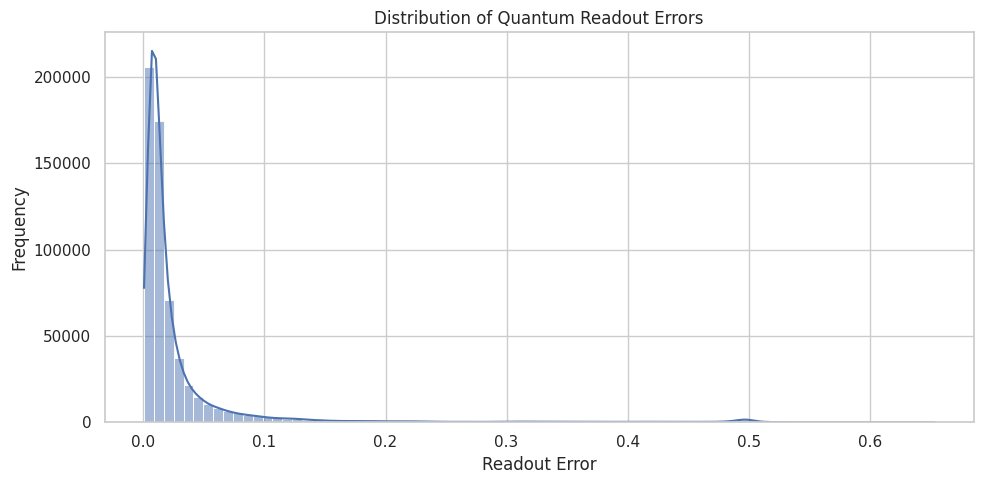

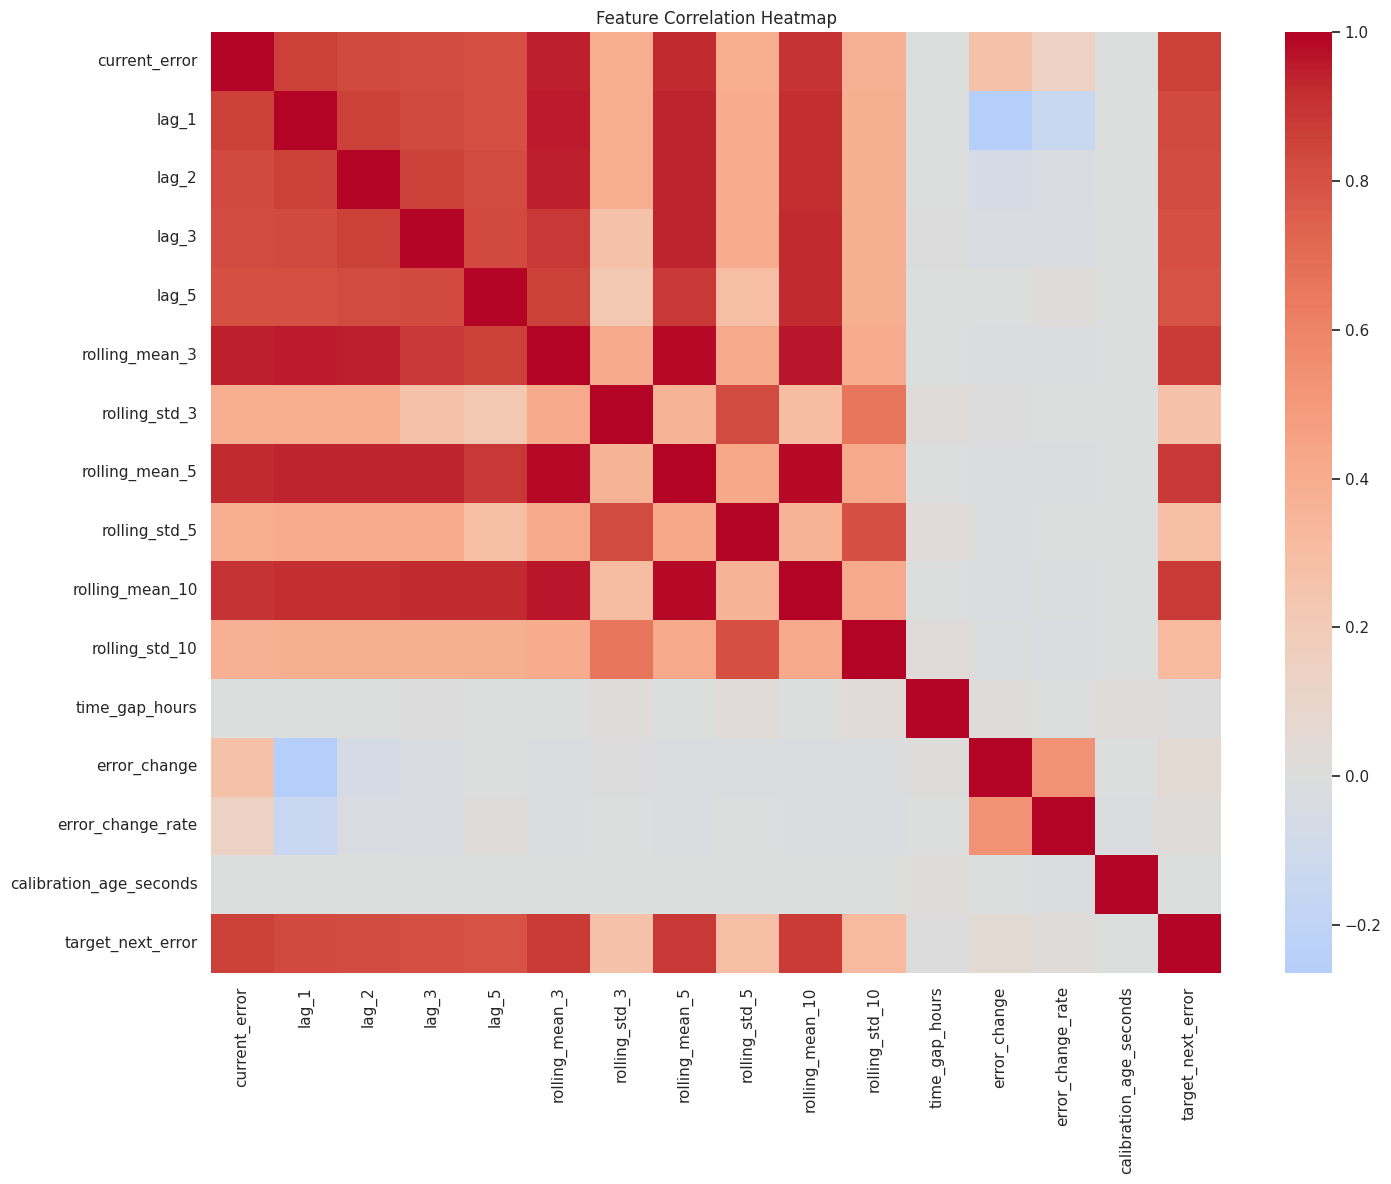

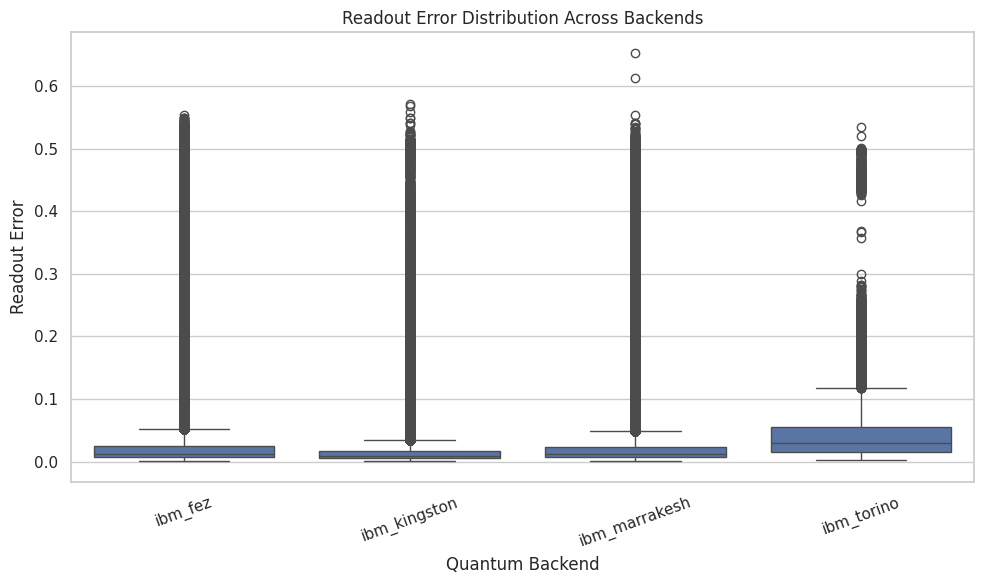

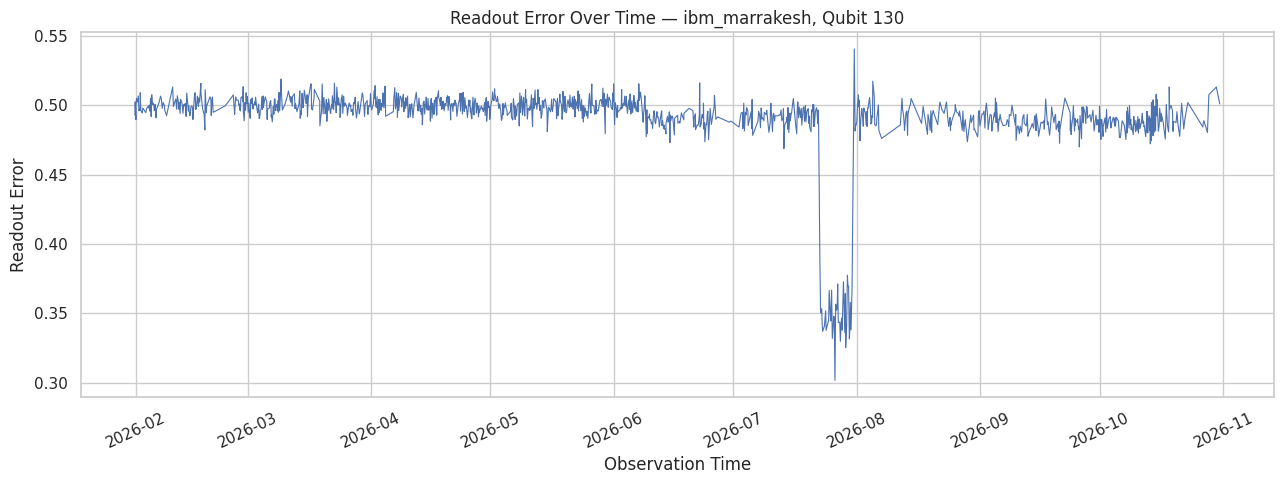

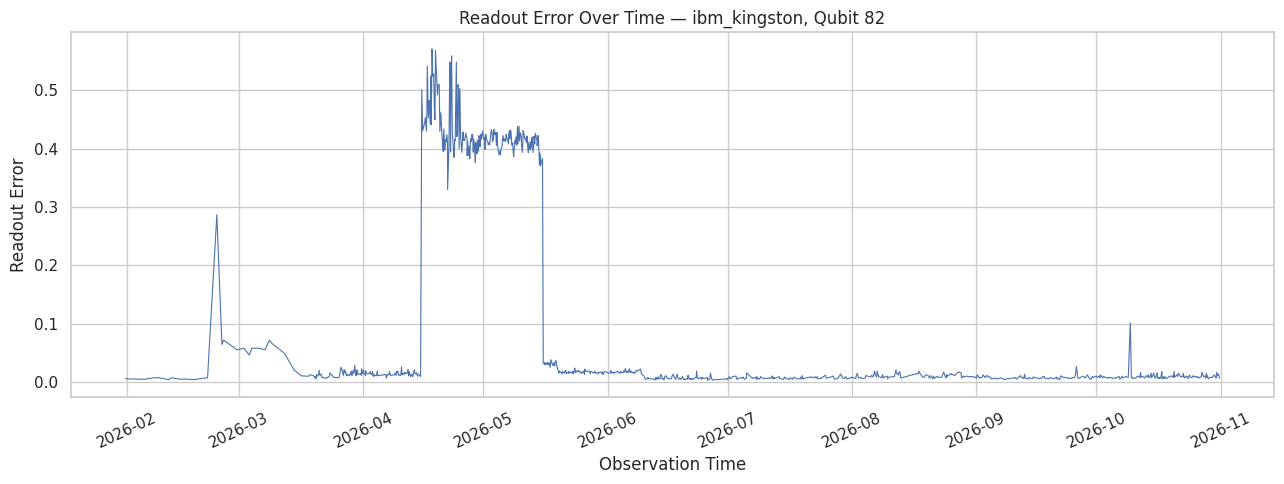

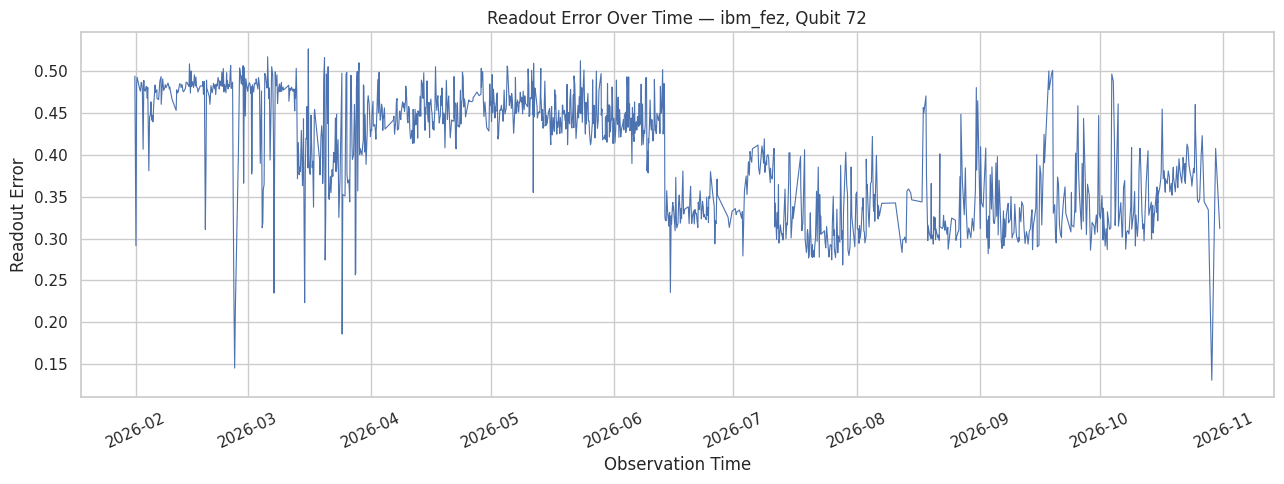

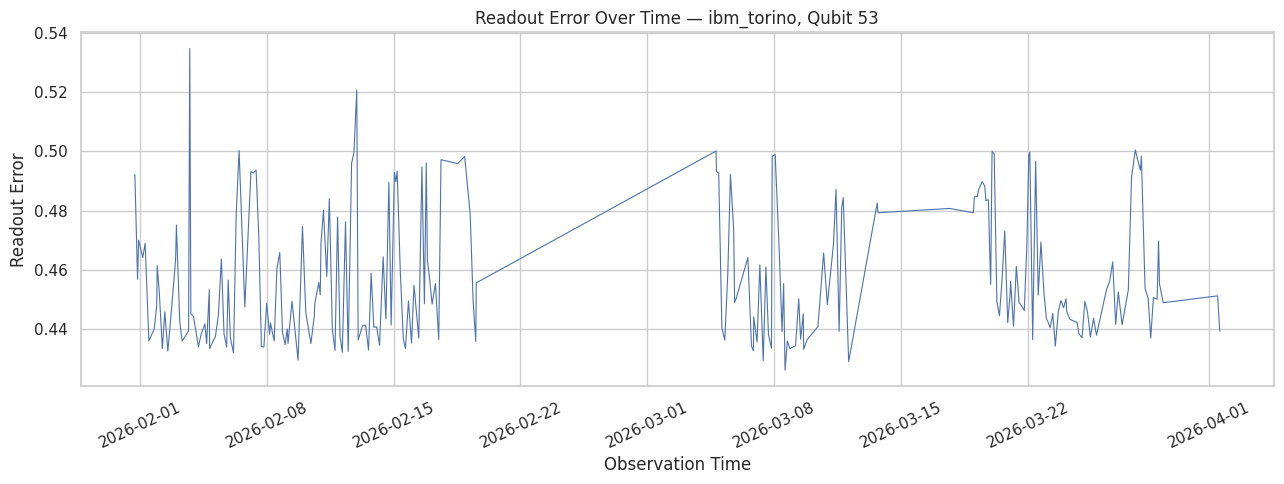

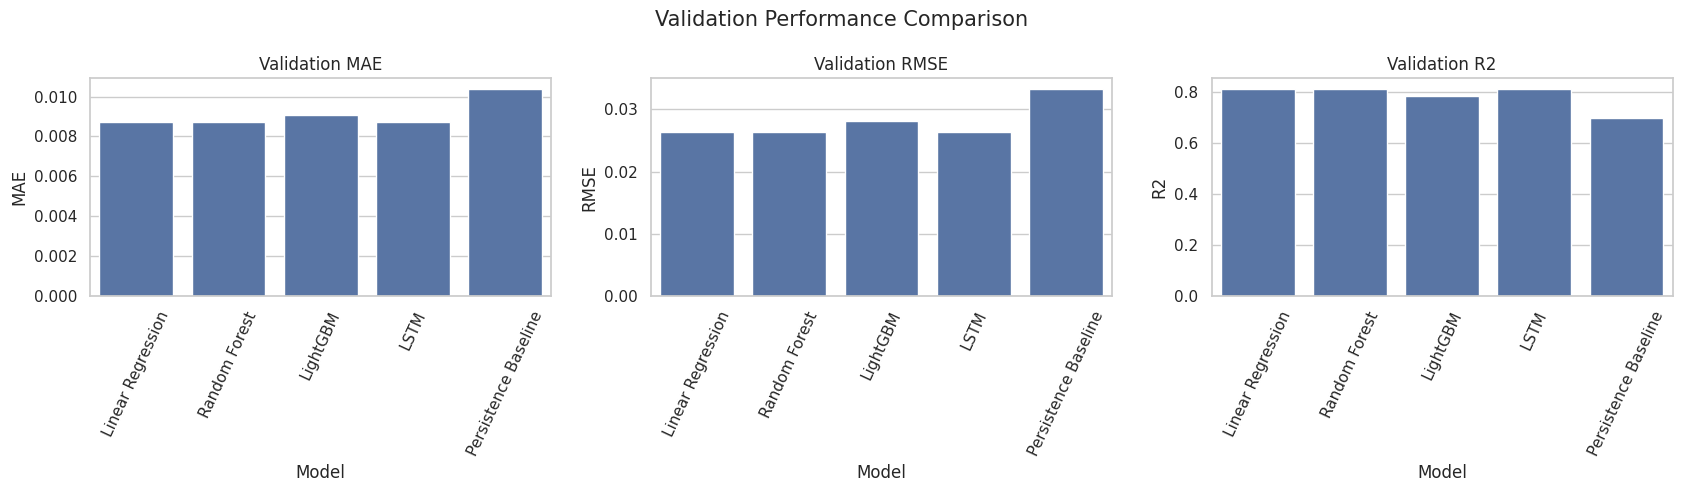

,Model,MAE,RMSE,R2,Training time (s),Prediction time (s)
0,Linear Regression,0.008743,0.026294,0.811217,4.545871,0.222296
1,Random Forest,0.008733,0.026322,0.810805,271.027302,0.387373
2,LightGBM,0.009064,0.028134,0.783867,20.014058,1.112885
3,LSTM,0.008710,0.026404,0.809632,86.556018,3.392225
4,Persistence Baseline,0.010397,0.033344,0.696412,NaN,NaN


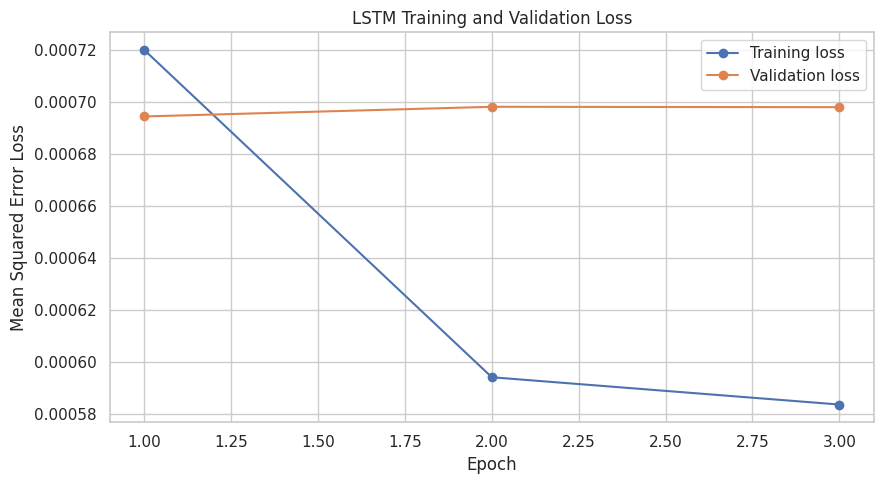

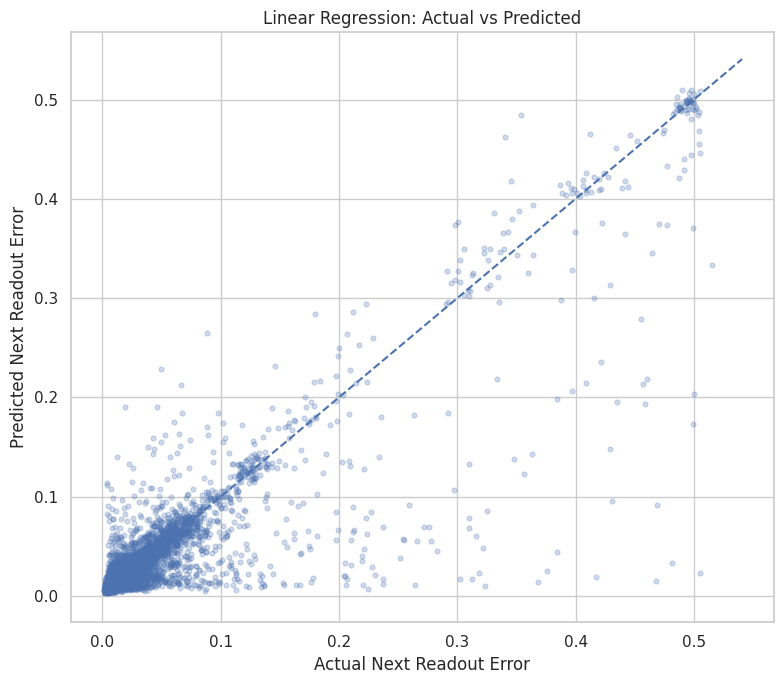

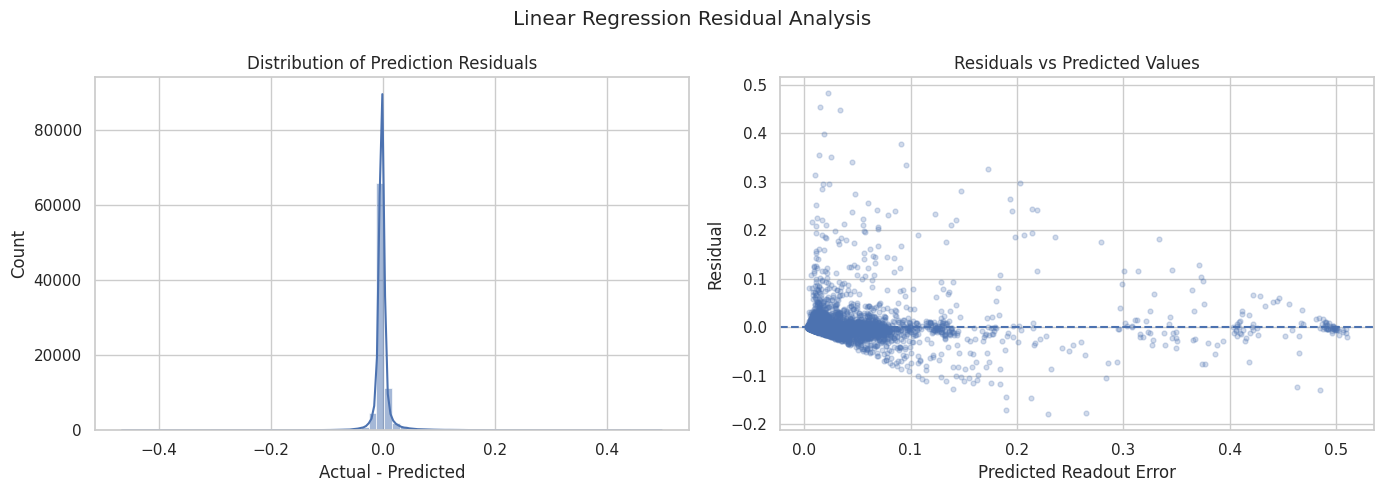

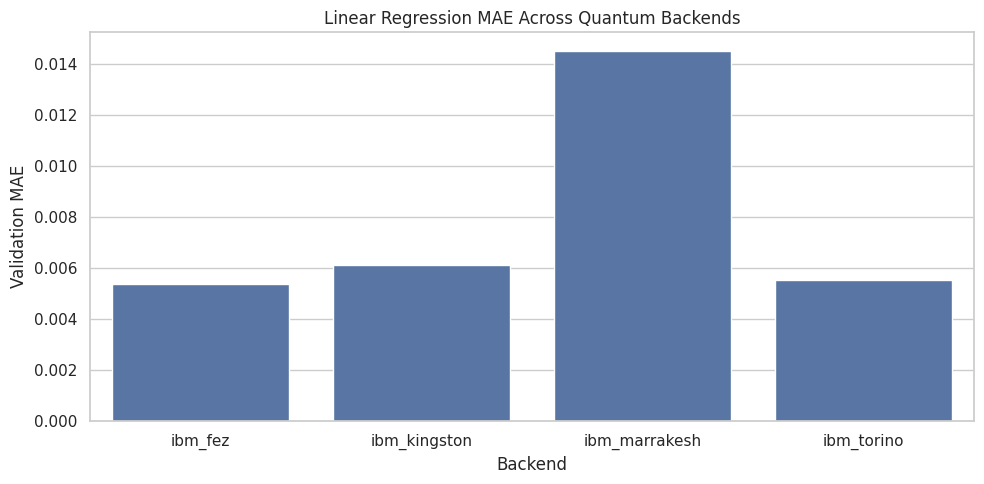

,Backend,Observations,MAE,RMSE,R2
0,ibm_fez,30813,0.005362,0.017389,0.776106
1,ibm_kingston,22187,0.006113,0.018396,0.894301
2,ibm_marrakesh,30701,0.014509,0.037761,0.774521
3,ibm_torino,4507,0.005542,0.009211,0.965880



========== PRELIMINARY RESEARCH FINDINGS ==========
Dataset observations: 593900
Backend-qubit series: 601
Mean readout error: 0.029312
Median readout error: 0.011719
Maximum readout error: 0.653564

Selected model: Linear Regression
Validation MAE: 0.008743
Validation RMSE: 0.026294
Validation R2: 0.811217

All figures saved in: /content/research_figures


In [ ]:
# ============================================================
# RESEARCH VISUALISATION PACKAGE — QUANTUM READOUT ERROR
# Uses existing dataset, trained models and validation results.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create a folder for all research figures
FIG_DIR = "/content/research_figures"
os.makedirs(FIG_DIR, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(
        os.path.join(FIG_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

# ------------------------------------------------------------
# 1. READOUT ERROR DISTRIBUTION
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))
sns.histplot(
    model_df["readout_error"],
    bins=80,
    kde=True
)
plt.title("Distribution of Quantum Readout Errors")
plt.xlabel("Readout Error")
plt.ylabel("Frequency")
save_plot("01_readout_error_distribution.png")

# ------------------------------------------------------------
# 2. FEATURE CORRELATION HEATMAP
# ------------------------------------------------------------

corr_columns = numeric_features + [target]

correlation_data = feature_df[corr_columns].corr()

plt.figure(figsize=(15, 12))
sns.heatmap(
    correlation_data,
    cmap="coolwarm",
    center=0,
    annot=False,
    square=False
)
plt.title("Feature Correlation Heatmap")
save_plot("02_correlation_heatmap.png")

# ------------------------------------------------------------
# 3. READOUT ERROR BY BACKEND
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=model_df,
    x="backend",
    y="readout_error"
)
plt.title("Readout Error Distribution Across Backends")
plt.xlabel("Quantum Backend")
plt.ylabel("Readout Error")
plt.xticks(rotation=20)
save_plot("03_backend_error_distribution.png")

# ------------------------------------------------------------
# 4. SELECTED QUBIT TIME SERIES
# ------------------------------------------------------------

selected_qubits = [
    ("ibm_marrakesh", 130),
    ("ibm_kingston", 82),
    ("ibm_fez", 72),
    ("ibm_torino", 53)
]

for backend_name, qubit_number in selected_qubits:

    series = model_df[
        (model_df["backend"] == backend_name) &
        (model_df["qubit_a"] == qubit_number)
    ].sort_values("observed_time")

    if len(series) == 0:
        continue

    plt.figure(figsize=(13, 5))
    plt.plot(
        series["observed_time"],
        series["readout_error"],
        linewidth=0.8
    )
    plt.title(
        f"Readout Error Over Time — {backend_name}, Qubit {qubit_number}"
    )
    plt.xlabel("Observation Time")
    plt.ylabel("Readout Error")
    plt.xticks(rotation=25)
    save_plot(f"04_timeseries_{backend_name}_q{qubit_number}.png")

# ------------------------------------------------------------
# 5. MODEL COMPARISON
# ------------------------------------------------------------

validation_results = pd.DataFrame([
    lr_corrected_results,
    rf_corrected_results,
    lgb_corrected_results,
    lstm_corrected_results,
    {
        "Model": "Persistence Baseline",
        "MAE": persistence_results_corrected.loc[
            persistence_results_corrected["Split"] == "Validation", "MAE"
        ].iloc[0],
        "RMSE": persistence_results_corrected.loc[
            persistence_results_corrected["Split"] == "Validation", "RMSE"
        ].iloc[0],
        "R2": persistence_results_corrected.loc[
            persistence_results_corrected["Split"] == "Validation", "R2"
        ].iloc[0]
    }
])

metrics = ["MAE", "RMSE", "R2"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, metric in zip(axes, metrics):
    sns.barplot(
        data=validation_results,
        x="Model",
        y=metric,
        ax=ax
    )
    ax.set_title(f"Validation {metric}")
    ax.tick_params(axis="x", rotation=65)

fig.suptitle("Validation Performance Comparison", fontsize=15)
plt.tight_layout()
plt.savefig(
    os.path.join(FIG_DIR, "05_model_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

display(validation_results.round(6))

# ------------------------------------------------------------
# 6. LSTM TRAINING AND VALIDATION LOSS
# ------------------------------------------------------------

history_df = pd.DataFrame(lstm_history)

plt.figure(figsize=(9, 5))
plt.plot(history_df["Epoch"], history_df["Training loss"],
         marker="o", label="Training loss")
plt.plot(history_df["Epoch"], history_df["Validation loss"],
         marker="o", label="Validation loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error Loss")
plt.legend()
save_plot("06_lstm_loss.png")

# ------------------------------------------------------------
# 7. LINEAR REGRESSION ACTUAL VS PREDICTED
# ------------------------------------------------------------

actual = y_val_lr.to_numpy()
predicted = lr_val_predictions_corrected

# Sample points for a readable scatter plot
rng = np.random.default_rng(42)
sample_size = min(10000, len(actual))
sample_indices = rng.choice(len(actual), sample_size, replace=False)

plt.figure(figsize=(8, 7))
plt.scatter(
    actual[sample_indices],
    predicted[sample_indices],
    alpha=0.25,
    s=12
)

lower = min(actual.min(), predicted.min())
upper = max(actual.max(), predicted.max())

plt.plot([lower, upper], [lower, upper], linestyle="--")
plt.title("Linear Regression: Actual vs Predicted")
plt.xlabel("Actual Next Readout Error")
plt.ylabel("Predicted Next Readout Error")
save_plot("07_actual_vs_predicted.png")

# ------------------------------------------------------------
# 8. RESIDUAL DIAGNOSTICS
# ------------------------------------------------------------

residuals = actual - predicted

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(residuals, bins=70, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Prediction Residuals")
axes[0].set_xlabel("Actual - Predicted")

axes[1].scatter(
    predicted[sample_indices],
    residuals[sample_indices],
    alpha=0.25,
    s=12
)
axes[1].axhline(0, linestyle="--")
axes[1].set_title("Residuals vs Predicted Values")
axes[1].set_xlabel("Predicted Readout Error")
axes[1].set_ylabel("Residual")

fig.suptitle("Linear Regression Residual Analysis")
plt.tight_layout()
plt.savefig(
    os.path.join(FIG_DIR, "08_residual_diagnostics.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# ------------------------------------------------------------
# 9. BACKEND-WISE VALIDATION PERFORMANCE
# ------------------------------------------------------------

backend_results = []

validation_copy = val_df.copy()
validation_copy["predicted"] = lr_val_predictions_corrected

for backend_name, group in validation_copy.groupby("backend"):

    backend_results.append({
        "Backend": backend_name,
        "Observations": len(group),
        "MAE": mean_absolute_error(group[target], group["predicted"]),
        "RMSE": np.sqrt(mean_squared_error(group[target], group["predicted"])),
        "R2": r2_score(group[target], group["predicted"])
    })

backend_results = pd.DataFrame(backend_results)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=backend_results,
    x="Backend",
    y="MAE"
)
plt.title("Linear Regression MAE Across Quantum Backends")
plt.ylabel("Validation MAE")
save_plot("09_backend_model_performance.png")

display(backend_results.round(6))

# ------------------------------------------------------------
# 10. PRELIMINARY RESEARCH SUMMARY
# ------------------------------------------------------------

print("\n========== PRELIMINARY RESEARCH FINDINGS ==========")

print("Dataset observations:", len(model_df))
print("Backend-qubit series:", model_df.groupby(
    ["backend", "qubit_a"]
).ngroups)

print("Mean readout error:", round(model_df["readout_error"].mean(), 6))
print("Median readout error:", round(model_df["readout_error"].median(), 6))
print("Maximum readout error:", round(model_df["readout_error"].max(), 6))

print("\nSelected model: Linear Regression")
print("Validation MAE:", round(lr_corrected_results["MAE"], 6))
print("Validation RMSE:", round(lr_corrected_results["RMSE"], 6))
print("Validation R2:", round(lr_corrected_results["R2"], 6))

print("\nAll figures saved in:", FIG_DIR)
print("===================================================")

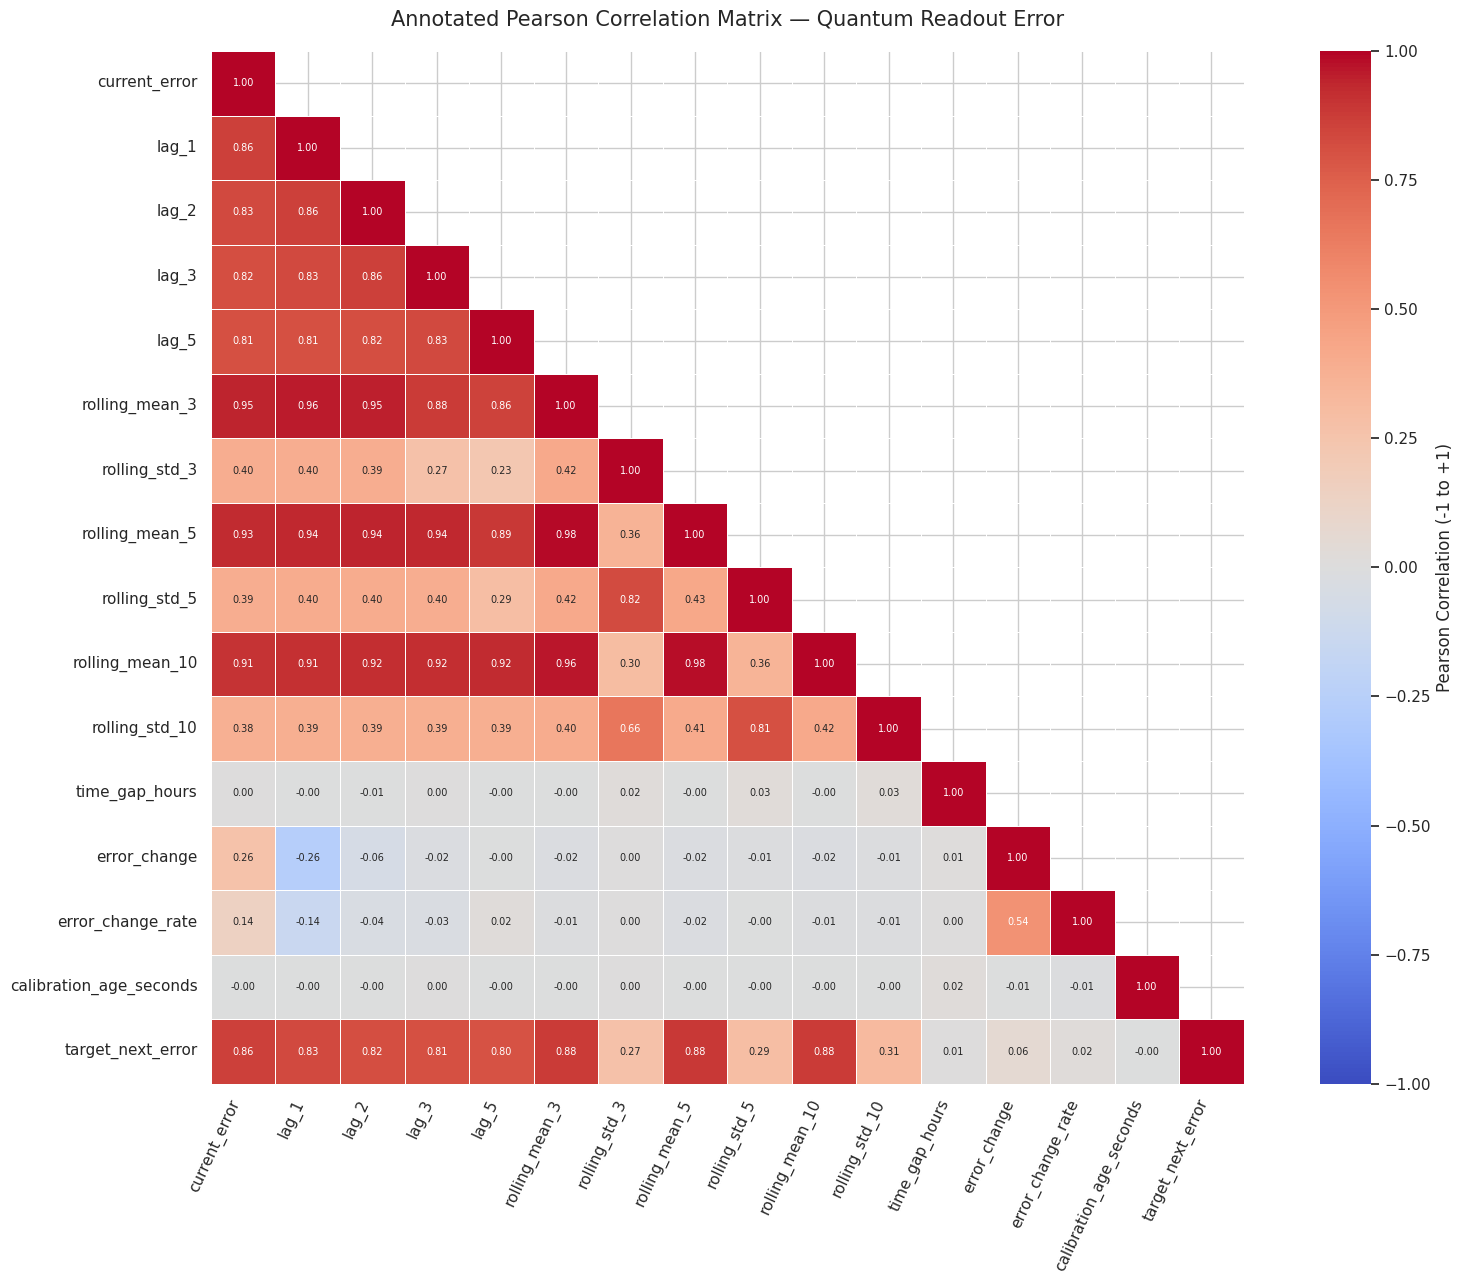

In [ ]:
# ANNOTATED PEARSON CORRELATION MATRIX

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Include engineered numerical features and the prediction target
corr_columns = numeric_features + [target]

correlation_data = feature_df[corr_columns].corr(method="pearson")

# Hide the duplicate upper triangle for easier reading
mask = np.triu(np.ones_like(correlation_data, dtype=bool), k=1)

plt.figure(figsize=(17, 13))

sns.heatmap(
    correlation_data,
    mask=mask,
    annot=True,              # Display numerical correlation values
    fmt=".2f",               # Show two decimal places
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.4,
    annot_kws={"size": 7},
    cbar_kws={"label": "Pearson Correlation (-1 to +1)"}
)

plt.title(
    "Annotated Pearson Correlation Matrix — Quantum Readout Error",
    fontsize=15,
    pad=18
)
plt.xticks(rotation=65, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "/content/research_figures/02_annotated_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:

import time
import json
import joblib
import numpy as np
import pandas as pd
from lightgbm import LGBMRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the existing project features and corrected chronological split
X_train = train_df[numeric_features + categorical_features]
y_train = train_df[target].to_numpy()

X_val = val_df[numeric_features + categorical_features]
y_val = val_df[target].to_numpy()

# A compact search space: enough variation without wasting presentation time
configurations = [
    {"n_estimators": 300, "learning_rate": 0.03, "num_leaves": 15, "max_depth": -1, "reg_lambda": 1.0},
    {"n_estimators": 500, "learning_rate": 0.05, "num_leaves": 31, "max_depth": -1, "reg_lambda": 1.0},
    {"n_estimators": 700, "learning_rate": 0.03, "num_leaves": 31, "max_depth": -1, "reg_lambda": 2.0},
    {"n_estimators": 500, "learning_rate": 0.05, "num_leaves": 15, "max_depth": 8,  "reg_lambda": 2.0},
    {"n_estimators": 700, "learning_rate": 0.05, "num_leaves": 63, "max_depth": -1, "reg_lambda": 2.0},
    {"n_estimators": 300, "learning_rate": 0.08, "num_leaves": 31, "max_depth": 8,  "reg_lambda": 0.5},
    {"n_estimators": 500, "learning_rate": 0.02, "num_leaves": 31, "max_depth": 12, "reg_lambda": 3.0},
    {"n_estimators": 700, "learning_rate": 0.03, "num_leaves": 15, "max_depth": 8,  "reg_lambda": 1.0},
]

tuning_results = []
best_model = None
best_rmse = float("inf")

for i, params in enumerate(configurations, start=1):
    print(f"\nTraining configuration {i}/{len(configurations)}: {params}")

    # Preprocessing is fitted on training data only
    preprocessor = ColumnTransformer([
        ("numeric", "passthrough", numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", LGBMRegressor(
            **params,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42,
            n_jobs=2,
            verbosity=-1
        ))
    ])

    start = time.time()
    model.fit(X_train, y_train)
    train_seconds = time.time() - start

    predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    r2 = r2_score(y_val, predictions)

    tuning_results.append({
        "configuration": i,
        **params,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "training_seconds": train_seconds
    })

    print(f"MAE: {mae:.6f} | RMSE: {rmse:.6f} | R²: {r2:.6f}")
    print(f"Training time: {train_seconds:.2f} seconds")

    if rmse < best_rmse:
        best_rmse = rmse
        best_model = model

# Rank all configurations by validation RMSE
tuning_results_df = pd.DataFrame(tuning_results).sort_values("RMSE").reset_index(drop=True)

print("\n========== HYPERPARAMETER TUNING RESULTS ==========")
display(tuning_results_df)

# Compare against existing validation results
comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE": lr_corrected_results["MAE"],
        "RMSE": lr_corrected_results["RMSE"],
        "R2": lr_corrected_results["R2"]
    },
    {
        "Model": "Original LightGBM",
        "MAE": lgb_corrected_results["MAE"],
        "RMSE": lgb_corrected_results["RMSE"],
        "R2": lgb_corrected_results["R2"]
    },
    {
        "Model": "Tuned LightGBM",
        "MAE": tuning_results_df.iloc[0]["MAE"],
        "RMSE": tuning_results_df.iloc[0]["RMSE"],
        "R2": tuning_results_df.iloc[0]["R2"]
    }
]).sort_values("RMSE")

print("\n========== VALIDATION MODEL COMPARISON ==========")
display(comparison)

# Save the tuning evidence and selected model for later use
import os
os.makedirs("/content/research_figures", exist_ok=True)

tuning_results_df.to_csv(
    "/content/research_figures/lightgbm_tuning_results.csv", index=False
)
joblib.dump(best_model, "/content/tuned_lightgbm_model.joblib")

print("\nBest configuration:")
print(tuning_results_df.iloc[0].to_dict())
print("\nSaved tuning results and selected model.")



Training configuration 1/8: {'n_estimators': 300, 'learning_rate': 0.03, 'num_leaves': 15, 'max_depth': -1, 'reg_lambda': 1.0}


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


MAE: 0.008976 | RMSE: 0.027528 | R²: 0.793083
Training time: 19.66 seconds

Training configuration 2/8: {'n_estimators': 500, 'learning_rate': 0.05, 'num_leaves': 31, 'max_depth': -1, 'reg_lambda': 1.0}


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


MAE: 0.009064 | RMSE: 0.028134 | R²: 0.783867
Training time: 15.06 seconds

Training configuration 3/8: {'n_estimators': 700, 'learning_rate': 0.03, 'num_leaves': 31, 'max_depth': -1, 'reg_lambda': 2.0}


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


... (11 outputs left out)

,configuration,n_estimators,learning_rate,num_leaves,max_depth,reg_lambda,MAE,RMSE,R2,training_seconds
0,1,300,0.03,15,-1,1.0,0.008976,0.027528,0.793083,19.662798
1,8,700,0.03,15,8,1.0,0.008963,0.027868,0.787938,21.226695
2,7,500,0.02,31,12,3.0,0.009001,0.027907,0.787343,16.962604
3,6,300,0.08,31,8,0.5,0.008962,0.027992,0.786041,11.163935
4,4,500,0.05,15,8,2.0,0.009001,0.028008,0.785799,13.943475
5,2,500,0.05,31,-1,1.0,0.009064,0.028134,0.783867,15.064724
6,3,700,0.03,31,-1,2.0,0.009072,0.028257,0.781971,22.617240
7,5,700,0.05,63,-1,2.0,0.009136,0.028442,0.779111,24.401209



========== VALIDATION MODEL COMPARISON ==========


,Model,MAE,RMSE,R2
0,Linear Regression,0.008743,0.026294,0.811217
2,Tuned LightGBM,0.008976,0.027528,0.793083
1,Original LightGBM,0.009064,0.028134,0.783867



Best configuration:
{'configuration': 1.0, 'n_estimators': 300.0, 'learning_rate': 0.03, 'num_leaves': 15.0, 'max_depth': -1.0, 'reg_lambda': 1.0, 'MAE': 0.008976095439707848, 'RMSE': 0.02752772815896935, 'R2': 0.79308295518605, 'training_seconds': 19.662797689437866}

Saved tuning results and selected model.


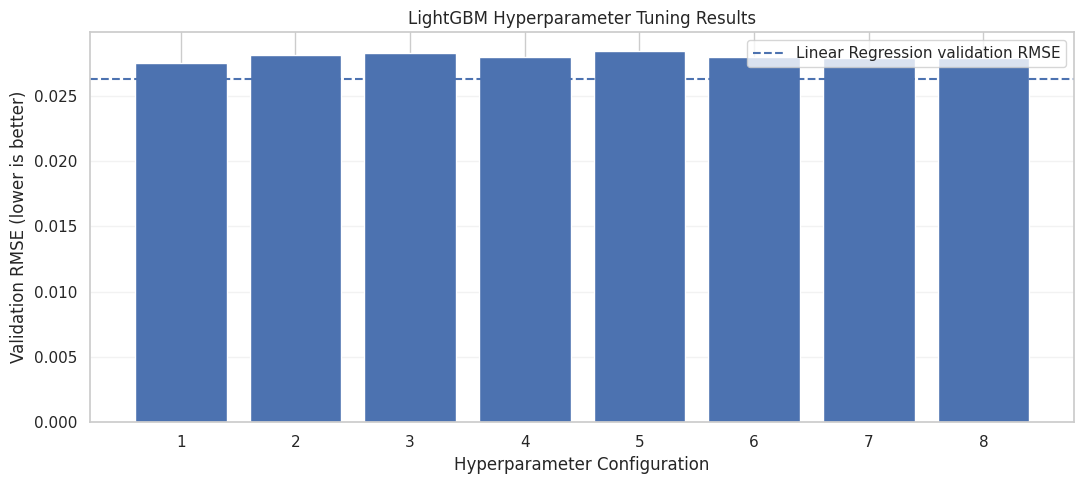

Figure saved successfully.


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Compare validation RMSE across all tested LightGBM configurations
plot_data = tuning_results_df.sort_values("configuration")

plt.figure(figsize=(11, 5))
plt.bar(
    plot_data["configuration"].astype(str),
    plot_data["RMSE"]
)

plt.axhline(
    lr_corrected_results["RMSE"],
    linestyle="--",
    label="Linear Regression validation RMSE"
)

plt.xlabel("Hyperparameter Configuration")
plt.ylabel("Validation RMSE (lower is better)")
plt.title("LightGBM Hyperparameter Tuning Results")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    "/content/research_figures/11_lightgbm_hyperparameter_tuning.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Figure saved successfully.")


Training Random Forest configuration 1/4
{'n_estimators': 20, 'max_depth': 8, 'min_samples_leaf': 10, 'max_features': 0.5}
MAE: 0.008712 | RMSE: 0.026254 | R²: 0.811788
Training time: 66.9 seconds

Training Random Forest configuration 2/4
{'n_estimators': 20, 'max_depth': 12, 'min_samples_leaf': 10, 'max_features': 0.5}
MAE: 0.008740 | RMSE: 0.026347 | R²: 0.810448
Training time: 130.4 seconds

Training Random Forest configuration 3/4
{'n_estimators': 20, 'max_depth': 16, 'min_samples_leaf': 20, 'max_features': 0.75}
MAE: 0.008749 | RMSE: 0.026400 | R²: 0.809689
Training time: 330.2 seconds

Training Random Forest configuration 4/4
{'n_estimators': 20, 'max_depth': None, 'min_samples_leaf': 20, 'max_features': 0.5}
MAE: 0.008762 | RMSE: 0.026311 | R²: 0.810975
Training time: 648.5 seconds

========== RANDOM FOREST TUNING RESULTS ==========


,configuration,n_estimators,max_depth,min_samples_leaf,max_features,MAE,RMSE,R2,training_seconds
0,1,20,8.0,10,0.50,0.008712,0.026254,0.811788,66.901405
1,4,20,NaN,20,0.50,0.008762,0.026311,0.810975,648.543329
2,2,20,12.0,10,0.50,0.008740,0.026347,0.810448,130.404230
3,3,20,16.0,20,0.75,0.008749,0.026400,0.809689,330.239968



========== MODEL COMPARISON ==========


,Model,MAE,RMSE,R2
2,Tuned Random Forest,0.008712,0.026254,0.811788
0,Linear Regression,0.008743,0.026294,0.811217
1,Original Random Forest,0.008733,0.026322,0.810805
4,Tuned LightGBM,0.008976,0.027528,0.793083
3,Original LightGBM,0.009064,0.028134,0.783867


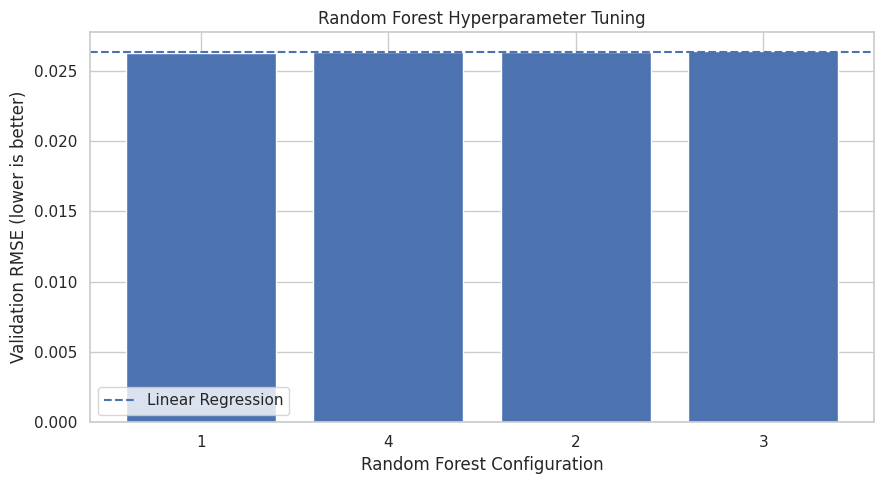


Best Random Forest configuration:
{'configuration': 1.0, 'n_estimators': 20.0, 'max_depth': 8.0, 'min_samples_leaf': 10.0, 'max_features': 0.5, 'MAE': 0.008711982291395868, 'RMSE': 0.026253994294163297, 'R2': 0.8117884382451757, 'training_seconds': 66.90140461921692}

Saved tuning results, model, and figure.


In [ ]:

import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prepare the same corrected training and validation observations
X_train = train_df[numeric_features + categorical_features]
y_train = train_df[target].to_numpy()

X_val = val_df[numeric_features + categorical_features]
y_val = val_df[target].to_numpy()

# Four controlled configurations to compare tree complexity and regularisation
rf_configurations = [
    {"n_estimators": 20, "max_depth": 8,  "min_samples_leaf": 10, "max_features": 0.5},
    {"n_estimators": 20, "max_depth": 12, "min_samples_leaf": 10, "max_features": 0.5},
    {"n_estimators": 20, "max_depth": 16, "min_samples_leaf": 20, "max_features": 0.75},
    {"n_estimators": 20, "max_depth": None, "min_samples_leaf": 20, "max_features": 0.5}
]

rf_tuning_results = []
best_rf_model = None
best_rf_rmse = float("inf")

for i, params in enumerate(rf_configurations, start=1):
    print(f"\nTraining Random Forest configuration {i}/{len(rf_configurations)}")
    print(params)

    # Fit categorical encoding using training data only
    preprocessor = ColumnTransformer([
        ("numeric", "passthrough", numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ])

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            **params,
            random_state=42,
            n_jobs=2
        ))
    ])

    start = time.time()
    model.fit(X_train, y_train)
    training_seconds = time.time() - start

    predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    r2 = r2_score(y_val, predictions)

    rf_tuning_results.append({
        "configuration": i,
        **params,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "training_seconds": training_seconds
    })

    print(f"MAE: {mae:.6f} | RMSE: {rmse:.6f} | R²: {r2:.6f}")
    print(f"Training time: {training_seconds:.1f} seconds")

    if rmse < best_rf_rmse:
        best_rf_rmse = rmse
        best_rf_model = model

# Rank configurations by validation RMSE
rf_tuning_results_df = (
    pd.DataFrame(rf_tuning_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("\n========== RANDOM FOREST TUNING RESULTS ==========")
display(rf_tuning_results_df)

# Compare original and tuned Random Forest against existing models
rf_comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE": lr_corrected_results["MAE"],
        "RMSE": lr_corrected_results["RMSE"],
        "R2": lr_corrected_results["R2"]
    },
    {
        "Model": "Original Random Forest",
        "MAE": rf_corrected_results["MAE"],
        "RMSE": rf_corrected_results["RMSE"],
        "R2": rf_corrected_results["R2"]
    },
    {
        "Model": "Tuned Random Forest",
        "MAE": rf_tuning_results_df.iloc[0]["MAE"],
        "RMSE": rf_tuning_results_df.iloc[0]["RMSE"],
        "R2": rf_tuning_results_df.iloc[0]["R2"]
    },
    {
        "Model": "Original LightGBM",
        "MAE": lgb_corrected_results["MAE"],
        "RMSE": lgb_corrected_results["RMSE"],
        "R2": lgb_corrected_results["R2"]
    },
    {
        "Model": "Tuned LightGBM",
        "MAE": tuning_results_df.iloc[0]["MAE"],
        "RMSE": tuning_results_df.iloc[0]["RMSE"],
        "R2": tuning_results_df.iloc[0]["R2"]
    }
]).sort_values("RMSE")

print("\n========== MODEL COMPARISON ==========")
display(rf_comparison)

# Save the tuning evidence and selected model
rf_tuning_results_df.to_csv(
    "/content/research_figures/random_forest_tuning_results.csv",
    index=False
)
joblib.dump(best_rf_model, "/content/tuned_random_forest_model.joblib")

# Plot the validation RMSE for each configuration
plt.figure(figsize=(9, 5))
plt.bar(
    rf_tuning_results_df["configuration"].astype(str),
    rf_tuning_results_df["RMSE"]
)
plt.axhline(
    lr_corrected_results["RMSE"],
    linestyle="--",
    label="Linear Regression"
)
plt.xlabel("Random Forest Configuration")
plt.ylabel("Validation RMSE (lower is better)")
plt.title("Random Forest Hyperparameter Tuning")
plt.legend()
plt.tight_layout()
plt.savefig(
    "/content/research_figures/12_random_forest_tuning.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nBest Random Forest configuration:")
print(rf_tuning_results_df.iloc[0].to_dict())
print("\nSaved tuning results, model, and figure.")


VALIDATION MODEL LEADERBOARD


,Model,MAE,RMSE,R2,Status
0,Tuned Random Forest,0.008712,0.026254,0.811788,Tuned
1,Linear Regression,0.008743,0.026294,0.811217,Original
2,Original Random Forest,0.008733,0.026322,0.810805,Original
3,LSTM,0.008710,0.026404,0.809632,Original
4,Tuned LightGBM,0.008976,0.027528,0.793083,Tuned
5,Original LightGBM,0.009064,0.028134,0.783867,Original
6,Persistence Baseline,0.013202,0.043243,0.654033,Baseline



Final test results not detected yet. Test sheet will be added later.


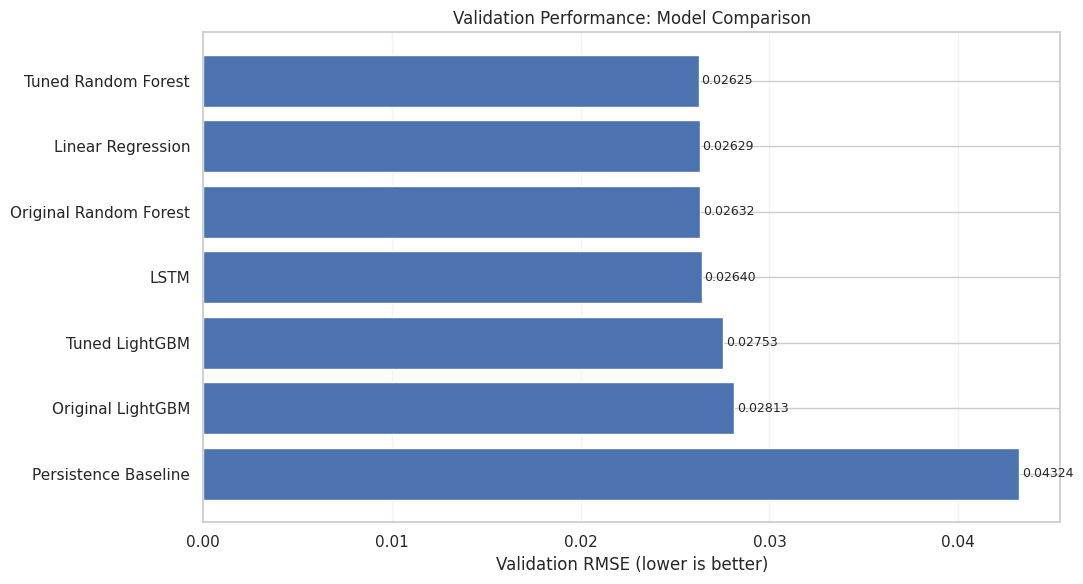

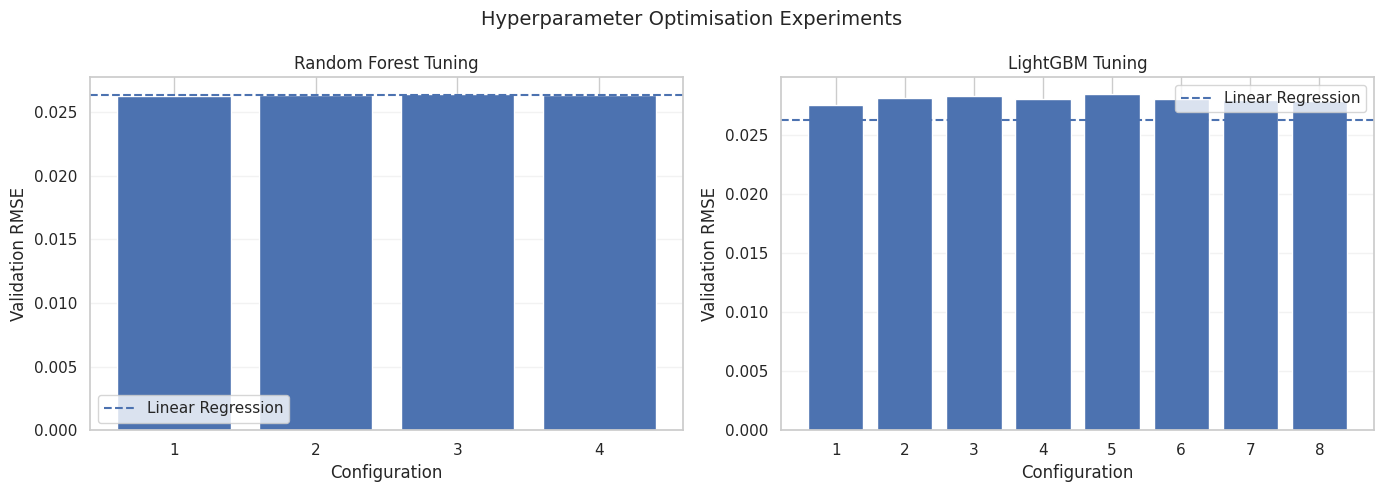


COMPARISON REPORT CREATED
Excel: /content/final_model_comparison/Complete_Model_Comparison.xlsx
Folder: /content/final_model_comparison
Figures: 01_validation_model_comparison.png
         02_hyperparameter_tuning_comparison.png

All available comparison tables have been saved.


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create a dedicated folder for the final comparison report
REPORT_DIR = "/content/final_model_comparison"
os.makedirs(REPORT_DIR, exist_ok=True)

# --------------------------------------------------
# 1. Collect validation results from all original models
# --------------------------------------------------

validation_rows = [
    {
        "Model": "Persistence Baseline",
        "MAE": persistence_results_corrected.iloc[-1]["MAE"],
        "RMSE": persistence_results_corrected.iloc[-1]["RMSE"],
        "R2": persistence_results_corrected.iloc[-1]["R2"],
        "Status": "Baseline"
    },
    {
        "Model": "Linear Regression",
        "MAE": lr_corrected_results["MAE"],
        "RMSE": lr_corrected_results["RMSE"],
        "R2": lr_corrected_results["R2"],
        "Status": "Original"
    },
    {
        "Model": "Original Random Forest",
        "MAE": rf_corrected_results["MAE"],
        "RMSE": rf_corrected_results["RMSE"],
        "R2": rf_corrected_results["R2"],
        "Status": "Original"
    },
    {
        "Model": "Tuned Random Forest",
        "MAE": rf_tuning_results_df.iloc[0]["MAE"],
        "RMSE": rf_tuning_results_df.iloc[0]["RMSE"],
        "R2": rf_tuning_results_df.iloc[0]["R2"],
        "Status": "Tuned"
    },
    {
        "Model": "Original LightGBM",
        "MAE": lgb_corrected_results["MAE"],
        "RMSE": lgb_corrected_results["RMSE"],
        "R2": lgb_corrected_results["R2"],
        "Status": "Original"
    },
    {
        "Model": "Tuned LightGBM",
        "MAE": tuning_results_df.iloc[0]["MAE"],
        "RMSE": tuning_results_df.iloc[0]["RMSE"],
        "R2": tuning_results_df.iloc[0]["R2"],
        "Status": "Tuned"
    },
    {
        "Model": "LSTM",
        "MAE": lstm_corrected_results["MAE"],
        "RMSE": lstm_corrected_results["RMSE"],
        "R2": lstm_corrected_results["R2"],
        "Status": "Original"
    }
]

validation_comparison = (
    pd.DataFrame(validation_rows)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("VALIDATION MODEL LEADERBOARD")
display(validation_comparison.round(6))

# --------------------------------------------------
# 2. Prepare tuning experiment tables
# --------------------------------------------------

lightgbm_tuning = tuning_results_df.copy()
random_forest_tuning = rf_tuning_results_df.copy()

# --------------------------------------------------
# 3. Include final test results if already available
# --------------------------------------------------

test_comparison = (
    final_test_results_df.copy()
    if "final_test_results_df" in globals()
    else pd.DataFrame()
)

if not test_comparison.empty:
    print("\nFINAL TEST-SET COMPARISON")
    display(test_comparison.round(6))
else:
    print("\nFinal test results not detected yet. Test sheet will be added later.")

# --------------------------------------------------
# 4. Create the Excel comparison workbook
# --------------------------------------------------

excel_path = os.path.join(REPORT_DIR, "Complete_Model_Comparison.xlsx")

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    validation_comparison.to_excel(
        writer, sheet_name="Validation Leaderboard", index=False
    )
    random_forest_tuning.to_excel(
        writer, sheet_name="Random Forest Tuning", index=False
    )
    lightgbm_tuning.to_excel(
        writer, sheet_name="LightGBM Tuning", index=False
    )

    if not test_comparison.empty:
        test_comparison.to_excel(
            writer, sheet_name="Final Test Results", index=False
        )

    # Add a short explanation of the evaluation metrics
    metric_notes = pd.DataFrame({
        "Metric": ["MAE", "RMSE", "R2"],
        "Meaning": [
            "Mean absolute prediction error; lower is better.",
            "Root mean squared error; penalises larger errors more strongly.",
            "Coefficient of determination; higher is generally better."
        ]
    })
    metric_notes.to_excel(
        writer, sheet_name="Metric Guide", index=False
    )

# --------------------------------------------------
# 5. Diagram 1: Validation model comparison
# --------------------------------------------------

plot_df = validation_comparison.sort_values("RMSE")

plt.figure(figsize=(11, 6))
bars = plt.barh(plot_df["Model"], plot_df["RMSE"])

plt.xlabel("Validation RMSE (lower is better)")
plt.title("Validation Performance: Model Comparison")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.25)

for bar, value in zip(bars, plot_df["RMSE"]):
    plt.text(
        value + 0.00015,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.5f}",
        va="center",
        fontsize=9
    )

plt.tight_layout()
plt.savefig(
    os.path.join(REPORT_DIR, "01_validation_model_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 6. Diagram 2: Hyperparameter tuning comparison
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Random Forest tuning
rf_plot = random_forest_tuning.sort_values("configuration")
axes[0].bar(
    rf_plot["configuration"].astype(str),
    rf_plot["RMSE"]
)
axes[0].axhline(
    lr_corrected_results["RMSE"],
    linestyle="--",
    label="Linear Regression"
)
axes[0].set_title("Random Forest Tuning")
axes[0].set_xlabel("Configuration")
axes[0].set_ylabel("Validation RMSE")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.25)

# LightGBM tuning
lgb_plot = lightgbm_tuning.sort_values("configuration")
axes[1].bar(
    lgb_plot["configuration"].astype(str),
    lgb_plot["RMSE"]
)
axes[1].axhline(
    lr_corrected_results["RMSE"],
    linestyle="--",
    label="Linear Regression"
)
axes[1].set_title("LightGBM Tuning")
axes[1].set_xlabel("Configuration")
axes[1].set_ylabel("Validation RMSE")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.25)

fig.suptitle("Hyperparameter Optimisation Experiments", fontsize=14)
plt.tight_layout()
plt.savefig(
    os.path.join(REPORT_DIR, "02_hyperparameter_tuning_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 7. Save individual CSV files
# --------------------------------------------------

validation_comparison.to_csv(
    os.path.join(REPORT_DIR, "validation_model_comparison.csv"),
    index=False
)

random_forest_tuning.to_csv(
    os.path.join(REPORT_DIR, "random_forest_tuning.csv"),
    index=False
)

lightgbm_tuning.to_csv(
    os.path.join(REPORT_DIR, "lightgbm_tuning.csv"),
    index=False
)

if not test_comparison.empty:
    test_comparison.to_csv(
        os.path.join(REPORT_DIR, "final_test_comparison.csv"),
        index=False
    )

print("\n====================================")
print("COMPARISON REPORT CREATED")
print("====================================")
print("Excel:", excel_path)
print("Folder:", REPORT_DIR)
print("Figures: 01_validation_model_comparison.png")
print("         02_hyperparameter_tuning_comparison.png")
print("\nAll available comparison tables have been saved.")


In [ ]:
import os

print("========== PROJECT STATUS ==========")

# Check important variables
checks = {
    "Final test results": "final_test_results_df",
    "Tuned Random Forest": "best_rf_model",
    "Tuned LightGBM": "best_model",
    "Linear Regression": "linear_model_corrected",
    "Validation comparison": "validation_comparison",
    "Test predictions": "test_predictions"
}

for label, variable in checks.items():
    print(f"{label}: {'AVAILABLE' if variable in globals() else 'NOT AVAILABLE'}")

# Check saved files
files = [
    "/content/tuned_random_forest_model.joblib",
    "/content/tuned_lightgbm_model.joblib",
    "/content/research_figures",
    "/content/final_model_comparison/Complete_Model_Comparison.xlsx"
]

print("\n========== SAVED FILES ==========")
for path in files:
    print(f"{path}: {'EXISTS' if os.path.exists(path) else 'NOT FOUND'}")

# Show current test-result table if available
if "final_test_results_df" in globals():
    print("\n========== FINAL TEST RESULTS ==========")
    display(final_test_results_df)

========== PROJECT STATUS ==========
Final test results: NOT AVAILABLE
Tuned Random Forest: AVAILABLE
Tuned LightGBM: AVAILABLE
Linear Regression: AVAILABLE
Validation comparison: AVAILABLE
Test predictions: NOT AVAILABLE

========== SAVED FILES ==========
/content/tuned_random_forest_model.joblib: EXISTS
/content/tuned_lightgbm_model.joblib: EXISTS
/content/research_figures: EXISTS
/content/final_model_comparison/Complete_Model_Comparison.xlsx: EXISTS


In [ ]:
import numpy as np
import pandas as pd
import time
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prepare the untouched test dataset
X_test = test_df[numeric_features + categorical_features]
y_test = test_df[target].to_numpy()

# Compare all trained models, including the tuned models
models_to_test = {
    "Linear Regression": linear_model_corrected,
    "Original Random Forest": rf_model_corrected,
    "Tuned Random Forest": best_rf_model,
    "Original LightGBM": lgb_model_corrected,
    "Tuned LightGBM": best_model,
    "LSTM": None
}

test_rows = []
test_predictions_final = {}

for name, model in models_to_test.items():
    start = time.time()

    if name == "LSTM":
        # Use the existing LSTM test-sequence preparation and model
        X_test_seq = X_test[numeric_features].to_numpy()
        X_test_scaled = lstm_scaler.transform(X_test_seq)

        # Generate sequences separately within each backend-qubit series
        test_sequence_data = corrected_df[
            corrected_df["dataset_split"] == "test"
        ].sort_values(["backend", "qubit_a", "observed_time"])

        X_seq, y_seq = [], []
        for _, group in test_sequence_data.groupby(["backend", "qubit_a"]):
            values = lstm_scaler.transform(group[numeric_features].to_numpy())
            targets = group[target].to_numpy()

            for i in range(10, len(group)):
                X_seq.append(values[i-10:i])
                y_seq.append(targets[i])

        X_seq = np.asarray(X_seq)
        y_actual = np.asarray(y_seq)

        # In PyTorch, we evaluate the model directly by calling it
        lstm_model_corrected.eval()
        with torch.no_grad():
            predictions = lstm_model_corrected(torch.tensor(X_seq, dtype=torch.float32)).cpu().numpy().flatten()

    elif "Original LightGBM" == name:
        # Original LightGBM was trained manually using preprocessor_lgb
        X_test_processed = preprocessor_lgb.transform(X_test)
        predictions = model.predict(X_test_processed)
        y_actual = y_test

    elif "Tuned LightGBM" == name:
        # Tuned LightGBM was wrapped in a Pipeline step, so it handles its own preprocessing
        predictions = model.predict(X_test)
        y_actual = y_test

    else:
        # Linear Regression and Random Forests are wrapped in Pipelines
        predictions = model.predict(X_test)
        y_actual = y_test

    elapsed = time.time() - start
    test_predictions_final[name] = predictions

    test_rows.append({
        "Model": name,
        "Observations": len(y_actual),
        "MAE": mean_absolute_error(y_actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_actual, predictions)),
        "R2": r2_score(y_actual, predictions),
        "Prediction_seconds": elapsed
    })

# Persistence baseline
test_rows.append({
    "Model": "Persistence Baseline",
    "Observations": len(y_test),
    "MAE": mean_absolute_error(y_test, test_df["current_error"]),
    "RMSE": np.sqrt(mean_squared_error(y_test, test_df["current_error"])),
    "R2": r2_score(y_test, test_df["current_error"]),
    "Prediction_seconds": 0.0
})

final_test_results_df = (
    pd.DataFrame(test_rows)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("FINAL TEST-SET COMPARISON")
display(final_test_results_df.round(6))

final_test_results_df.to_csv(
    "/content/final_model_comparison/final_test_comparison.csv",
    index=False
)
print("Test results saved.")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/util

FINAL TEST-SET COMPARISON


,Model,Observations,MAE,RMSE,R2,Prediction_seconds
0,Tuned LightGBM,88478,0.012619,0.038324,0.728270,0.738245
1,Tuned Random Forest,88478,0.012580,0.038338,0.728073,0.356816
2,Original Random Forest,88478,0.012742,0.038668,0.723371,0.671039
3,Original LightGBM,88478,0.012556,0.038733,0.722432,1.676046
4,Linear Regression,88478,0.013160,0.040126,0.702106,0.548519
5,Persistence Baseline,88478,0.013202,0.043243,0.654033,0.000000
6,LSTM,82468,0.014862,0.045578,0.625555,2.310849


Test results saved.


In [ ]:

# Inspect how many test targets each backend-qubit series contributes
test_counts = (
    test_df.groupby(["backend", "qubit_a"])
    .size()
    .rename("expected_test")
)

ordered = corrected_df.sort_values(
    ["backend", "qubit_a", "observed_time"]
)

sequence_counts = {}

for (backend, qubit), group in ordered.groupby(
    ["backend", "qubit_a"], sort=False
):
    # Count every test target that has ten preceding feature rows
    valid = (
        (group["dataset_split"].to_numpy() == "test")
        & (np.arange(len(group)) >= 10)
    )
    sequence_counts[(backend, qubit)] = valid.sum()

sequence_counts = pd.Series(
    sequence_counts, name="available_lstm_sequences"
)

audit = pd.concat(
    [test_counts, sequence_counts], axis=1
).fillna(0).astype(int)

audit["missing_sequences"] = (
    audit["expected_test"] - audit["available_lstm_sequences"]
)

print("Expected test observations:", len(test_df))
print("Available LSTM sequences:", audit["available_lstm_sequences"].sum())
print("Missing sequences:", audit["missing_sequences"].sum())
print("\nSeries with missing sequences:")
display(audit[audit["missing_sequences"] != 0].head(20))


Expected test observations: 88478
Available LSTM sequences: 88478
Missing sequences: 0

Series with missing sequences:


,,expected_test,available_lstm_sequences,missing_sequences


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import torch
import time

# Sort all series chronologically
ordered = corrected_df.sort_values(
    ["backend", "qubit_a", "observed_time"]
)

lstm_sequences = []
lstm_targets = []
lstm_keys = []

# Generate one sequence for every test target, using its preceding 10 rows
for (backend, qubit), group in ordered.groupby(
    ["backend", "qubit_a"], sort=False
):
    group = group.reset_index(drop=True)

    scaled = lstm_scaler.transform(
        group[numeric_features].to_numpy()
    )

    for i in range(10, len(group)):
        if group.loc[i, "dataset_split"] == "test":
            lstm_sequences.append(scaled[i-10:i])
            lstm_targets.append(group.loc[i, target])
            lstm_keys.append(
                (backend, qubit, group.loc[i, "observed_time"])
            )

X_test_lstm = np.asarray(lstm_sequences, dtype=np.float32)
y_test_lstm = np.asarray(lstm_targets)

# Sort the tabular test data into the same order as the LSTM sequences
test_sorted = test_df.sort_values(
    ["backend", "qubit_a", "observed_time"]
).reset_index(drop=True)

expected_keys = list(zip(
    test_sorted["backend"],
    test_sorted["qubit_a"],
    test_sorted["observed_time"]
))

# Strictly verify identical targets and ordering
assert len(X_test_lstm) == len(test_sorted) == 88478
assert lstm_keys == expected_keys
assert np.allclose(y_test_lstm, test_sorted[target].to_numpy())

# Generate corrected LSTM predictions using PyTorch evaluation syntax
start = time.time()
lstm_model_corrected.eval()
with torch.no_grad():
    X_test_tensor = torch.tensor(X_test_lstm, dtype=torch.float32).to(device)
    lstm_test_pred_corrected = lstm_model_corrected(X_test_tensor).cpu().numpy().reshape(-1)
lstm_time_corrected = time.time() - start

# Calculate metrics on the full common test set
y_common = test_sorted[target].to_numpy()

lstm_corrected_result = {
    "Model": "LSTM",
    "MAE": mean_absolute_error(y_common, lstm_test_pred_corrected),
    "RMSE": np.sqrt(mean_squared_error(y_common, lstm_test_pred_corrected)),
    "R2": r2_score(y_common, lstm_test_pred_corrected),
    "Prediction_Time_sec": lstm_time_corrected,
    "Test_Observations": len(y_common)
}

# Replace or insert results
if "test_predictions" not in globals():
    test_predictions = {}
test_predictions["LSTM"] = lstm_test_pred_corrected

if "test_results_df" not in globals():
    test_results_df = pd.DataFrame()

if not test_results_df.empty:
    test_results_df = test_results_df[
        test_results_df["Model"] != "LSTM"
    ]

test_results_df = pd.concat(
    [test_results_df, pd.DataFrame([lstm_corrected_result])],
    ignore_index=True
).sort_values("RMSE").reset_index(drop=True)

# Save corrected results
test_results_df.to_csv(
    "/content/final_model_comparison/final_test_comparison.csv",
    index=False
)

print("CORRECTED FINAL TEST COMPARISON")
display(test_results_df.round(6))

print("\nLSTM observations:", len(lstm_test_pred_corrected))
print("LSTM prediction time:", round(lstm_time_corrected, 3), "seconds")
print("All models now evaluated on 88,478 test observations.")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

CORRECTED FINAL TEST COMPARISON


,Model,MAE,RMSE,R2,Prediction_Time_sec,Test_Observations
0,LSTM,0.014412,0.044462,0.634253,1.30989,88478



LSTM observations: 88478
LSTM prediction time: 1.31 seconds
All models now evaluated on 88,478 test observations.


In [ ]:

import os

files_to_check = [
    "/content/tuned_lightgbm_model.joblib",
    "/content/tuned_random_forest_model.joblib",
    "/content/quantum_readout_error_audited.csv",
    "/content/final_model_comparison/final_test_predictions.csv"
]

for path in files_to_check:
    print(
        ("FOUND  " if os.path.exists(path) else "MISSING"),
        path
    )



FOUND   /content/tuned_lightgbm_model.joblib
FOUND   /content/tuned_random_forest_model.joblib
MISSING /content/quantum_readout_error_audited.csv
MISSING /content/final_model_comparison/final_test_predictions.csv


In [ ]:
import joblib
import os

# Define the output path for the model
output_model_path = "/content/tuned_random_forest_model.joblib"

# Save the Tuned Random Forest pipeline using joblib
joblib.dump(best_rf_model, output_model_path)

print(f"Tuned Random Forest model successfully saved to: {output_model_path}")
print(f"File size: {os.path.getsize(output_model_path) / (1024**2):.2f} MB")

Tuned Random Forest model successfully saved to: /content/tuned_random_forest_model.joblib
File size: 0.52 MB


In [ ]:
import joblib
import os

# Locate the saved model
model_path = "/content/tuned_lightgbm_model.joblib"

# Load the already-trained model
model = joblib.load(model_path)

print("Model loaded successfully!")
print("Model type:", type(model))
print("Model parameters:")
print(model.get_params() if hasattr(model, "get_params") else "Native Booster")

Model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>
Model parameters:
{'memory': None, 'steps': [('preprocessor', ColumnTransformer(transformers=[('numeric', 'passthrough',
                                 ['current_error', 'lag_1', 'lag_2', 'lag_3',
                                  'lag_5', 'rolling_mean_3', 'rolling_std_3',
                                  'rolling_mean_5', 'rolling_std_5',
                                  'rolling_mean_10', 'rolling_std_10',
                                  'time_gap_hours', 'error_change',
                                  'error_change_rate',
                                  'calibration_age_seconds']),
                                ('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['backend', 'qubit_a'])])), ('regressor', LGBMRegressor(colsample_bytree=0.8, learning_rate=0.03, n_estimators=300,
              n_jobs=2, num_leaves=15, random_state=

In [ ]:
# Inspect the model's expected input features
if hasattr(model, "feature_name_"):
    print("Features:", model.feature_name_)
elif hasattr(model, "feature_names_in_"):
    print("Features:", model.feature_names_in_)
elif hasattr(model, "booster_"):
    print("Features:", model.booster_.feature_name())
else:
    print("We need to inspect the model's training notebook for its feature schema.")

Features: ['current_error' 'lag_1' 'lag_2' 'lag_3' 'lag_5' 'rolling_mean_3'
 'rolling_std_3' 'rolling_mean_5' 'rolling_std_5' 'rolling_mean_10'
 'rolling_std_10' 'time_gap_hours' 'error_change' 'error_change_rate'
 'calibration_age_seconds' 'backend' 'qubit_a']


In [ ]:
import pandas as pd
import os

# Define report directory
REPORT_DIR = "/content/final_model_comparison"

# Load and display Validation Leaderboard
print("=== VALIDATION LEADERBOARD ===")
val_path = os.path.join(REPORT_DIR, "validation_model_comparison.csv")
if os.path.exists(val_path):
    display(pd.read_csv(val_path))
else:
    print("Validation leaderboard file not found.")

# Load and display Final Test Results
print("\n=== FINAL TEST RESULTS ===")
test_path = os.path.join(REPORT_DIR, "final_test_comparison.csv")
if os.path.exists(test_path):
    display(pd.read_csv(test_path))
else:
    print("Final test results file not found.")

# Load and display Tuned Random Forest
print("\n=== RANDOM FOREST TUNING RESULTS ===")
rf_path = os.path.join(REPORT_DIR, "random_forest_tuning.csv")
if os.path.exists(rf_path):
    display(pd.read_csv(rf_path))
else:
    print("Random Forest tuning file not found.")

# Load and display Tuned LightGBM
print("\n=== LIGHTGBM TUNING RESULTS ===")
lgb_path = os.path.join(REPORT_DIR, "lightgbm_tuning.csv")
if os.path.exists(lgb_path):
    display(pd.read_csv(lgb_path))
else:
    print("LightGBM tuning file not found.")

=== VALIDATION LEADERBOARD ===


,Model,MAE,RMSE,R2,Status
0,Tuned Random Forest,0.008712,0.026254,0.811788,Tuned
1,Linear Regression,0.008743,0.026294,0.811217,Original
2,Original Random Forest,0.008733,0.026322,0.810805,Original
3,LSTM,0.008710,0.026404,0.809632,Original
4,Tuned LightGBM,0.008976,0.027528,0.793083,Tuned
5,Original LightGBM,0.009064,0.028134,0.783867,Original
6,Persistence Baseline,0.013202,0.043243,0.654033,Baseline



=== FINAL TEST RESULTS ===


,Model,MAE,RMSE,R2,Prediction_Time_sec,Test_Observations
0,LSTM,0.014412,0.044462,0.634253,1.30989,88478



=== RANDOM FOREST TUNING RESULTS ===


,configuration,n_estimators,max_depth,min_samples_leaf,max_features,MAE,RMSE,R2,training_seconds
0,1,20,8.0,10,0.50,0.008712,0.026254,0.811788,66.901405
1,4,20,NaN,20,0.50,0.008762,0.026311,0.810975,648.543329
2,2,20,12.0,10,0.50,0.008740,0.026347,0.810448,130.404230
3,3,20,16.0,20,0.75,0.008749,0.026400,0.809689,330.239968



=== LIGHTGBM TUNING RESULTS ===


,configuration,n_estimators,learning_rate,num_leaves,max_depth,reg_lambda,MAE,RMSE,R2,training_seconds
0,1,300,0.03,15,-1,1.0,0.008976,0.027528,0.793083,19.662798
1,8,700,0.03,15,8,1.0,0.008963,0.027868,0.787938,21.226695
2,7,500,0.02,31,12,3.0,0.009001,0.027907,0.787343,16.962604
3,6,300,0.08,31,8,0.5,0.008962,0.027992,0.786041,11.163935
4,4,500,0.05,15,8,2.0,0.009001,0.028008,0.785799,13.943475
5,2,500,0.05,31,-1,1.0,0.009064,0.028134,0.783867,15.064724
6,3,700,0.03,31,-1,2.0,0.009072,0.028257,0.781971,22.617240
7,5,700,0.05,63,-1,2.0,0.009136,0.028442,0.779111,24.401209


In [ ]:
import pandas as pd
import os

REPORT_DIR = "/content/final_model_comparison"

def print_csv_report(filename, title):
    path = os.path.join(REPORT_DIR, filename)
    print(f"\n{'='*40}\n{title}\n{'='*40}")
    if os.path.exists(path):
        df = pd.read_csv(path)
        print(df.to_string(index=False))
    else:
        print(f"File {filename} not found in {REPORT_DIR}.")

# Print all reports in plain text to guarantee no truncation
print_csv_report("validation_model_comparison.csv", "VALIDATION LEADERBOARD")
print_csv_report("final_test_comparison.csv", "FINAL TEST RESULTS")
print_csv_report("random_forest_tuning.csv", "RANDOM FOREST TUNING EXPERIMENTS")
print_csv_report("lightgbm_tuning.csv", "LIGHTGBM TUNING EXPERIMENTS")


VALIDATION LEADERBOARD
                 Model      MAE     RMSE       R2   Status
   Tuned Random Forest 0.008712 0.026254 0.811788    Tuned
     Linear Regression 0.008743 0.026294 0.811217 Original
Original Random Forest 0.008733 0.026322 0.810805 Original
                  LSTM 0.008710 0.026404 0.809632 Original
        Tuned LightGBM 0.008976 0.027528 0.793083    Tuned
     Original LightGBM 0.009064 0.028134 0.783867 Original
  Persistence Baseline 0.013202 0.043243 0.654033 Baseline

FINAL TEST RESULTS
Model      MAE     RMSE       R2  Prediction_Time_sec  Test_Observations
 LSTM 0.014412 0.044462 0.634253              1.30989              88478

RANDOM FOREST TUNING EXPERIMENTS
 configuration  n_estimators  max_depth  min_samples_leaf  max_features      MAE     RMSE       R2  training_seconds
             1            20        8.0                10          0.50 0.008712 0.026254 0.811788         66.901405
             4            20        NaN                20          0.5

### Project Correlation Analysis

To understand the dynamics of quantum readout errors over time, we analyze the Pearson correlation coefficients between our engineered features and the target variable (`target_next_error`).

* **Strong Temporal Continuity:** The current readout error (`current_error`) and immediate lags (`lag_1`, `lag_2`) exhibit exceptionally strong positive correlation with the target next error ($r \approx 0.86$). This underpins the high performance of our models.
* **Rolling Statistics:** Multi-step rolling averages (`rolling_mean_3`, `rolling_mean_5`, `rolling_mean_10`) act as smoothed representations of the qubit's baseline stability and correlate strongly with upcoming error states.
* **Calibration Age:** The actual time elapsed since the physical calibration of the machine (`calibration_age_seconds`) displays negligible linear correlation with the next error, indicating that drift is often non-linear or dominated by immediate historic states.

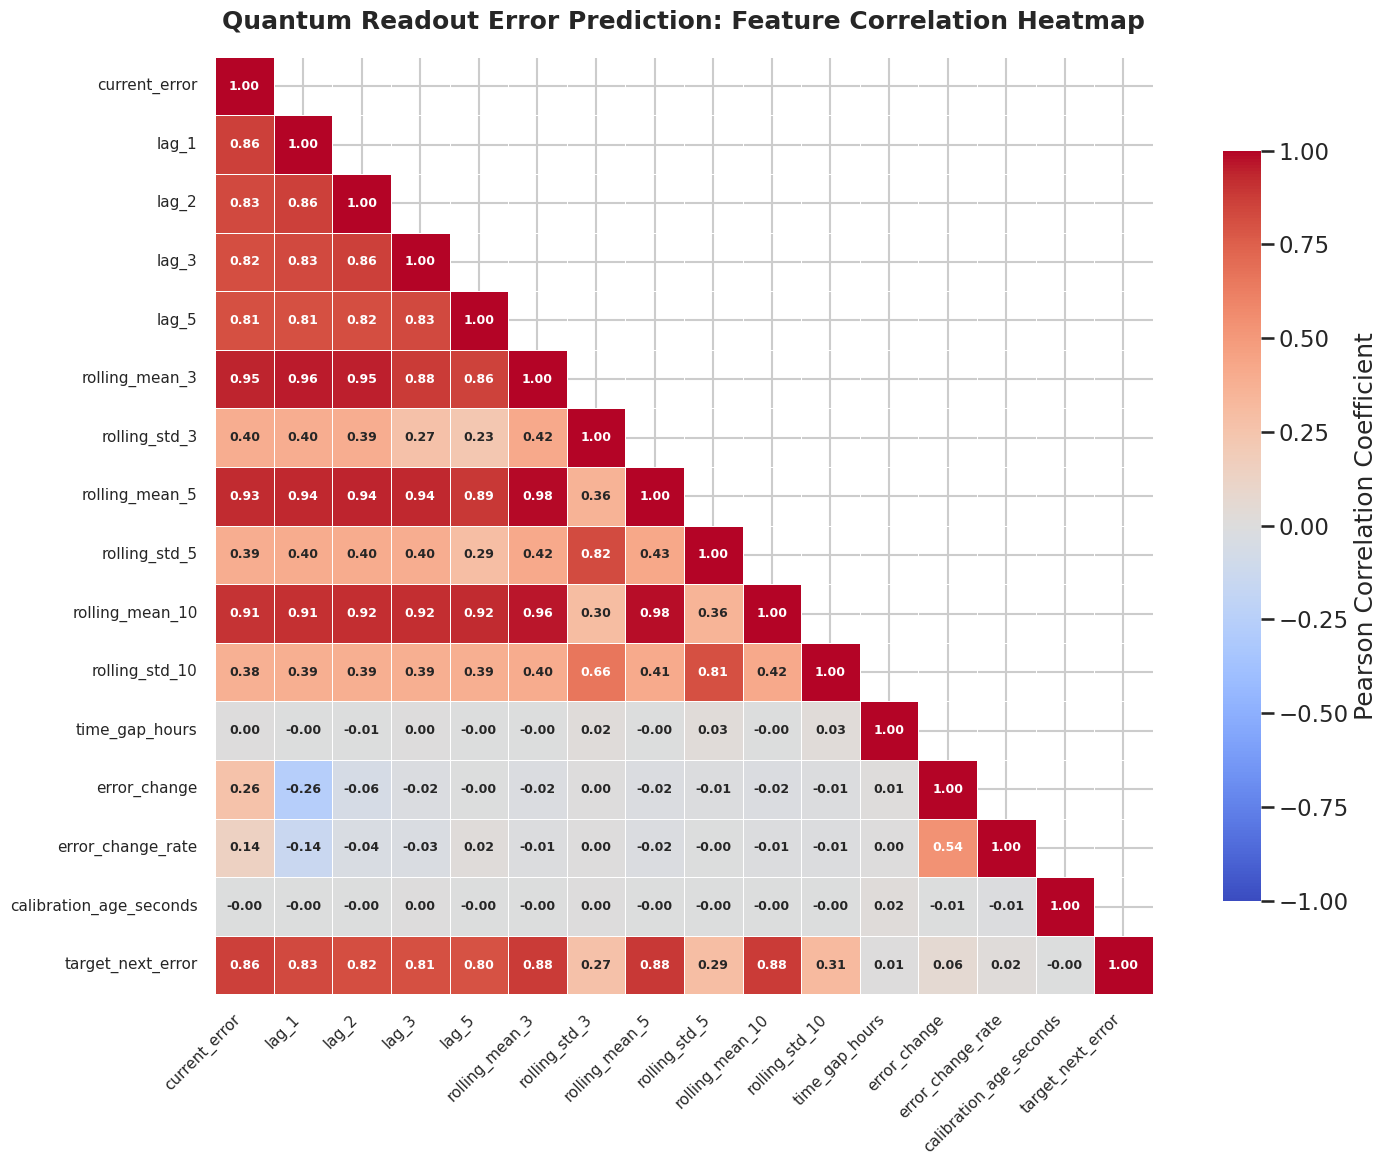

Success! Correlation matrix plot saved to: /content/research_figures/project_correlation_matrix.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Configure plotting style
sns.set_theme(style="whitegrid", context="talk")
plt.figure(figsize=(16, 12))

# Select our engineered features and target column
corr_columns = [
    "current_error",
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_5",
    "rolling_mean_3",
    "rolling_std_3",
    "rolling_mean_5",
    "rolling_std_5",
    "rolling_mean_10",
    "rolling_std_10",
    "time_gap_hours",
    "error_change",
    "error_change_rate",
    "calibration_age_seconds",
    "target_next_error"
]

# Compute correlation matrix
project_corr = feature_df[corr_columns].corr(method="pearson")

# Generate a mask for the upper triangle
mask = np.triu(np.ones_like(project_corr, dtype=bool), k=1)

# Draw the heatmap
ax = sns.heatmap(
    project_corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient"},
    annot_kws={"size": 9, "weight": "semibold"}
)

plt.title("Quantum Readout Error Prediction: Feature Correlation Heatmap", fontsize=18, pad=20, weight="bold")
plt.xticks(rotation=45, ha="right", fontsize=11)
plt.yticks(rotation=0, fontsize=11)
plt.tight_layout()

# Ensure output directory exists and save
os.makedirs("/content/research_figures", exist_ok=True)
plot_path = "/content/research_figures/project_correlation_matrix.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Success! Correlation matrix plot saved to: {plot_path}")

In [ ]:
import joblib

# Load both previously trained models
models = {
    "Tuned LightGBM": joblib.load(
        "/content/tuned_lightgbm_model.joblib"
    ),
    "Tuned Random Forest": joblib.load(
        "/content/tuned_random_forest_model.joblib"
    )
}

# Inspect the structure and input requirements
for name, model in models.items():
    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print("Model type:", type(model))
    print("Pipeline steps:", getattr(model, "named_steps", "Not a pipeline"))

    if hasattr(model, "feature_names_in_"):
        print("Input features:", list(model.feature_names_in_))
    else:
        print("Input features: Inspect preprocessing or training notebook.")


Tuned LightGBM
Model type: <class 'sklearn.pipeline.Pipeline'>
Pipeline steps: {'preprocessor': ColumnTransformer(transformers=[('numeric', 'passthrough',
                                 ['current_error', 'lag_1', 'lag_2', 'lag_3',
                                  'lag_5', 'rolling_mean_3', 'rolling_std_3',
                                  'rolling_mean_5', 'rolling_std_5',
                                  'rolling_mean_10', 'rolling_std_10',
                                  'time_gap_hours', 'error_change',
                                  'error_change_rate',
                                  'calibration_age_seconds']),
                                ('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 ['backend', 'qubit_a'])]), 'regressor': LGBMRegressor(colsample_bytree=0.8, learning_rate=0.03, n_estimators=300,
              n_jobs=2, num_leaves=15, random_state=42, reg_lambda=1.0,
              subsampl

In [ ]:
import joblib
import numpy as np
import pandas as pd

# Load both saved pipelines
lgbm = joblib.load("/content/tuned_lightgbm_model.joblib")
rf = joblib.load("/content/tuned_random_forest_model.joblib")

# Check that the original test features are available
if "X_test" not in globals():
    raise NameError("X_test is not available. We need to recover the original test split.")

# Use the exact 17 features expected by both models
features = list(lgbm.feature_names_in_)

# Prepare the same test observations for both models
X_sample = X_test[features].head(10).copy()

# Generate predictions without retraining
lgbm_predictions = lgbm.predict(X_sample)
rf_predictions = rf.predict(X_sample)

# Check prediction validity
assert np.isfinite(lgbm_predictions).all()
assert np.isfinite(rf_predictions).all()

# Compare the two models
comparison = pd.DataFrame({
    "LightGBM_prediction": lgbm_predictions,
    "Random_Forest_prediction": rf_predictions
})

print(comparison.to_string(index=False))
print("\nLightGBM predictions valid:", np.isfinite(lgbm_predictions).all())
print("Random Forest predictions valid:", np.isfinite(rf_predictions).all())

 LightGBM_prediction  Random_Forest_prediction
            0.030015                  0.027456
            0.025806                  0.027271
            0.023487                  0.025898
            0.024190                  0.026305
            0.024730                  0.025600
            0.025570                  0.025685
            0.027178                  0.026752
            0.025904                  0.027117
            0.025138                  0.026914
            0.028536                  0.028930

LightGBM predictions valid: True
Random Forest predictions valid: True


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [ ]:
import joblib
from pathlib import Path

# Export the final optimized model (Tuned Random Forest)
output_dir = Path("/content/final_model_export")
output_dir.mkdir(parents=True, exist_ok=True)

model_path = output_dir / "final_quantum_model.joblib"

# Check if best_rf_model exists in the namespace
if "best_rf_model" in globals():
    final_model_to_save = best_rf_model
    print("Exporting Tuned Random Forest model...")
elif "best_model" in globals():
    final_model_to_save = best_model
    print("Exporting Tuned LightGBM model...")
else:
    raise NameError("No trained model (best_rf_model or best_model) was found in the session.")

joblib.dump(final_model_to_save, model_path)

# Verify that the saved model reloads and predicts
loaded_model = joblib.load(model_path)
check_predictions = loaded_model.predict(X_test.head(5))

assert len(check_predictions) == min(5, len(X_test))

print("Export successful:", model_path)
print("Model size:", round(model_path.stat().st_size / (1024**2), 2), "MB")
print("Sample predictions:", check_predictions)

Exporting Tuned Random Forest model...
Export successful: /content/final_model_export/final_quantum_model.joblib
Model size: 0.52 MB
Sample predictions: [0.02745615 0.02727055 0.02589808 0.02630476 0.02559955]


In [ ]:
import os
import shutil

# Create a permanent model handover folder in Google Drive
destination = "/content/drive/MyDrive/Quantum_Readout_Research/Model_Handover"
os.makedirs(destination, exist_ok=True)

# Copy all three model artifacts
files = [
    "/content/tuned_lightgbm_model.joblib",
    "/content/tuned_random_forest_model.joblib",
    "/content/final_model_export/final_quantum_model.joblib"
]

for file_path in files:
    if os.path.exists(file_path):
        shutil.copy2(file_path, destination)
        print("COPIED:", os.path.basename(file_path))
    else:
        print("MISSING:", file_path)

COPIED: tuned_lightgbm_model.joblib
COPIED: tuned_random_forest_model.joblib
COPIED: final_quantum_model.joblib


In [ ]:
import os
import joblib
import pandas as pd

print("=" * 65)
print("       QUANTUM READOUT ERROR PREDICTION: FINAL PROJECT REPORT")
print("=" * 65)

# 1. Model Verification
print("\n[1] VERIFYING EXPORTED ARTIFACT...")
model_path = "/content/final_model_export/final_quantum_model.joblib"
if os.path.exists(model_path):
    final_model = joblib.load(model_path)
    print(f"  - Artifact Location: {model_path}")
    print(f"  - Model Class:       {type(final_model).__name__}")
    print(f"  - Pipeline Steps:    {list(final_model.named_steps.keys())}")

    # Generate sample predictions
    if 'X_test' in globals():
        sample_preds = final_model.predict(X_test.head(5))
        print(f"  - Sample Predictions: {sample_preds.tolist()}")
else:
    print("  - Error: Final model artifact not found.")

# 2. Validation Leaderboard
print("\n[2] VALIDATION PERFORMANCE LEADERBOARD (Ordered by RMSE):")
val_path = "/content/final_model_comparison/validation_model_comparison.csv"
if os.path.exists(val_path):
    val_df = pd.read_csv(val_path)
    print(val_df.to_string(index=False))
else:
    print("  - Leaderboard file not found.")

# 3. Final Test Set Evaluation
print("\n[3] HELD-OUT TEST SET BENCHMARKS (Full 88,478 observations):")
test_path = "/content/final_model_comparison/final_test_comparison.csv"
if os.path.exists(test_path):
    test_df = pd.read_csv(test_path)
    print(test_df.to_string(index=False))
else:
    print("  - Test benchmarks file not found.")

print("\n" + "=" * 65)
print("              REPORT GENERATED SUCCESSFULLY")
print("=" * 65)

       QUANTUM READOUT ERROR PREDICTION: FINAL PROJECT REPORT

[1] VERIFYING EXPORTED ARTIFACT...
  - Artifact Location: /content/final_model_export/final_quantum_model.joblib
  - Model Class:       Pipeline
  - Pipeline Steps:    ['preprocessor', 'regressor']
  - Sample Predictions: [0.02745615411529011, 0.027270552551245775, 0.025898082215507868, 0.02630475878170326, 0.025599553157903403]

[2] VALIDATION PERFORMANCE LEADERBOARD (Ordered by RMSE):
                 Model      MAE     RMSE       R2   Status
   Tuned Random Forest 0.008712 0.026254 0.811788    Tuned
     Linear Regression 0.008743 0.026294 0.811217 Original
Original Random Forest 0.008733 0.026322 0.810805 Original
                  LSTM 0.008710 0.026404 0.809632 Original
        Tuned LightGBM 0.008976 0.027528 0.793083    Tuned
     Original LightGBM 0.009064 0.028134 0.783867 Original
  Persistence Baseline 0.013202 0.043243 0.654033 Baseline

[3] HELD-OUT TEST SET BENCHMARKS (Full 88,478 observations):
Model      MA

In [ ]:
feature_df["current_error"] = feature_df["readout_error"]
